In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_analysis import preprocessing
from src.data_analysis import feature_encoding
from src.data_analysis import phase_features
from src.data_analysis import outlier_removal_clustering
from src.data_analysis import genetic_algo
from src.data_analysis import evaluation

ENABLE_PLOTS = True # if false, plots will be saved to file instead of shown
SAVE_PATH_IMG = "./publication/images" # where to save plots
SAVE_PATH_DATA = "./miscellaneous/data" # where to save miscellaneous data such as dataframes
SAVE_PATH_VISUALIZATION = "./miscellaneous/" # where to save preprocessed dataframe for visualization program
LLM_DATA = "./miscellaneous/results_Meta-Llama-3.1-70B-Instruct-Q8_0-00001-of-00002_maxtokens30000_nctx40000_temp0.0_method-guidance.csv" # path to the LLM extracted data
PAPER_DIR = "./downloaded_papers" # directory where the json files of the downloaded papers are, used for sanity checks and validation of llm-extracted data

if not os.path.exists(SAVE_PATH_IMG):
    os.makedirs(SAVE_PATH_IMG)

assert os.path.exists(LLM_DATA), f"LLM_DATA file not found at {LLM_DATA} -> create it before running this script"
assert os.path.exists(SAVE_PATH_IMG), f"SAVE_PATH_IMG not found at {SAVE_PATH_IMG} -> create it before running this script"
assert os.path.exists(SAVE_PATH_DATA), f"SAVE_PATH_DATA not found at {SAVE_PATH_DATA} -> create it before running this script"
assert os.path.exists(SAVE_PATH_VISUALIZATION), f"SAVE_PATH_VISUALIZATION not found at {SAVE_PATH_VISUALIZATION} -> create it before running this script"
if not os.path.exists(PAPER_DIR):
    print(f"WARNING: PAPER_DIR not found at {PAPER_DIR}")
    PAPER_DIR = None

## Preprocess LLM-data

In [2]:
df = preprocessing.get_df(LLM_DATA)

df = preprocessing.filter_duplicates_and_invalid_ys_units(df)
df = preprocessing.get_ys_df(df)
df = preprocessing.parse_non_standard_element_cols(df)

df = preprocessing.parse_chemical_composition_values(df, range_method="mean")
#df = preprocessing.parse_chemical_composition_values(df, range_method="min")
#df = preprocessing.parse_chemical_composition_values(df, range_method="max")

df = preprocessing.convert_valid_element_units_and_replace_bal(df)
df = preprocessing.remove_outliers(df)
df = preprocessing.drop_if_elements_not_sum_to_100(df)
df = preprocessing.remove_duplicated_chem_comps_and_ys(df)
df = preprocessing.filter_non_al_alloys(df)
if PAPER_DIR is not None:
    df = preprocessing.validate_values_in_text(df, PAPER_DIR)
else:
    print("WARNING: PAPER_DIR not found -> skipping validation of values in text")
df = preprocessing.remove_invalid_and_irrelevant_cols(df)
df = preprocessing.select_common_elements(df)
preprocessing.save_df_for_visualization_program(df, SAVE_PATH_VISUALIZATION)

df.head()

dropped 56 rows because the UTS was smaller or equal to the YS!

number of non-nan entries for Al: 7295
n_rows_before: 8195
merging columns with the same name! n_cols_before: 325
replacing Carbon with C (1 entries)
replacing Magnesium with Mg (13 entries)
replacing Aluminium with Al (5 entries)
replacing Silicon with Si (14 entries)
replacing Sulfur with S (2 entries)
replacing Titanium with Ti (1 entries)
replacing Vanadium with V (1 entries)
replacing Chromium with Cr (1 entries)
replacing Manganese with Mn (14 entries)
replacing Iron with Fe (13 entries)
replacing Nickel with Ni (10 entries)
replacing Copper with Cu (10 entries)
replacing Zinc with Zn (13 entries)
replacing Niobium with Nb (1 entries)
replacing Molybdenum with Mo (1 entries)
replacing Tin with Sn (9 entries)
merging columns with the same name! n_cols_after: 293
n_rows_after: 8195
description of the range differences:
count    2355.000000
mean        1.715088
std         8.833773
min         0.000100
25%         0.10

,YS,Ag,Al,B,Cr,Cu,Er,Fe,Li,Mg,...,time 2,time 3,temper designation,file,cooling method 4,cooling method 5,temperature 4,temperature 5,time 4,time 5
0,330.0,NaN,92.445,NaN,NaN,6.30,NaN,0.3,NaN,0.02,...,NaN,NaN,T87,file:///home/pichlmannl/LLMPaperScraping/downl...,NaN,NaN,NaN,NaN,NaN,NaN
1,62.0,NaN,92.445,NaN,NaN,6.30,NaN,0.3,NaN,0.02,...,NaN,NaN,O,file:///home/pichlmannl/LLMPaperScraping/downl...,NaN,NaN,NaN,NaN,NaN,NaN
2,86.0,NaN,92.445,NaN,NaN,6.30,NaN,0.3,NaN,0.02,...,NaN,NaN,NaN,file:///home/pichlmannl/LLMPaperScraping/downl...,NaN,NaN,NaN,NaN,NaN,NaN
3,84.0,NaN,92.445,NaN,NaN,6.30,NaN,0.3,NaN,0.02,...,NaN,NaN,NaN,file:///home/pichlmannl/LLMPaperScraping/downl...,NaN,NaN,NaN,NaN,NaN,NaN
4,270.0,NaN,90.850,NaN,0.03,0.15,NaN,0.2,NaN,5.00,...,NaN,NaN,T6,file:///home/pichlmannl/LLMPaperScraping/downl...,NaN,NaN,NaN,NaN,NaN,NaN


## OH-Encode features where necessary

In [3]:
relevant_cols = preprocessing.get_all_relevant_cols()
skip_feature_generation = False
if skip_feature_generation:
    df_feat = pd.read_csv(os.path.join(SAVE_PATH_DATA, "df_feat_before_genetic_algo.csv"), index_col=0).astype(float)
    targets = pd.read_csv(os.path.join(SAVE_PATH_DATA, "targets_before_genetic_algo.csv"), index_col=0).astype(float)["YS"]
    df_feat_target_file = pd.read_csv(os.path.join(SAVE_PATH_DATA, "df_feat_target_file_before_genetic_algo.csv"), index_col=0)

    remaining_chem_val_cols = [c for c in relevant_cols["chem_val_cols"] if c in df_feat.columns]
    preprocessing.update_relevant_cols("chem_val_cols", remaining_chem_val_cols, verbose=False)
else:
    df_feat, targets = feature_encoding.get_element_df_and_targets(df, relevant_cols)
    df_feat = feature_encoding.process_temper_designation(df_feat, df, relevant_cols)
    df_feat = feature_encoding.process_cooling_method(df_feat, df, relevant_cols)
    df_feat = feature_encoding.process_times(df_feat, df, relevant_cols, max_stages=3)
    df_feat = feature_encoding.process_temperatures(df_feat, df, relevant_cols, max_stages=3)
    df_feat = feature_encoding.process_testing_temp(df_feat, df, relevant_cols)
    df_feat = feature_encoding.process_alloy_type(df_feat, df, relevant_cols)
    feature_encoding.check_features(df_feat, df)
    df_feat_target_file = feature_encoding.add_YS_and_file(df_feat, df)

    df_feat.head()

new feature shape: (5205, 32)
water: 1411
air: 277
other: 166
new feature shape: (5205, 41)
new feature shape: (5205, 44)
new feature shape: (5205, 47)
new feature shape: (5205, 48)
cast: 1198
wrought: 612
other: 342
new feature shape: (5205, 51)

----------
Number of samples: 5205
----------

----------
OH columns
----------
OH__temper_designation__o - 19 samples from 16 different papers
OH__temper_designation__rra - 14 samples from 10 different papers
OH__temper_designation__t3 - 27 samples from 20 different papers
OH__temper_designation__t351 - 29 samples from 19 different papers
OH__temper_designation__t4 - 70 samples from 41 different papers
OH__temper_designation__t5 - 36 samples from 15 different papers
OH__temper_designation__t6 - 528 samples from 254 different papers
OH__temper_designation__t651 - 26 samples from 22 different papers
OH__temper_designation__t7 - 33 samples from 12 different papers
OH__temper_designation__t8 - 52 samples from 30 different papers
OH__temper_desig

## matcalc features

In [4]:
if not skip_feature_generation:
    recalc_matcalc=True
    only_solidus=True
    paths = {
        "featpath": os.path.join(SAVE_PATH_DATA, "df_feat_matcalc.csv"),
        "featpath_solidus": os.path.join(SAVE_PATH_DATA, "df_feat_matcalc_solidus.csv"),
        #"respath_scheil": os.path.join(SAVE_PATH_DATA, "results_scheil"),
        "respath_scheil": None,
        "respath_equ": os.path.join(SAVE_PATH_DATA, "results_equ"),
    }
    os.path.exists(paths["featpath_solidus"])

    #raise NotImplementedError("select equilibrium features only (not scheil) and at 3 different temperatures -> 400C, 500C, 600C?")
    df_feat_matcalc, targets_matcalc = phase_features.get_phase_features(
        recalc_matcalc,
        only_solidus,
        df_feat_target_file["YS"],
        df_feat=df_feat,
        df_all=df,
        relevant_cols=relevant_cols,
        paths=paths
    )
    remaining_chem_val_cols = [c for c in relevant_cols["chem_val_cols"] if c in df_feat_matcalc.columns]
    preprocessing.update_relevant_cols("chem_val_cols", remaining_chem_val_cols, verbose=True)

dropping 1376 rows where we do not have a corresponding scheil/equilibrium calculation
dropped the following columns from chem_val_cols: ['Ag', 'B', 'Er', 'Li', 'Others', 'Pb', 'Sn', 'Sr', 'V']


## on all remaining samples, perform outlier removal using clustering based on chemical composition and corresponding yield strength values

best number of components: 130
number of clusters: 130


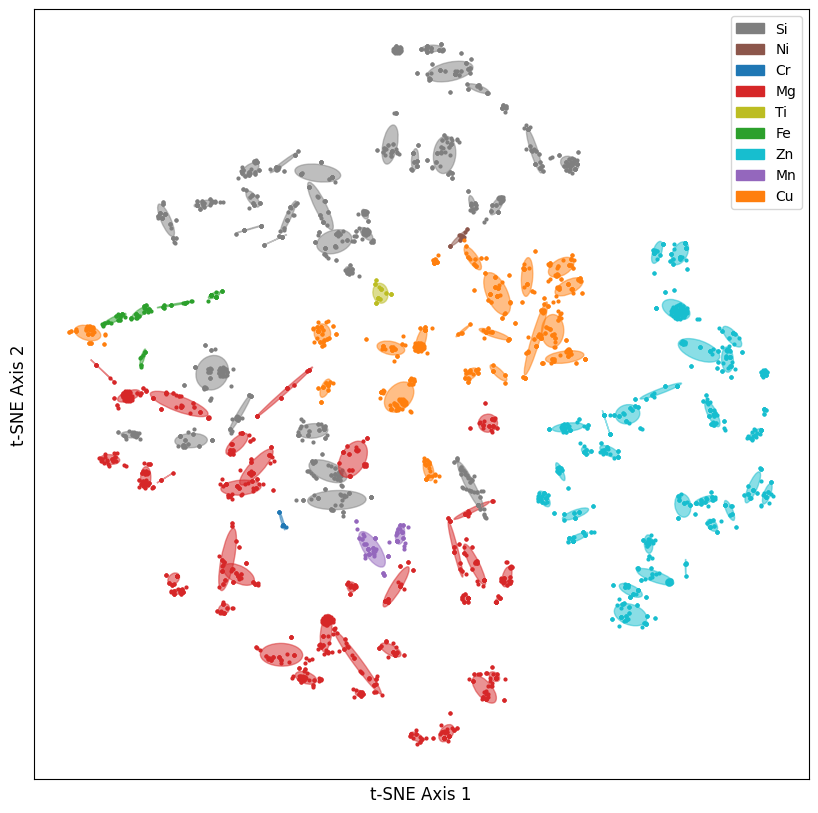

cluster 0 - mean ys: 232.97, std ys: 105.91
removing 19 samples
cluster 1 - mean ys: 168.74, std ys: 115.97
removing 24 samples
cluster 2 - mean ys: 161.55, std ys: 62.14
removing 37 samples
cluster 3 - mean ys: 212.82, std ys: 102.66
removing 34 samples
cluster 4 - mean ys: 510.50, std ys: 169.62
removing 18 samples
cluster 5 - mean ys: 406.53, std ys: 167.14
removing 20 samples
cluster 6 - mean ys: 136.36, std ys: 49.46
removing 15 samples
cluster 7 - mean ys: 262.51, std ys: 169.14
removing 24 samples
cluster 8 - mean ys: 284.13, std ys: 108.00
removing 21 samples
cluster 9 - mean ys: 208.00, std ys: 137.92
removing 44 samples
cluster 10 - mean ys: 321.34, std ys: 130.88
removing 15 samples
cluster 11 - mean ys: 455.65, std ys: 85.67
removing 3 samples
cluster 12 - mean ys: 240.10, std ys: 74.90
removing 12 samples
cluster 13 - mean ys: 157.67, std ys: 78.62
removing 5 samples
cluster 14 - mean ys: 106.13, std ys: 70.14
removing 18 samples
cluster 15 - mean ys: 361.14, std ys: 97.06

In [5]:
if not skip_feature_generation:
    result = outlier_removal_clustering.MoG_clustering(df_feat_matcalc, relevant_cols, min_comp=60, max_comp=150, step=2, selection_method="both")
    x_tsne, labels, gmm, best_n = result["x_tsne"], result["labels"], result["gmm"], result["best_n"]

    from importlib import reload; reload(outlier_removal_clustering)
    #outlier_removal_clustering.plot_results(
    #    x_tsne,
    #    labels,
    #    gmm.means_,
    #    gmm.covariances_,
    #    title=None,
    #    enable_plots=ENABLE_PLOTS,
    #    img_dir=SAVE_PATH_IMG
    #)
    outlier_removal_clustering.plot_results_per_major_alloying_element(
        df_feat_matcalc.copy(), targets_matcalc.copy(), relevant_cols["chem_val_cols"],
        x_tsne,
        labels,
        gmm.means_,
        gmm.covariances_,
        title=None,
        enable_plots=ENABLE_PLOTS,
        img_dir=SAVE_PATH_IMG
    )

    df_feat, targets = outlier_removal_clustering.remove_outliers_in_clusters(
            df_feat_matcalc, targets_matcalc, labels, relevant_cols, thr_rel=0.25, thr_abs=100
    )

    remaining_chem_val_cols = [c for c in relevant_cols["chem_val_cols"] if c in df_feat.columns]
    preprocessing.update_relevant_cols("chem_val_cols", remaining_chem_val_cols, verbose=True)

## Add elemental features

#### for reference see https://www.sciencedirect.com/science/article/pii/S0921509324013121#mmc1

- D5 ... Zunger pseudopotential radius (a.u.) [8]
- T1 ... Melting Temperature (K) [1]
- P2 ... Shear modulus (GPa) [1]
- D8 ... Lattice c [1]
- D6 ... Lattice a [1]
- E8 ... Electron affinity (kJ/mol) [1]

[1] ... https://www.schoolmykids.com/learn/periodic-table-of-elements
[8] ... A. Zunger, Systematization of the stable crystal structure of all AB-type binary compounds: A pseudopotential orbital-radii approach, Physical Review B 22(12) (1980) 5839.

- link to corresponding paper: https://www.researchgate.net/publication/243427460_Systematization_of_the_stable_crystal_structure_of_all_AB-type_binary_compounds_A_pseudopotential_orbital-radii_approach
    - however they specify 3 radii: r_s, r_p, r_d (corresponding to s, p, d orbitals)
    - I guess in the paper where they used this as a feature they calculate an average from these values? It is not mentioned in the paper unfortunately
    - -> take values from https://www.sciencedirect.com/science/article/pii/0925838895016058 or compute them as they did there
        - "the weighted average pseudopotential radii which are calculated from Zunger's s and p pseudopotential radii by considering the outermost electronic configuration"
        - e.g. N has an electron configuration of 2s2 2p3 (s^2p^2), and the atomic pseudopotentials for the r_s and r_p are 0.33 and 0.21 respectively -> the average is then calculated via (2*0.33 + 3*0.21) / 5 = 0.258
        - if electron config is 2s2 3p2, then only the p is considered for the average, since it has the highest l-value (3 > 2)
    - electron configurations were then taken from https://en.wikipedia.org/wiki/Electron_configurations_of_the_elements_(data_page)

## Compute weighted Zunger pseudopotential radii for each element

In [6]:
relevant_cols["chem_val_cols"]

table = """
Li   0.985   0.625   -   
Be   0.64    0.44    -  
B    0.48    0.315   -   
C    0.39    0.25    -  
N    0.33    0.21    -  
0    0.285   0.18    -  
p    0.25    0.155   -   
Ne   0.22    0.14    -  
Na   1.10    1.55    -  
Mg   0.90    1.13     - 
Al   0.77    0.905   -   
Si   0.68    0.74    -  
P    0.60    0.64    -  
S    0.54    0.56    -  
Cl   0.50    0.51    -  
Ar   0.46    0.46    -  
K    1.54    2.15    0.37
Ca   1.32    1.68    0.34
Sc   1.22    1.53    0.31
Ti   1.15    1.43    0.28
V    1.09    1.34    0.26
Cr   1.07    1.37    0.25
Mn   0.99    1.23    0.23
Fe   0.95    1.16    0.22
Co   0.92    1.10    0.21
Ni   0.96    1.22    0.195
Cu   0.88    1.16    0.185
Zn   0.82    1.06    0.175
Ga   0.76    0.935   0.17  
Ge   0.72    0.84    0.16
As   0.67    0.745   0.155 
Se   0.615   0.67    0.15
Br   0.58    0.62    0.143
Kr   0.56    0.60    0.138
Rb   1.67    2.43    0.71
Sr   1.42    1.79    0.633                                 
Y    1.32    1.62    0.58                                  
Zr   1.265   1.56    0.54                                   
Nb   1.23    1.53    0.51                                  
Mo   1.22    1.50    0.49                                  
Tc   1.16    1.49    0.455                                 
Bu   1.145   1.46    0.45                                   
Rh   1.11    1.41    0.42                                  
Pd   1.08    1.37    0.40                                  
Ag   1.045   1.33    0.385                                  
Cd   0.985   1.23    0.37                                   
In   0.94    1.11    0.36                                  
Sn   0.88    1.00    0.345                                 
Sb   0.83    0.935   0.335                                 
Te   0.79    0.88    0.325                                 
I    0.755   0.83    0.315                                  
Xe   0.75    0.81    0.305                                 
Cs   1.71    2.60    -                                
Ba   1.515   1.887   0.94                                  
La   1.375   1.705   0.874                                 
Hf   1.30    1.61    0.63                                 
Ta   1.25    1.54    0.605                                
W    1.22    1.515   0.59                                 
Re   1.19    1.49    0.565                                
Os   1.17    1.48    0.543                                
Ir   1.16    1.468   0.526                                
Pt   1.24    1.46    0.51                                 
Au   1.21    1.45    0.488                                
Hg   1.07    1.34    0.475                                
Tl   1.015   1.22    0.463                                 
Pb   0.96    1.13    0.45                                 
Bi   0.92    1.077   0.438                                
Po   0.88    1.02    0.425                                
At   0.85    0.98    0.475                                
Rn   0.84    0.94    0.405                           
"""

radii = {}
for line in table.strip().split("\n"):
    el, r_s, r_p, r_d = line.strip().replace("-", "nan").split()
    radii[el] = {"r_s": float(r_s), "r_p": float(r_p), "r_d": float(r_d)}

In [7]:
import requests
from bs4 import BeautifulSoup
import re
import pandas as pd

link = "https://en.wikipedia.org/wiki/Electron_configurations_of_the_elements_(data_page)"
response = requests.get(link)
soup = BeautifulSoup(response.text, "html.parser")

# find the table (class wikitable)
table = soup.find("table", {"class": "wikitable"})

# find all elements with a title
titles = table.find_all("a", {"title": True})
# get the parents of the titles
parents = [el.parent.text for el in titles]
# e.g.: "57 La lanthanum\xa0: [Xe] 5d1 ...\n'
symbols = [re.match(r"^\d+ (.+?) ", el).group(1) for el in parents]

# get all rows of the table where <sup> occurs somewhere
rows = table.find_all("tr")
rows = [row for row in rows if row.find("sup") is not None and row.find("th") is None]

# now convert these rows into a pandas dataframe
data = []
td_match = re.compile(r"<td>(.*?)</td>", re.DOTALL)
for row in rows:
    # extract contents between each <td></td>
    row = str(row)
    data.append([re.findall(td_match, row)[i] for i in range(19)])

cols = "1s	2s	2p	3s	3p	3d	4s	4p	4d	4f	5s	5p	5d	5f	6s	6p	6d	7s	7p".split()
df = pd.DataFrame(data, columns=cols, index=symbols)

sup_match = re.compile(r"<sup>(.*?)</sup>", re.DOTALL)
df = df.applymap(lambda x: 0 if not re.search(sup_match, x) else int(re.search(sup_match, x).group(1)))

#df_relevant = df.loc[relevant_cols["chem_val_cols"]]
#assert (df_relevant[[el for el in df_relevant.columns if "f" in el]] == 0).all().all(), "we don't have zunger pseudopotential radii for f orbitals"

n_in_highest_orbitals = {}
for el in df.index:
    row = df.loc[el]

    # make sure we don't have an f orbital
    if (row[[el for el in row.index if "f" in el]] > 0).any():
        print(f"skipping {el}, has f orbital")
        continue

    highest_l = max([int(re.match(r"^(\d+)[spd]$", el).group(1)) for el in row[row > 0].index])
    scol = f"{highest_l}s"
    pcol = f"{highest_l}p"
    dcol = f"{highest_l}d"

    n_in_highest_orbitals[el] = {
        "s": int(row[scol]) if scol in row else 0,
        "p": int(row[pcol]) if pcol in row else 0,
        "d": int(row[dcol]) if dcol in row else 0
    }

print("\nnumber of electrons in highest orbitals:")
for el in n_in_highest_orbitals.keys():
    print(el, n_in_highest_orbitals[el])

print("\nradii for relevant elements:")
for el in n_in_highest_orbitals.keys():
    if el not in radii:
        continue
    
    print(el, radii[el])

skipping Ce, has f orbital
skipping Pr, has f orbital
skipping Nd, has f orbital
skipping Pm, has f orbital
skipping Sm, has f orbital
skipping Eu, has f orbital
skipping Gd, has f orbital
skipping Tb, has f orbital
skipping Dy, has f orbital
skipping Ho, has f orbital
skipping Er, has f orbital
skipping Tm, has f orbital
skipping Yb, has f orbital
skipping Lu, has f orbital
skipping Hf, has f orbital
skipping Ta, has f orbital
skipping W, has f orbital
skipping Re, has f orbital
skipping Os, has f orbital
skipping Ir, has f orbital
skipping Pt, has f orbital
skipping Au, has f orbital
skipping Hg, has f orbital
skipping Tl, has f orbital
skipping Pb, has f orbital
skipping Bi, has f orbital
skipping Po, has f orbital
skipping At, has f orbital
skipping Rn, has f orbital
skipping Fr, has f orbital
skipping Ra, has f orbital
skipping Ac, has f orbital
skipping Th, has f orbital
skipping Pa, has f orbital
skipping U, has f orbital
skipping Np, has f orbital
skipping Pu, has f orbital
ski

In [8]:
# compute weighted Zunger pseudopotential radii for each element
D5 = {}
for el in n_in_highest_orbitals.keys():
    if el not in radii:
        print(f"skipping {el}, not contained in the Zunger pseudopotential radii")
        continue

    n_s = n_in_highest_orbitals[el]["s"]
    n_p = n_in_highest_orbitals[el]["p"]
    n_d = n_in_highest_orbitals[el]["d"]
    r_s = radii[el]["r_s"] if radii[el]["r_s"] > 0 else 0
    r_p = radii[el]["r_p"] if radii[el]["r_p"] > 0 else 0
    r_d = radii[el]["r_d"] if radii[el]["r_d"] > 0 else 0

    r_weighted = (n_s * r_s + n_p * r_p + n_d * r_d) / (n_s + n_p + n_d)
    D5[el] = float(r_weighted)

D5

skipping H, not contained in the Zunger pseudopotential radii
skipping He, not contained in the Zunger pseudopotential radii
skipping O, not contained in the Zunger pseudopotential radii
skipping F, not contained in the Zunger pseudopotential radii
skipping Ru, not contained in the Zunger pseudopotential radii


{'Li': 0.985,
 'Be': 0.64,
 'B': 0.425,
 'C': 0.32,
 'N': 0.258,
 'Ne': 0.16,
 'Na': 1.1,
 'Mg': 0.9,
 'Al': 0.8150000000000001,
 'Si': 0.71,
 'P': 0.624,
 'S': 0.5533333333333333,
 'Cl': 0.5071428571428571,
 'Ar': 0.46,
 'K': 1.54,
 'Ca': 1.32,
 'Sc': 1.22,
 'Ti': 1.15,
 'V': 1.09,
 'Cr': 1.07,
 'Mn': 0.99,
 'Fe': 0.95,
 'Co': 0.92,
 'Ni': 0.96,
 'Cu': 0.88,
 'Zn': 0.82,
 'Ga': 0.8183333333333334,
 'Ge': 0.78,
 'As': 0.7150000000000001,
 'Se': 0.6516666666666667,
 'Br': 0.6085714285714285,
 'Kr': 0.59,
 'Rb': 1.67,
 'Sr': 1.42,
 'Y': 1.32,
 'Zr': 1.265,
 'Nb': 1.23,
 'Mo': 1.22,
 'Tc': 1.16,
 'Rh': 1.11,
 'Pd': 0.798888888888889,
 'Ag': 1.045,
 'Cd': 0.985,
 'In': 0.9966666666666667,
 'Sn': 0.94,
 'Sb': 0.893,
 'Te': 0.85,
 'I': 0.8085714285714285,
 'Xe': 0.795,
 'Cs': 1.71,
 'Ba': 1.515,
 'La': 1.375}

In [9]:
D5 = {k: v for k, v in D5.items() if k in relevant_cols["chem_val_cols"]}

T1 ... Melting Temperature (K) [1]
P2 ... Shear modulus (GPa) [1]
D8 ... Lattice c [1]
D6 ... Lattice a [1]
E8 ... Electron affinity (kJ/mol) [1]

In [10]:
import time
#https://www.schoolmykids.com/learn/periodic-table/al-aluminium
baselink = "https://www.schoolmykids.com/learn/periodic-table/"
postfixes = [
    "Al-aluminium",
    "Cr-chromium",
    "Cu-copper",
    "Fe-iron",
    "Mg-magnesium",
    "Mn-manganese",
    "Ni-nickel",
    "Sc-scandium",
    "Si-silicon",
    "Ti-titanium",
    "Zn-zinc",
    "Zr-zirconium"
]

if not os.path.exists(os.path.join(SAVE_PATH_DATA, "pages.pkl")):
    pages = {}
    for pf in postfixes:
        print(f"fetching {pf}")
        el = pf.split("-")[0]
        time.sleep(1)
        link = baselink + pf
        response = requests.get(link)
        pages[el] = response.text

    import pickle
    with open(os.path.join(SAVE_PATH_DATA, "pages.pkl"), "wb") as f:
        pickle.dump(pages, f)

    print("done fetching pages")
else:
    import pickle
    with open(os.path.join(SAVE_PATH_DATA, "pages.pkl"), "rb") as f:
        pages = pickle.load(f)

In [11]:
# the following fallback values for the shear modulus are taken from: https://www.azom.com/properties.aspx?ArticleID=1851 and https://www.azom.com/article.aspx?ArticleID=9102
special_shear_modulus = {"Mn": 76.4, "Si": 61.5}

element_features = {k: {"D5": D5[k]} for k in D5.keys()}
for element_name, page in pages.items():
    soup = BeautifulSoup(page, "html.parser")

    # atomic weight
    el = soup.find_all("a", text="Atomic Weight") # find a href where the text is "Atomic Weight"
    assert len(el) == 1, "should find exactly one element"
    el = el[0]
    atomic_weight = el.parent.find_next_sibling().text
    element_features[element_name]["atomic_weight"] = float(atomic_weight)

    # electronic config
    el = soup.find_all("a", text="Electron Configuration")
    assert len(el) == 1, "should find exactly one element"
    el = el[0]
    electronic_config = el.parent.find_next_sibling().text
    element_features[element_name]["electronic_config"] = electronic_config

    # Shear Modulus
    el = soup.find_all("a", text="Shear Modulus")
    assert len(el) == 1, "should find exactly one element"
    el = el[0]
    shear_modulus = el.parent.find_next_sibling().text
    try:
        shear_modulus = re.match(r"(\d+[.]*\d* GPa)", shear_modulus).group(1)
        element_features[element_name]["P2"] = float(shear_modulus.replace(" GPa", ""))
    except AttributeError:
        shear_modulus = special_shear_modulus[element_name]
        element_features[element_name]["P2"] = shear_modulus

    # melting point
    el = soup.find_all("a", text="Melting Point")
    if len(el) > 1:
        prev = re.match(r"(\d+.\d+)", el[0].parent.find_next_sibling().text).group(1)
        for t in el[1:]:
            melting_point = re.match(r"(\d+.\d+)", t.parent.find_next_sibling().text).group(1)
            assert melting_point == prev, "melting points should be the same"
    elif len(el) == 0:
        raise AssertionError("should find atleast one element, and all should have the same melting point")

    el = el[0]
    melting_point = el.parent.find_next_sibling().text
    element_features[element_name]["T1"] = float(melting_point.replace(" K", ""))

    # lattice parameters
    # find a table with 3 columns with the names "a", "b", "c"
    el = soup.find_all("table")
    el = [el for el in el if len(el.find_all("th")) == 3]
    el = [el for el in el if el.find_all("th")[0].text == "a" and el.find_all("th")[1].text == "b" and el.find_all("th")[2].text == "c"]
    assert len(el) == 1, "should find exactly one element"
    el = el[0]
    lattice_params = [float(el.text.replace(" pm", "")) for el in el.find_all("td")]
    lattice_params = {el: lattice_params[i] for i, el in enumerate(["a", "b", "c"])}
    element_features[element_name]["D6"] = lattice_params["a"]
    element_features[element_name]["D8"] = lattice_params["c"]

    # electron affinity
    el = soup.find_all("a", text="ElectronAffinity")
    assert len(el) == 1, "should find exactly one element"
    el = el[0]
    electron_affinity = el.parent.find_next_sibling().text
    element_features[element_name]["E8"] = float(electron_affinity.replace(" kJ/mol", ""))

element_features

{'Mg': {'D5': 0.9,
  'atomic_weight': 24.305,
  'electronic_config': '[Ne] 3s2 ',
  'P2': 17.0,
  'T1': 923.0,
  'D6': 320.94,
  'D8': 521.08,
  'E8': 0.0},
 'Al': {'D5': 0.8150000000000001,
  'atomic_weight': 26.981538,
  'electronic_config': '[Ne] 3s2 3p1 ',
  'P2': 26.0,
  'T1': 933.47,
  'D6': 404.95,
  'D8': 404.95,
  'E8': 42.5},
 'Si': {'D5': 0.71,
  'atomic_weight': 28.0855,
  'electronic_config': '[Ne] 3s2 3p2 ',
  'P2': 61.5,
  'T1': 1687.0,
  'D6': 543.09,
  'D8': 543.09,
  'E8': 133.6},
 'Sc': {'D5': 1.22,
  'atomic_weight': 44.95591,
  'electronic_config': '[Ar] 3d1 4s2 ',
  'P2': 29.0,
  'T1': 1814.0,
  'D6': 330.9,
  'D8': 527.33,
  'E8': 18.1},
 'Ti': {'D5': 1.15,
  'atomic_weight': 47.867,
  'electronic_config': '[Ar] 3d2 4s2 ',
  'P2': 44.0,
  'T1': 1941.0,
  'D6': 295.08,
  'D8': 468.55,
  'E8': 7.6},
 'Cr': {'D5': 1.07,
  'atomic_weight': 51.9961,
  'electronic_config': '[Ar] 3d5 4s1 ',
  'P2': 115.0,
  'T1': 2180.0,
  'D6': 291.0,
  'D8': 291.0,
  'E8': 64.3},
 'Mn

## make sure the electronic configurations matches with the number of electrons in the highest orbitals

In [12]:
print("number of electrons in highest orbitals:")
for el in n_in_highest_orbitals.keys():
    print(el, n_in_highest_orbitals[el])

print("\nelectronic configurations:")
for el in element_features.keys():
    print(el, element_features[el]["electronic_config"])

number of electrons in highest orbitals:
H {'s': 1, 'p': 0, 'd': 0}
He {'s': 2, 'p': 0, 'd': 0}
Li {'s': 1, 'p': 0, 'd': 0}
Be {'s': 2, 'p': 0, 'd': 0}
B {'s': 2, 'p': 1, 'd': 0}
C {'s': 2, 'p': 2, 'd': 0}
N {'s': 2, 'p': 3, 'd': 0}
O {'s': 2, 'p': 4, 'd': 0}
F {'s': 2, 'p': 5, 'd': 0}
Ne {'s': 2, 'p': 6, 'd': 0}
Na {'s': 1, 'p': 0, 'd': 0}
Mg {'s': 2, 'p': 0, 'd': 0}
Al {'s': 2, 'p': 1, 'd': 0}
Si {'s': 2, 'p': 2, 'd': 0}
P {'s': 2, 'p': 3, 'd': 0}
S {'s': 2, 'p': 4, 'd': 0}
Cl {'s': 2, 'p': 5, 'd': 0}
Ar {'s': 2, 'p': 6, 'd': 0}
K {'s': 1, 'p': 0, 'd': 0}
Ca {'s': 2, 'p': 0, 'd': 0}
Sc {'s': 2, 'p': 0, 'd': 0}
Ti {'s': 2, 'p': 0, 'd': 0}
V {'s': 2, 'p': 0, 'd': 0}
Cr {'s': 1, 'p': 0, 'd': 0}
Mn {'s': 2, 'p': 0, 'd': 0}
Fe {'s': 2, 'p': 0, 'd': 0}
Co {'s': 2, 'p': 0, 'd': 0}
Ni {'s': 2, 'p': 0, 'd': 0}
Cu {'s': 1, 'p': 0, 'd': 0}
Zn {'s': 2, 'p': 0, 'd': 0}
Ga {'s': 2, 'p': 1, 'd': 0}
Ge {'s': 2, 'p': 2, 'd': 0}
As {'s': 2, 'p': 3, 'd': 0}
Se {'s': 2, 'p': 4, 'd': 0}
Br {'s': 2, 'p': 

## finally compute the features for each sample like they did in https://www.sciencedirect.com/science/article/pii/S0921509324013121#mmc1

In [13]:
def calculate_element_features(df, chem_val_cols):
    df = df.copy()
    f_mean = lambda at_perc, val: np.sum(at_perc * val)
    f_std = lambda at_perc, val, mean: np.sqrt(np.sum(      (val - mean)**2 * at_perc))
    f_mad = lambda at_perc, val, mean:          np.sum(np.abs(val - mean)    * at_perc)
    f_mis = lambda at_perc, val, mean: np.sqrt(np.sum((1 - val/mean)**2 * at_perc))
    f_ad = lambda at_perc, val, val_al: np.sum(np.abs(val - val_al) * at_perc)

    at_weights = np.array([element_features[el]["atomic_weight"] for el in chem_val_cols])
    D5_vals = np.array([element_features[el]["D5"] for el in chem_val_cols])
    T1_vals = np.array([element_features[el]["T1"] for el in chem_val_cols])
    D6_vals = np.array([element_features[el]["D6"] for el in chem_val_cols])
    D8_vals = np.array([element_features[el]["D8"] for el in chem_val_cols])
    E8_vals = np.array([element_features[el]["E8"] for el in chem_val_cols])
    P2_vals = np.array([element_features[el]["P2"] for el in chem_val_cols])
    for row_idx, row in df.fillna(0).iterrows():
        wt_perc = row[chem_val_cols]/100
        idx_al = chem_val_cols.index("Al")
        at_perc = wt_perc / at_weights
        at_perc /= np.sum(at_perc)
        for type_, vals in zip(["D5", "T1", "D6", "D8", "E8", "P2"], [D5_vals, T1_vals, D6_vals, D8_vals, E8_vals, P2_vals]):
            mean = f_mean(at_perc, vals)
            df.loc[row_idx, f"{type_}_mean"] = mean
            df.loc[row_idx, f"{type_}_std"] = f_std(at_perc, vals, mean)
            df.loc[row_idx, f"{type_}_mis"] = f_mis(at_perc, vals, mean)
            df.loc[row_idx, f"{type_}_mad"] = f_mad(at_perc, vals, mean)

            at_perc_non_al = list(at_perc)
            at_perc_non_al.pop(idx_al)
            vals_non_al = list(vals)
            val_al = vals[idx_al]
            vals_non_al.pop(idx_al)
            df.loc[row_idx, f"{type_}_ad"] = f_ad(at_perc_non_al, vals_non_al, val_al)

    return df

if not skip_feature_generation:
    df_feat = calculate_element_features(df_feat, relevant_cols["chem_val_cols"])
    df_feat.iloc[:, -20:].describe()

## Aggregation of phase features (single phases as features didn't work well)

In [14]:
# Chromium based subclusters
chromium_based_cr_al = ["AL4CR", "AL11CR2", "AL13CR2", "ALCRCU_TAU", "AL18CR2MG3"]
chromium_based_cr_si = ["ALCRSI_T3", "AL13CR4SI4", "AL58CR31SI11"]
ALCRCU_TAU = ["ALCRCU_TAU"]
chromium_based_all = chromium_based_cr_al + chromium_based_cr_si + ALCRCU_TAU

# Iron based subclusters
iron_based_fe_cu = ["AL7CU2FE", "AL23CUFE4"]
iron_based_fe_si = ["ALFESI_T6", "ALCRFEMNSI_A", "AL8FEMNSI2"]
iron_based_fe_mn = ["AL13FE4", "ALFEMNSI_B"]
ALFENI_T1 = ["ALFENI_T1"]
iron_based_all = iron_based_fe_cu + iron_based_fe_si + iron_based_fe_mn + ALFENI_T1

# Nickel based subclusters
AL3NI = ["AL3NI"]

# Magnesium based subclusters
magnesium_based_mg_si = ["MG2SI_B", "PI_ALFEMGSI", "Q_PHASE_L", "Q_PHASE_H"]
MGALCUZN_T = ["MGALCUZN_T"]
magnesium_based_all = magnesium_based_mg_si + MGALCUZN_T

# Silicon based subclusters
silicon_based_si_al = ["ALCRSI_T3", "AL13CR4SI4", "AL58CR31SI11", "Q_PHASE_L", "Q_PHASE_H"]
SI2ZR = ["SI2ZR"]
silicon_based_all = silicon_based_si_al + SI2ZR

# Titanium based subclusters
titanium_based_ti_al = ["AL3TI_H", "AL3TI_L"]

# Copper based subclusters
copper_based_cu_al = ["THETA_AL2CU", "S_PHASE"]

# Zirconium based subclusters
AL3ZR = ["AL3ZR"]
SI2ZR = ["SI2ZR"]
zirconium_based_all = AL3ZR + SI2ZR

# Scandium based subclusters
scandium_based_sc_al = ["ALSC", "AL2SC", "AL3SC"]

# Manganese based subclusters
AL12MN = ["AL12MN"]
manganese_based_mn_fe = ["AL13FE4", "ALFEMNSI_B"]
manganese_based_all = AL12MN + manganese_based_mn_fe

# Independent cluster
keep_alone = ["SI_DIAMOND_A4"]

print(" ".join([el.replace("_", "\\_") for el in chromium_based_cr_al]))
print(" ".join([el.replace("_", "\\_") for el in chromium_based_cr_si]))
print(" ".join([el.replace("_", "\\_") for el in ALCRCU_TAU]))

print(" ".join([el.replace("_", "\\_") for el in iron_based_fe_cu]))
print(" ".join([el.replace("_", "\\_") for el in iron_based_fe_si]))
print(" ".join([el.replace("_", "\\_") for el in iron_based_fe_mn]))
print(" ".join([el.replace("_", "\\_") for el in ALFENI_T1]))

print(" ".join([el.replace("_", "\\_") for el in AL3NI]))

print(" ".join([el.replace("_", "\\_") for el in magnesium_based_mg_si]))
print(" ".join([el.replace("_", "\\_") for el in MGALCUZN_T]))

print(" ".join([el.replace("_", "\\_") for el in silicon_based_si_al]))
print(" ".join([el.replace("_", "\\_") for el in SI2ZR]))

print(" ".join([el.replace("_", "\\_") for el in titanium_based_ti_al]))

print(" ".join([el.replace("_", "\\_") for el in copper_based_cu_al]))

print(" ".join([el.replace("_", "\\_") for el in AL3ZR]))
print(" ".join([el.replace("_", "\\_") for el in SI2ZR]))

print(" ".join([el.replace("_", "\\_") for el in scandium_based_sc_al]))

print(" ".join([el.replace("_", "\\_") for el in AL12MN]))
print(" ".join([el.replace("_", "\\_") for el in manganese_based_mn_fe]))

print("".join([el.replace("_", "\\_") for el in keep_alone]))

_PHASES_ALL = [
    chromium_based_cr_al, chromium_based_cr_si, ALCRCU_TAU, chromium_based_all,
    iron_based_fe_cu, iron_based_fe_si, iron_based_fe_mn, ALFENI_T1, iron_based_all,
    AL3NI,
    magnesium_based_mg_si, MGALCUZN_T, magnesium_based_all,
    silicon_based_si_al, SI2ZR, silicon_based_all,
    titanium_based_ti_al,
    copper_based_cu_al,
    AL3ZR, zirconium_based_all, # SI2ZR -> already above
    scandium_based_sc_al,
    AL12MN, manganese_based_mn_fe, manganese_based_all,
    keep_alone
]
_PHASES_FEAT_NAME = [
    "chromium_based_cr_al", "chromium_based_cr_si", "ALCRCU_TAU", "chromium_based_all",
    "iron_based_fe_cu", "iron_based_fe_si", "iron_based_fe_mn", "ALFENI_T1", "iron_based_all",
    "AL3NI",
    "magnesium_based_mg_si", "MGALCUZN_T", "magnesium_based_all",
    "silicon_based_si_al", "SI2ZR", "silicon_based_all",
    "titanium_based_ti_al",
    "copper_based_cu_al",
    "AL3ZR", "zirconium_based_all",
    "scandium_based_sc_al",
    "AL12MN", "manganese_based_mn_fe", "manganese_based_all",
    "SI_DIAMOND_A4"
]

def aggregate_phases(df):
    df = df.copy()
    new_feat = {}
    for i, (phases, name) in enumerate(zip(_PHASES_ALL, _PHASES_FEAT_NAME)):
        print(f"phase {i+1}:")

        # engineer new features as sum of the phases
        phase_cols = [col for col in df.columns if any([f"__{phase}__" in col for phase in phases])]
        assert len(phase_cols) == len(set(phases)), "number of columns should match number of phases"
        new_feat[name] = df[list(set(phase_cols))].sum(axis=1)

    df = df.drop(columns=[el for el in df.columns if "equ__" in el and el not in keep_alone])

    for name, feat in new_feat.items():
        df[name] = feat

    return df

if not skip_feature_generation:
    df_feat = aggregate_phases(df_feat)

    df_feat.to_csv(os.path.join(SAVE_PATH_DATA, "df_feat_before_genetic_algo.csv"))
    targets.to_csv(os.path.join(SAVE_PATH_DATA, "targets_before_genetic_algo.csv"))
    df_feat_target_file.to_csv(os.path.join(SAVE_PATH_DATA, "df_feat_target_file_before_genetic_algo.csv"))

AL4CR AL11CR2 AL13CR2 ALCRCU\_TAU AL18CR2MG3
ALCRSI\_T3 AL13CR4SI4 AL58CR31SI11
ALCRCU\_TAU
AL7CU2FE AL23CUFE4
ALFESI\_T6 ALCRFEMNSI\_A AL8FEMNSI2
AL13FE4 ALFEMNSI\_B
ALFENI\_T1
AL3NI
MG2SI\_B PI\_ALFEMGSI Q\_PHASE\_L Q\_PHASE\_H
MGALCUZN\_T
ALCRSI\_T3 AL13CR4SI4 AL58CR31SI11 Q\_PHASE\_L Q\_PHASE\_H
SI2ZR
AL3TI\_H AL3TI\_L
THETA\_AL2CU S\_PHASE
AL3ZR
SI2ZR
ALSC AL2SC AL3SC
AL12MN
AL13FE4 ALFEMNSI\_B
SI\_DIAMOND\_A4
phase 1:
phase 2:
phase 3:
phase 4:
phase 5:
phase 6:
phase 7:
phase 8:
phase 9:
phase 10:
phase 11:
phase 12:
phase 13:
phase 14:
phase 15:
phase 16:
phase 17:
phase 18:
phase 19:
phase 20:
phase 21:
phase 22:
phase 23:
phase 24:
phase 25:


In [15]:
_PHASES_FEAT_NAME_NEW = [
    "Cr/Al sub-group", "Cr/Si sub-group", "ALCRCU_TAU", "Cr-based group",
    "Fe/Cu sub-group", "Fe/Si sub-group", "Fe/Mn sub-group", "ALFENI_T1", "Fe-based group",
    "AL3NI",
    "Mg/Si sub-group", "MGALCUZN_T", "Mg-based group",
    "Si/Al sub-group", "SI2ZR", "Si-based group",
    "Ti/Al sub-group",
    "Cu/Al sub-group",
    "AL3ZR", "Zr-based group",
    "Sc/Al sub-group",
    "AL12MN", "Mn/Fe sub-group", "Mn-based group",
    "SI_DIAMOND_A4"
]

rename_dict = {k: v for k, v in zip(_PHASES_FEAT_NAME, _PHASES_FEAT_NAME_NEW)}
df_feat = df_feat.rename(columns=rename_dict)

In [16]:
print("unique files and compositions:")
df_feat_target_file["file"].nunique()
df_feat[relevant_cols["chem_val_cols"]].fillna(0).astype(str).apply(lambda x: ";".join(x), axis=1).nunique()

unique files and compositions:


720

## Feature selection and engineering via genetic algorithm

In [17]:
temp = df_feat.copy()
temp["YS"] = targets.values
temp.corr()["YS"].abs().sort_values(ascending=False).iloc[:30]

YS                      1.000000
Zn                      0.814393
D6_mean                 0.599828
MGALCUZN_T              0.492037
E8_mean                 0.457004
D5_mean                 0.439710
T1_mean                 0.437768
Al                      0.434352
Si                      0.400424
SI_DIAMOND_A4           0.359894
T1_mad                  0.347077
T1_std                  0.341441
T1_mis                  0.335119
P2_std                  0.298382
T1_ad                   0.293341
P2_mis                  0.289373
P2_mean                 0.286231
P2_mad                  0.265613
OH__alloy_type__cast    0.248693
Mg-based group          0.246953
Cu                      0.246942
P2_ad                   0.232744
Fe/Si sub-group         0.232140
temperature 2           0.228723
D5_ad                   0.222547
E8_mad                  0.213930
E8_std                  0.212743
Mg                      0.211234
Cu/Al sub-group         0.203738
Sc                      0.202967
Name: YS, 



feature overview:
element features: 12
categorical features: 23
numerical processing features: 7
physical features: 30
phase features: 25
total features: 97


dropping 2 columns because they only contain one unique value!


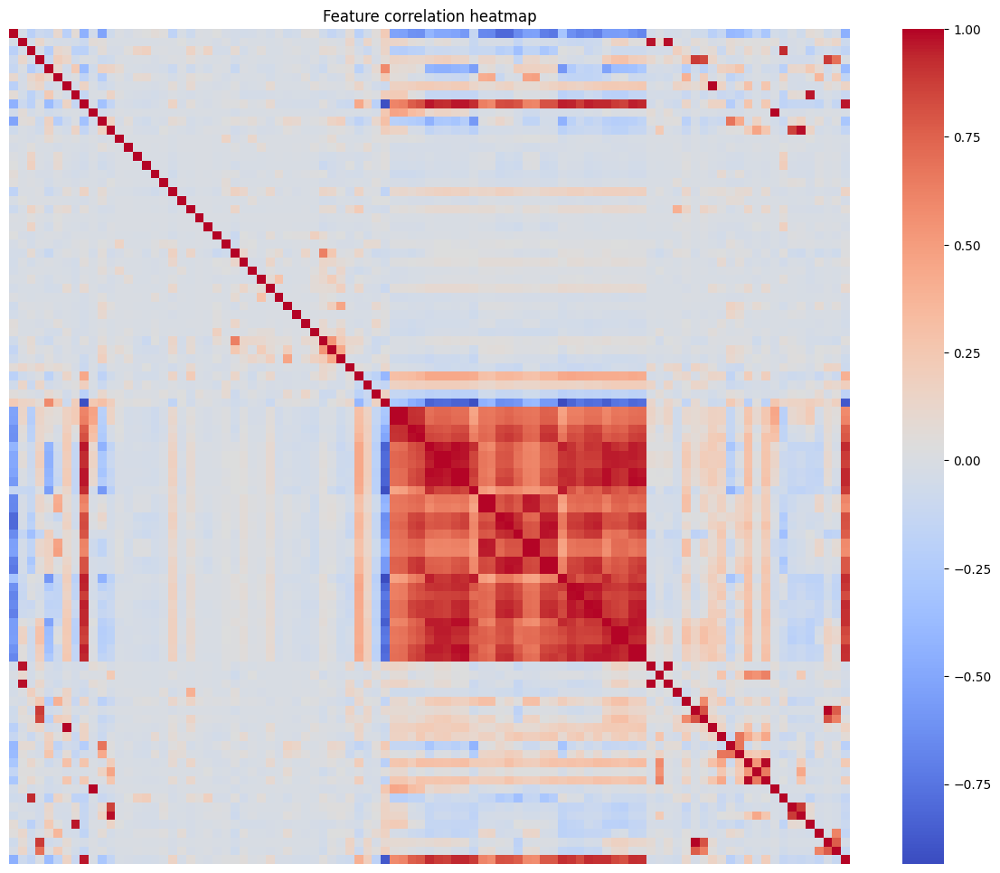

dropping 13 features
dropping 13 features which are not matcalc features


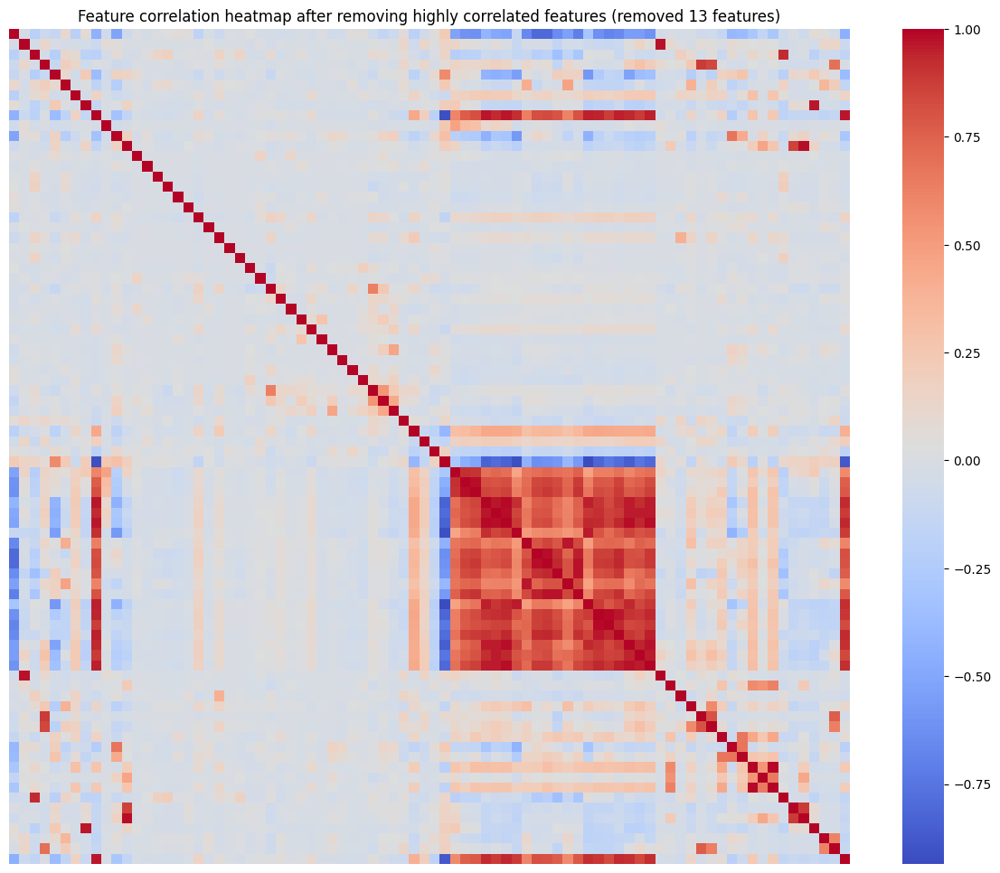



after removing correlated features:
element features: 12
categorical features: 23
numerical processing features: 7
physical features: 21
phase features: 19
total features: 82


In [18]:
# create plot of correlations (only highlight those with >0.99, leave the rest white)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Get the correlation matrix
corr_matrix = df_feat.fillna(0).corr()

# Create a mask for correlations outside our threshold
# This will be True for values we want to hide (between -0.99 and 0.99)
mask = (corr_matrix.abs() < 0.99)
# also hide the diagonal
mask = mask | np.eye(mask.shape[0], dtype=bool)
# and only the upper triangular part
mask = mask | np.tril(np.ones_like(mask, dtype=bool))

corr_matrix_relevant = corr_matrix[~mask]
high_corr = {}
for name, row in corr_matrix_relevant.iterrows():
    if row.isna().all():
        continue

    for c, val in row.dropna().items():
        high_corr[f"{c} - {name}"] = val

# len(high_corr) + df_feat.loc[:,df_feat.nunique()==1].shape[1]

phys_el_feat = list(df_feat.columns[:12])
categorical_oh_features = [c for c in df_feat.columns if "OH" in c]
numerical_processing_features = [c for c in df_feat.columns if c not in phys_el_feat and c not in categorical_oh_features][:7]
physical_features = [c for c in df_feat.columns if c not in phys_el_feat and c not in categorical_oh_features and c not in numerical_processing_features][:30]
phase_feat = [c for c in df_feat.columns if c not in phys_el_feat + categorical_oh_features + numerical_processing_features + physical_features]

print("\n\nfeature overview:")
print("element features:", len(phys_el_feat))
print("categorical features:", len(categorical_oh_features))
print("numerical processing features:", len(numerical_processing_features))
print("physical features:", len(physical_features))
print("phase features:", len(phase_feat))
print("total features:", len(df_feat.columns))
print()
print()

df_feat_temp = preprocessing.remove_correlated_features(df_feat, threshold=0.99, enable_plots=ENABLE_PLOTS, image_dir=SAVE_PATH_IMG)

phys_el_feat = list(df_feat_temp.columns[:12])
categorical_oh_features = [c for c in df_feat_temp.columns if "OH" in c]
numerical_processing_features = [c for c in df_feat_temp.columns if c not in phys_el_feat and c not in categorical_oh_features][:7]
physical_features = [c for c in df_feat_temp.columns if c not in phys_el_feat and c not in categorical_oh_features and c not in numerical_processing_features][:21]
phase_feat = [c for c in df_feat_temp.columns if c not in phys_el_feat + categorical_oh_features + numerical_processing_features + physical_features]

print("\n\nafter removing correlated features:")
print("element features:", len(phys_el_feat))
print("categorical features:", len(categorical_oh_features))
print("numerical processing features:", len(numerical_processing_features))
print("physical features:", len(physical_features))
print("phase features:", len(phase_feat))
print("total features:", len(df_feat_temp.columns))

## remove highly correlated features (>99% correlated) and features which contain only a single unique value

dropping 2 columns because they only contain one unique value!


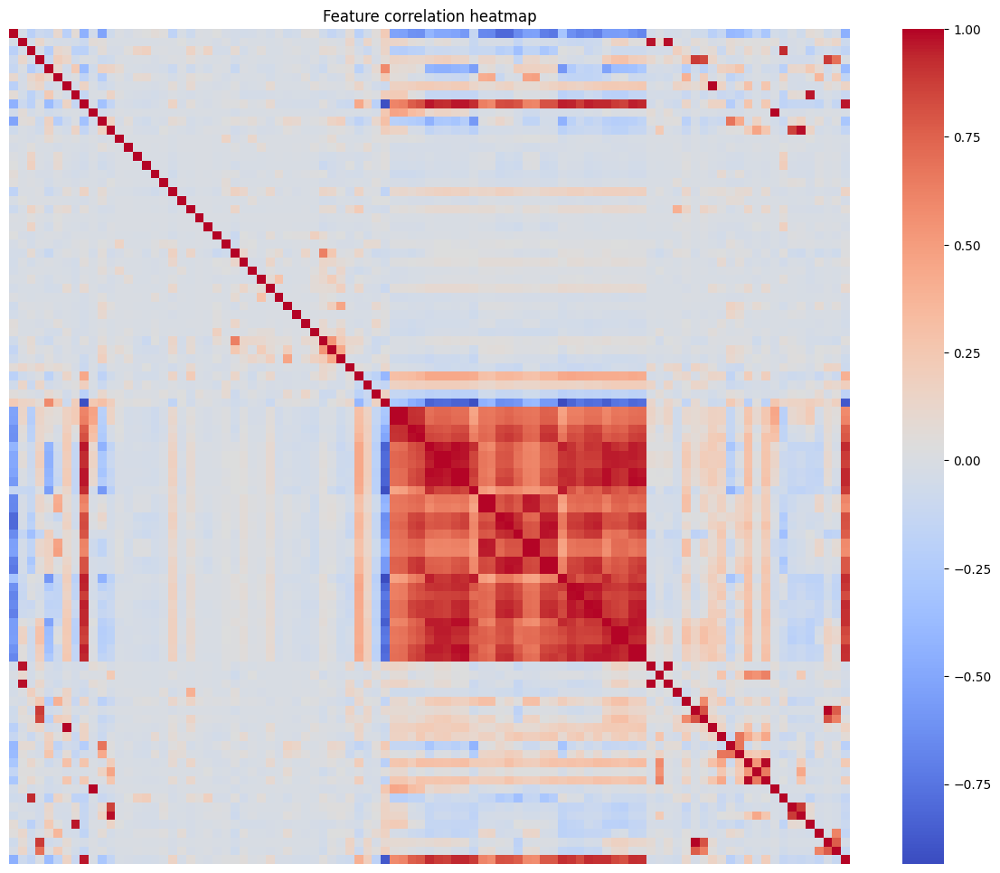

dropping 13 features
dropping 13 features which are not matcalc features


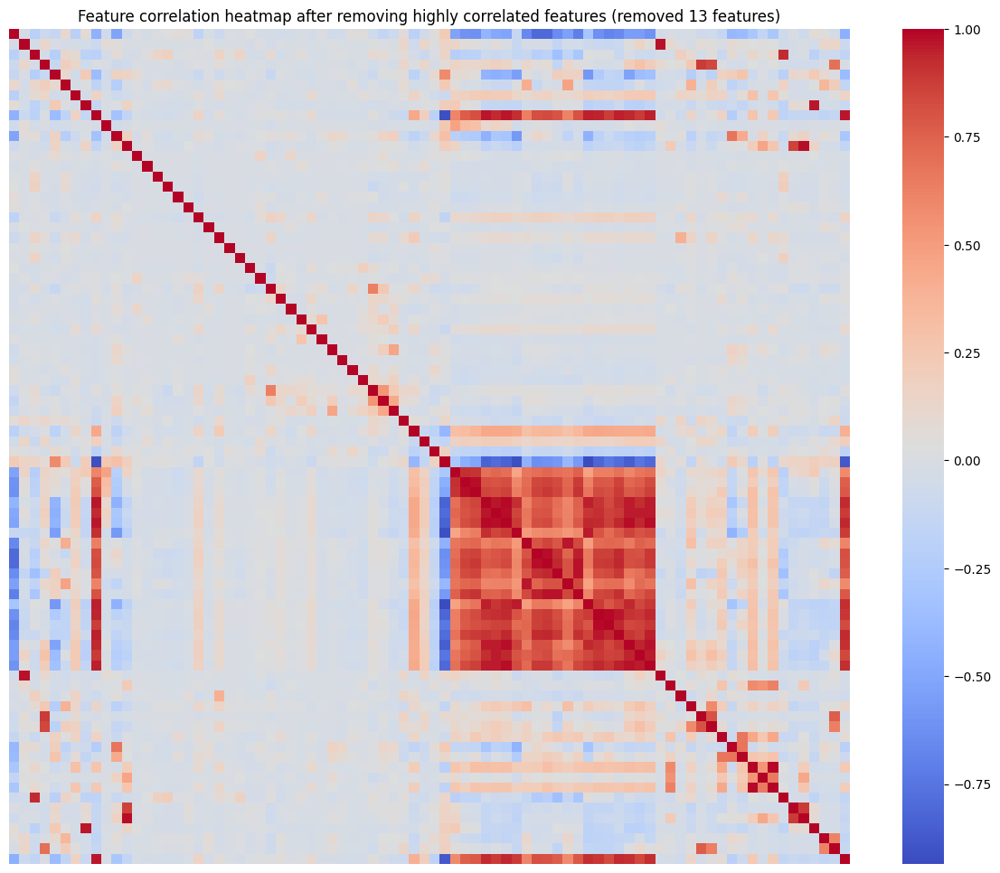

number of unique compositions: 720


In [19]:
df_feat = preprocessing.remove_correlated_features(df_feat, threshold=0.99, enable_plots=ENABLE_PLOTS, image_dir=SAVE_PATH_IMG)

remaining_chem_val_cols = [c for c in relevant_cols["chem_val_cols"] if c in df_feat.columns]
preprocessing.update_relevant_cols("chem_val_cols", remaining_chem_val_cols, verbose=True)
chem_val_cols = relevant_cols["chem_val_cols"]
print("number of unique compositions:", df_feat[chem_val_cols].fillna(0).astype(str).apply(lambda x: ";".join(x), axis=1).nunique())

In [20]:
df_feat[chem_val_cols].astype(str).apply(lambda x: ";".join(x), axis=1).nunique()

720

In [21]:
from src.data_analysis.models import MODELS, MODEL_PARAMS
from deap import tools
import pickle

n_gen = 2000
n_folds = 3
prob_mutate_individual = 0.4
mating_prob = 0.05
#prob_mutate_gene = 0.15
prob_mutate_gene = 1/df_feat.shape[1] # only mutate one gene at a time -> if we have too many, then the individuals get huge penalties for having too many features and so mutated individuals are bound 
n_pop = 50
crossover_method = "uniform"
selection_algo = tools.selTournament
selection_algo_args = {"tournsize": 5}
init_random_params = False

num_features_to_select = None # 20
#penalty_per_active_feature = 0.005
penalty_per_active_feature = 0.002
subsample_size = None # 500 for models which take a long time to fit with large datasets
#to_mutate = "all"
to_mutate = "one_off_or_one_on"
mutate_probs_per_idx_range = None # so that some genes are more likely to be mutated than others
mutate_method_params = "shift" # "shift" or "uniform"
n_feat_init=10 # 30
constant_seed = 42 # 42
re_eval_all = False

###############
## custom prob:
#to_mutate = "custom_prob"
#mutate_probs_per_idx_range = [
#    (np.arange(0, len(chem_cols)), 0.2),
#    (np.arange(len(chem_cols), len(setup[1].columns)), 0.02),
#    (np.arange(len(setup[1].columns), len(setup[1].columns) + len(MODEL_PARAMS[model_name])), 0.05)
#]
###############

#len([el for el in X.columns if "scheil" in el or "equ" in el])
#len([el for el in X.columns if not "scheil" in el and not "equ" in el])

X = df_feat.copy()
y = targets.copy()

X_imp = X.copy()
X_imp[relevant_cols["chem_val_cols"]] = X_imp[relevant_cols["chem_val_cols"]].fillna(0)

#setup = ("mlp", X_imp.fillna(-1), y) 
#setup = ("knn", X_imp.fillna(-1), y) 
setup = ("svr", X_imp.fillna(-1), y) 
#setup = ("rf", X_imp.fillna(-1), y)
#setup = ("lgbm", X_imp, y)
recalc_genalgo = False

assert len(X) == len(y), "number of samples should match!"

files = df_feat_target_file["file"].loc[setup[2].index].values
model_name = setup[0]
feat = setup[1].values
y = setup[2].values

#from importlib import reload
#reload(genetic_algo)

model_params = MODEL_PARAMS.copy()
model_params["svr"] = { # adjust parameters for SVR
    "kernel": {"values": ["linear", "poly", "rbf", "sigmoid"], "current": "rbf"},
    "C": {"min": 0.1, "max": 1e4, "current": 700, "dt": float},
    "gamma": {"min": 1e-3, "max": 1e3, "current": 30, "dt": float},
    "epsilon": {"min": 1e-3, "max": 1e3, "current": 30, "dt": float},
    "tol": {"min": 1e-5, "max": 1e-1, "current": 1e-3, "dt": float},
    "degree": {"min": 2, "max": 20, "current": 3, "dt": int},
    "max_iter": 1000,
    "verbose": False
}

genes_path = os.path.join(SAVE_PATH_DATA, f"tracked_genes_{model_name}.pkl")
best_ind_path = os.path.join(SAVE_PATH_DATA, f"best_individual_{model_name}.pkl")
log_path = os.path.join(SAVE_PATH_DATA, f"log_{model_name}.pkl")
chem_val_cols = relevant_cols["chem_val_cols"]
chem_val = df_feat[chem_val_cols]
scaling_method = "minmax"
if (not os.path.isfile(genes_path)) or recalc_genalgo:
    best_individual, log, tracked_genes = genetic_algo.run_genetic_algorithm(
            feat,
            y,
            files,
            chem_val,
            model_name,
            model_params,
            MODELS,
            n_generations=n_gen,
            n_folds=n_folds,
            col_idx_scaling=None,
            scaling_method=scaling_method,
            prob_mutate_individual=prob_mutate_individual,
            mating_prob=mating_prob,
            prob_mutate_gene=prob_mutate_gene,
            n_pop=n_pop,
            feature_names=X.columns,
            crossover_method=crossover_method,
            selection_algo=selection_algo,
            selection_algo_args=selection_algo_args,
            init_random_params=init_random_params,
            num_features_to_select=num_features_to_select,
            penalty_per_active_feature=penalty_per_active_feature,
            to_mutate=to_mutate,
            mutate_method_params=mutate_method_params,
            constant_seed=constant_seed,
            subsample_size=subsample_size,
            mutate_probs_per_idx_range=mutate_probs_per_idx_range,
            n_feat_init=n_feat_init,
            re_eval_all=re_eval_all,
    )

    # save result to file
    with open(best_ind_path, "wb") as f:
        pickle.dump(best_individual, f)

    with open(log_path, "wb") as f:
        pickle.dump(log, f)

    with open(genes_path, "wb") as f:
        pickle.dump(tracked_genes, f)
else:
    with open(best_ind_path, "rb") as f:
        from src.data_analysis.genetic_algo import Individual, FitnessMax
        best_individual = pickle.load(f, encoding="bytes")

    with open(log_path, "rb") as f:
        log = pickle.load(f)

    with open(genes_path, "rb") as f:
        tracked_genes = pickle.load(f)


#len([el for el in df_feat.columns if not "equ" in el])

print("max score in last generation:", log.select("max")[-1])
# choose best individual as the individual with the highest score of the last generation
inds = tracked_genes[max(tracked_genes.keys())]
fitnesses = [ind[1].values[0].item() for ind in inds]
best_ind_idx = np.argmax(fitnesses)
best_individual1 = inds[best_ind_idx][0]

# choose best individual as the individual with the highest score of all generations
best_individual2 = max(tracked_genes.items(), key=lambda x: x[1][0][1].values[0].item())[1][0][0]

for best_individual in [best_individual1, best_individual2]:
    print("num features:", best_individual[:setup[1].shape[1]].count(1))
    selected_cols = [c for use, c in zip(best_individual[:setup[1].shape[1]], setup[1].columns) if use]

    print("\nselected columns:")
    for col in selected_cols:
        print(col)

    selected_params = best_individual[setup[1].shape[1]:]
    selected_params = {el["name"]: el["current"] for el in selected_params if "values" in el or "dt" in el}
    print("\nselected params:")
    for k, v in selected_params.items():
        print(f"{k}: {v}")

max score in last generation: 0.816
num features: 11

selected columns:
Mg
Mn
Si
Ti
D5_std
D6_std
E8_mad
Fe/Cu sub-group
Si/Al sub-group
AL3ZR
Mn-based group

selected params:
kernel: rbf
C: 585.0656588838722
gamma: 30
epsilon: 29.28794285474652
tol: 0.0008287762705770532
degree: 3
num features: 11

selected columns:
Mg
Mn
Si
Ti
D5_std
D6_std
E8_mad
Fe/Cu sub-group
Si/Al sub-group
AL3ZR
Mn-based group

selected params:
kernel: rbf
C: 585.0656588838722
gamma: 30
epsilon: 29.28794285474652
tol: 0.0008287762705770532
degree: 3


## Visualization plot for genetic algorithm

max_fitness (colorbar): 0.8, min_fitness (colorbar): 0.7
0
plotting param: kernel
1
plotting param: C
2
plotting param: gamma
3
plotting param: epsilon
4
plotting param: tol
5
plotting param: degree
parameter degree, not_poly: True
skipping degree plot
scatter plot done - setting ticks and labels...
done! saving/showing plot...


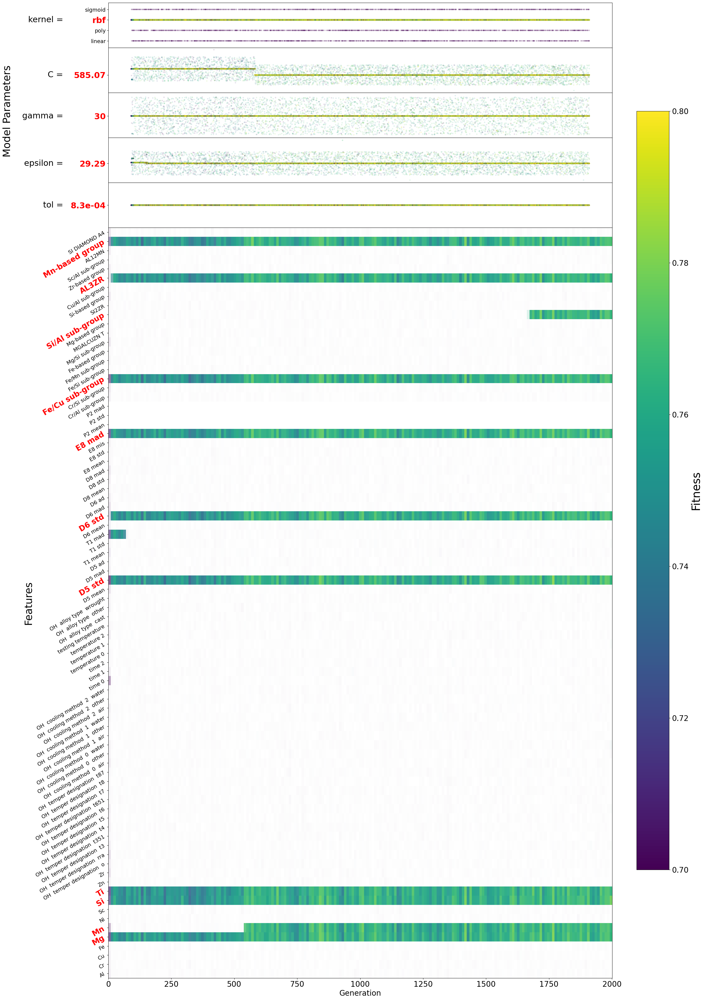

In [22]:
all_feat_columns = setup[1].columns
from importlib import reload; reload(genetic_algo)

genetic_algo.visualize_tracked_genes_with_params(tracked_genes, model_name, selected_cols, all_feat_columns, selected_params, enable_plots=ENABLE_PLOTS, img_dir=SAVE_PATH_IMG, fitness_thr_plot=None, heatmap_parition_size=10)

## 4-fold cv plot for pape

mean r2: 0.807063546189197
mean mae: 44.661668299473526


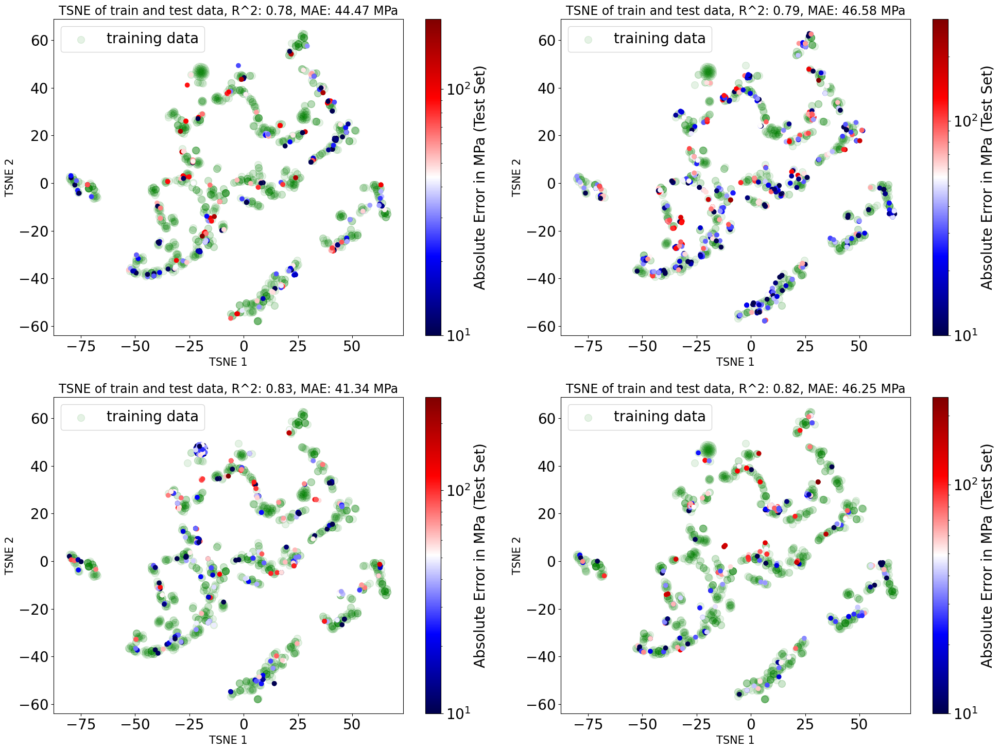

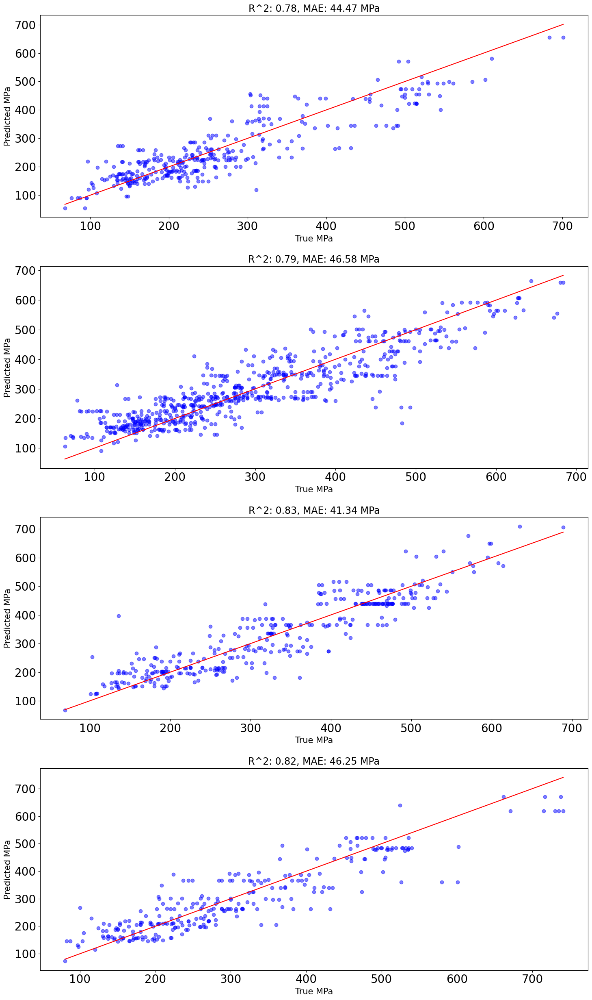

mean r2: 0.1986544838156655
mean mae: 93.15967764788641


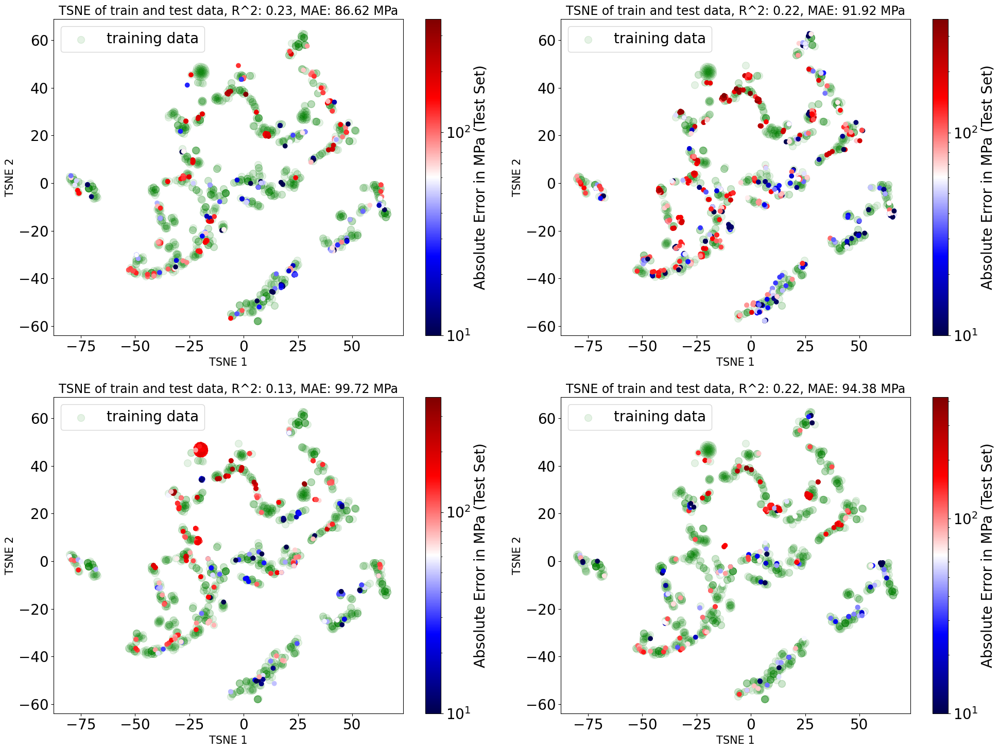

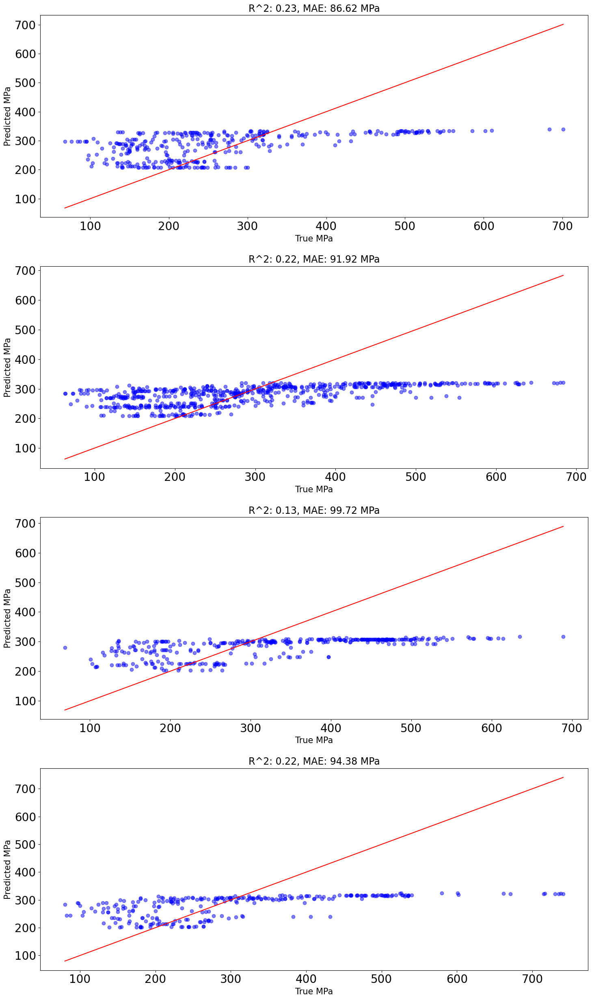

([np.float64(0.22621472533950293),
  np.float64(0.22343665996238327),
  np.float64(0.12547629522885262),
  np.float64(0.21949025473192318)],
 [np.float64(86.61556119369386),
  np.float64(91.92158099479005),
  np.float64(99.72191344185721),
  np.float64(94.37965496120452)])

In [23]:
files = df_feat_target_file["file"].loc[setup[2].index].values
chem_val_cols = relevant_cols["chem_val_cols"]
chem_val = df_feat[chem_val_cols]
model_name = setup[0]
feat = setup[1].iloc[:, [i for i, el in enumerate(best_individual[:setup[1].shape[1]]) if el]]
y = setup[2]
hyperparams = [el for el in best_individual[setup[1].shape[1]:]]
p = {el["name"]: el["current"] for el in hyperparams}
assert (y.index == feat.index).all(), "index of features and target should match!"
evaluation.cv_with_file_and_element_grouping(feat, y, p, model_name, chem_val, files, chem_val_cols, scaling_method, enable_plots=ENABLE_PLOTS, img_dir=SAVE_PATH_IMG, n_folds=4, seed=constant_seed)



p_modified = p.copy()
p_modified["C"] = 1
p_modified["gamma"] = "scale"
p_modified["epsilon"] = 0.1


evaluation.cv_with_file_and_element_grouping(feat, y, p_modified, model_name, chem_val, files, chem_val_cols, scaling_method, enable_plots=ENABLE_PLOTS, img_dir=SAVE_PATH_IMG, n_folds=4, seed=constant_seed)

In [24]:
N_TRIES_CV = 20

# Perform 4-fold cross validation using 3 different scenarios:
### CV on the best individual (features selected via genetic algo)
### without phase features
### only chemical comps

### Perform 4-fold cross validation with features selected by genetic algo

mean r2: 0.7908946124215411
mean mae: 46.32378388131708


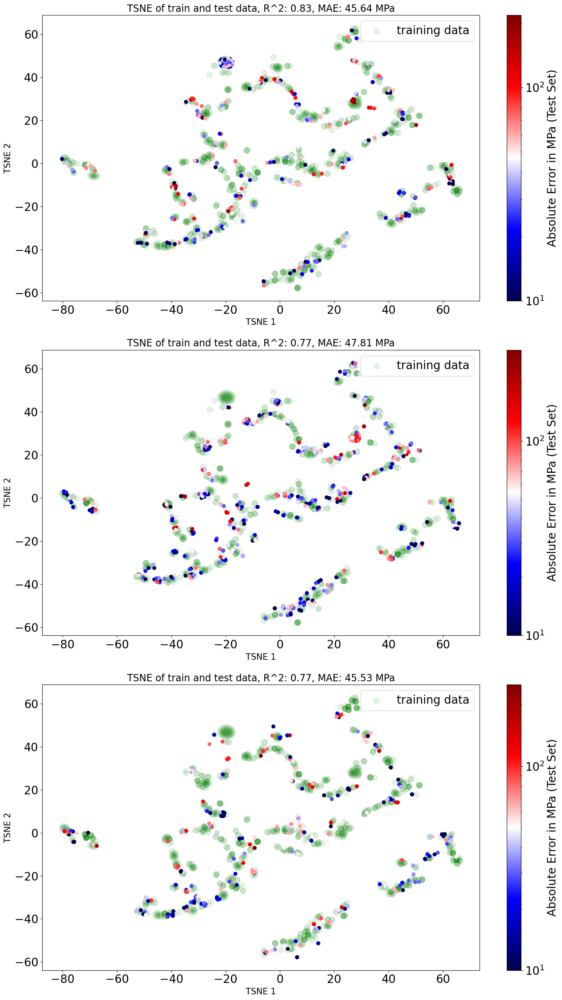

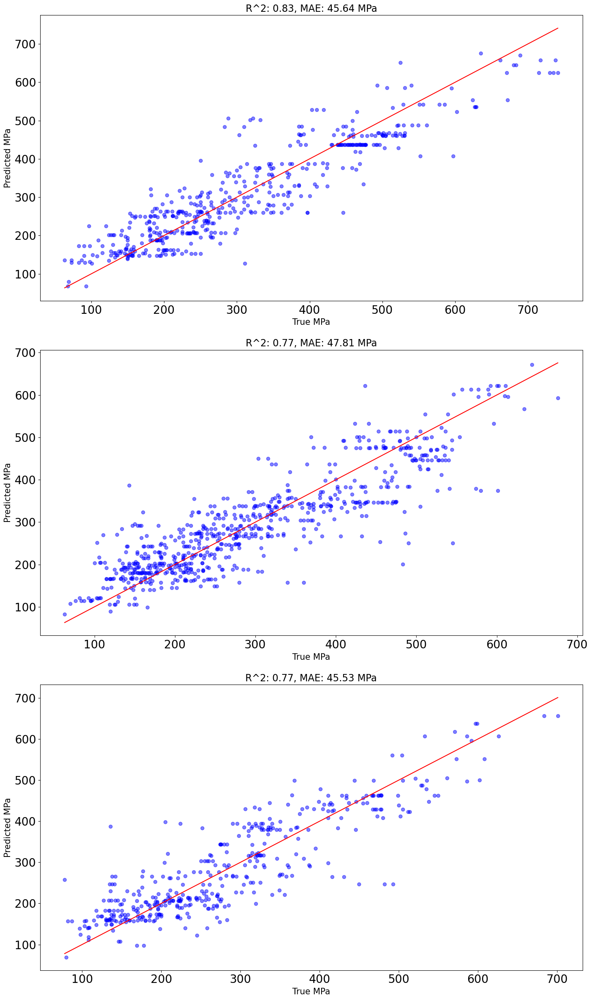

mean r2: 0.7886060393578619
mean mae: 47.53248977921877


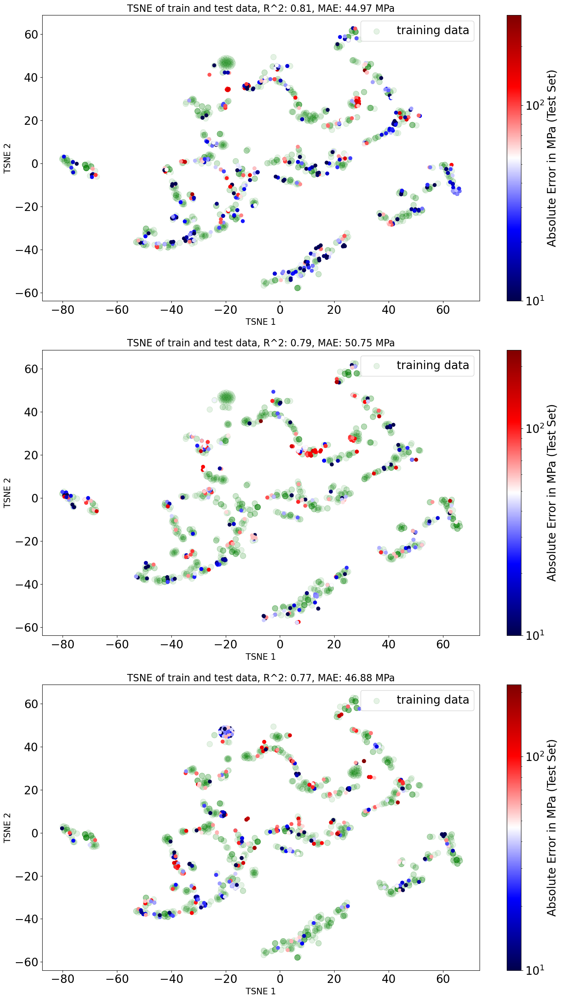

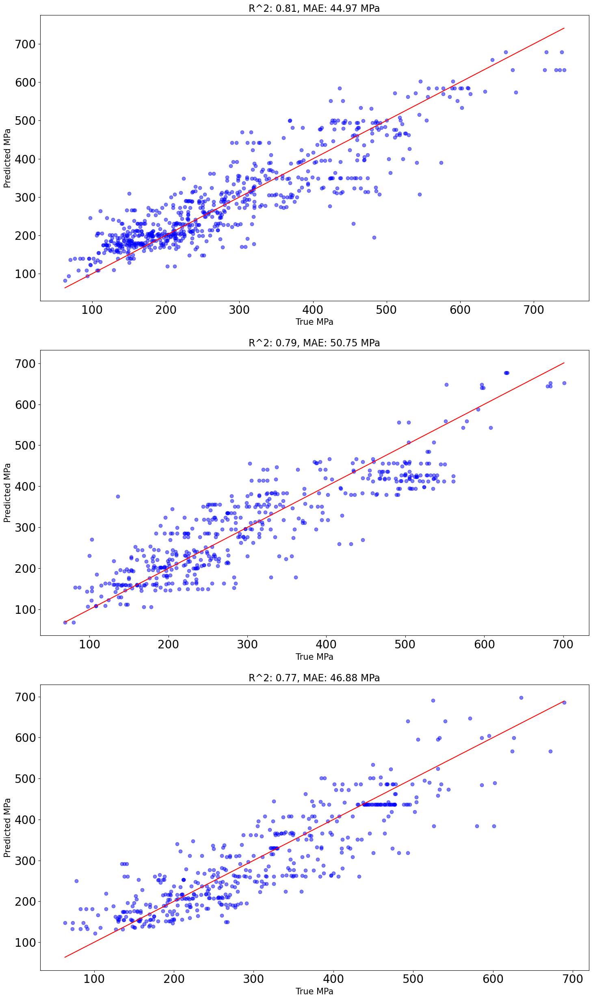

mean r2: 0.7935793583583396
mean mae: 47.08686412067431


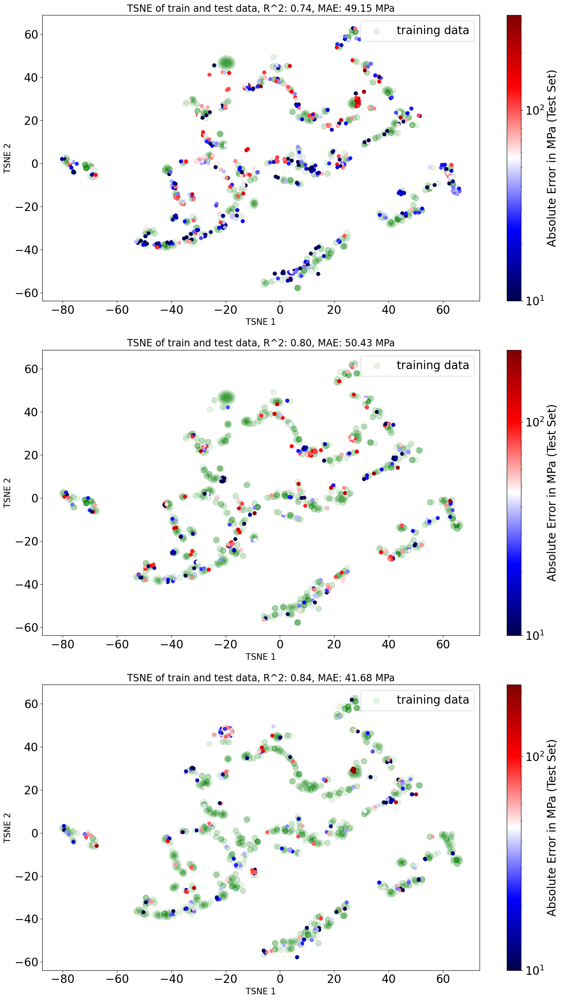

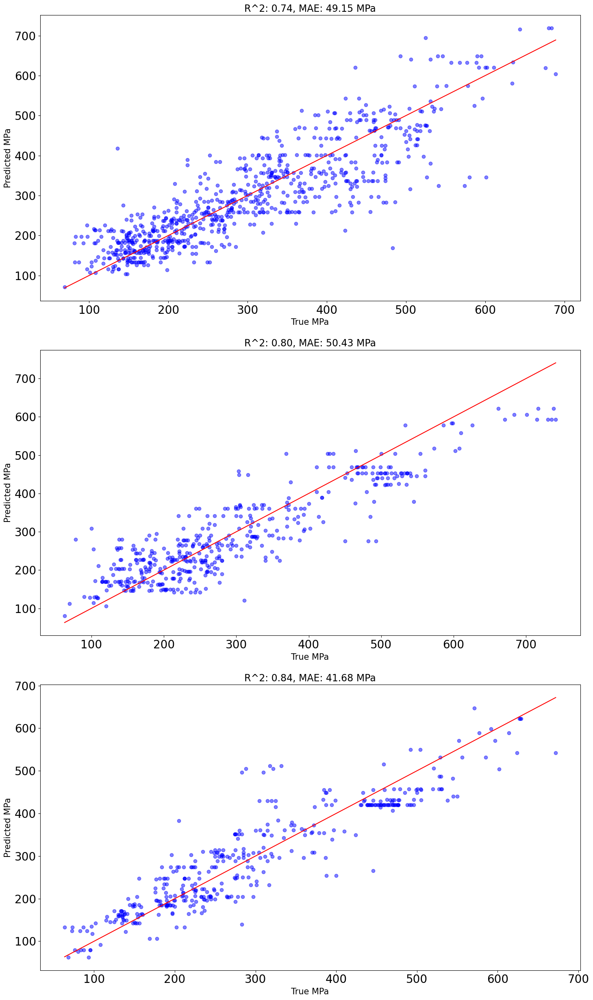

mean r2: 0.7775047978578907
mean mae: 47.145482788534025


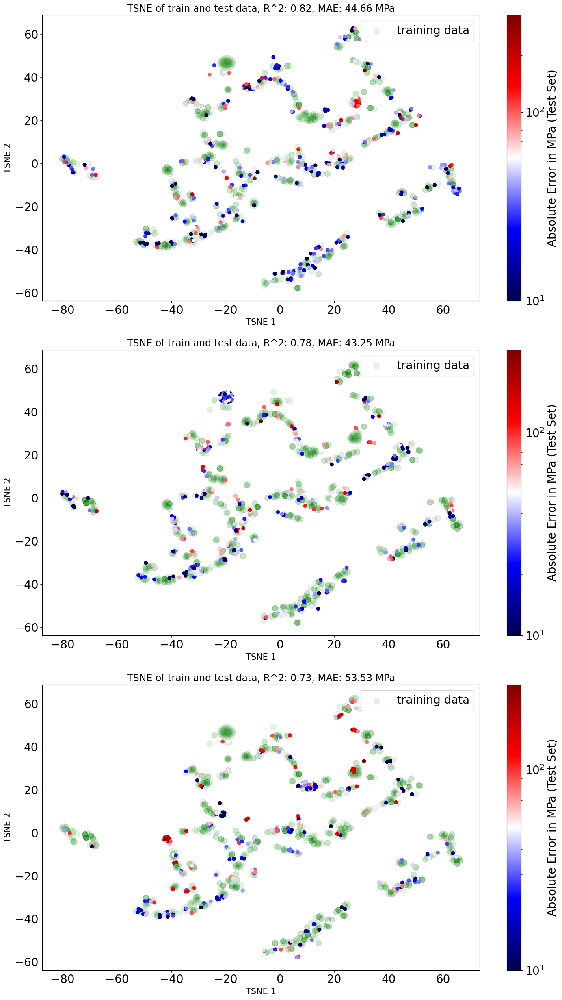

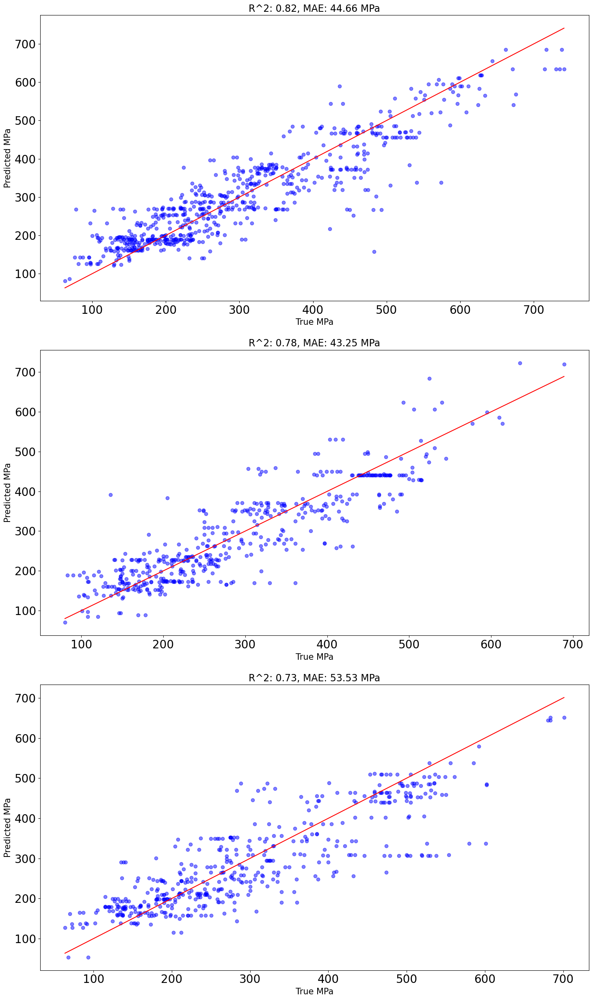

mean r2: 0.7682287148873107
mean mae: 47.318585609711214


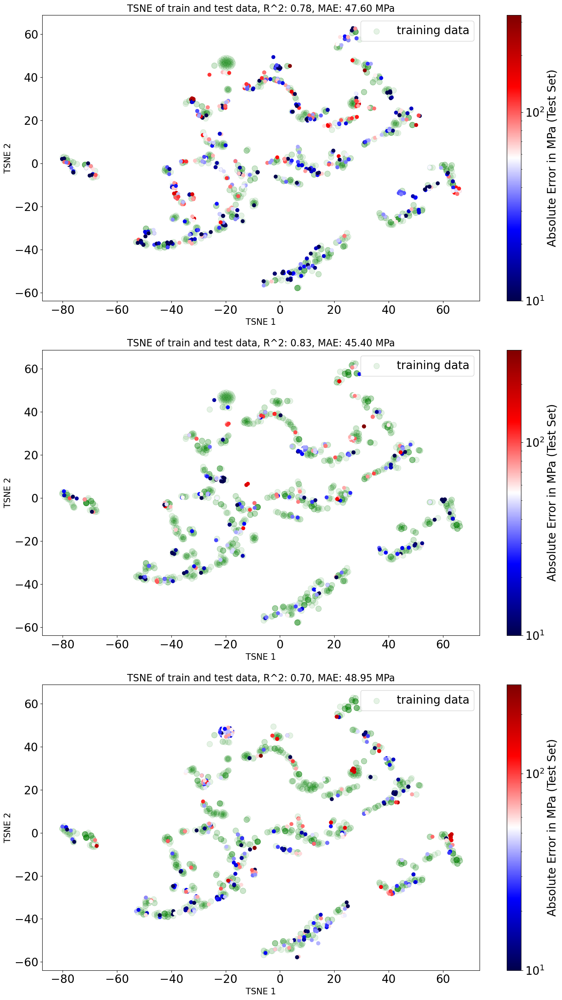

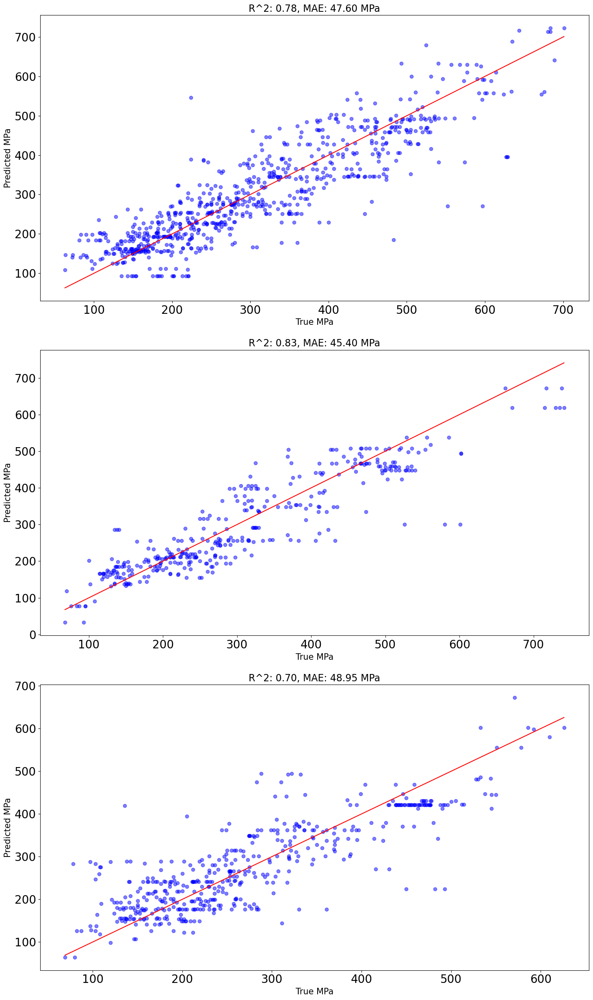

mean r2: 0.7857567422868508
mean mae: 47.22555630078313


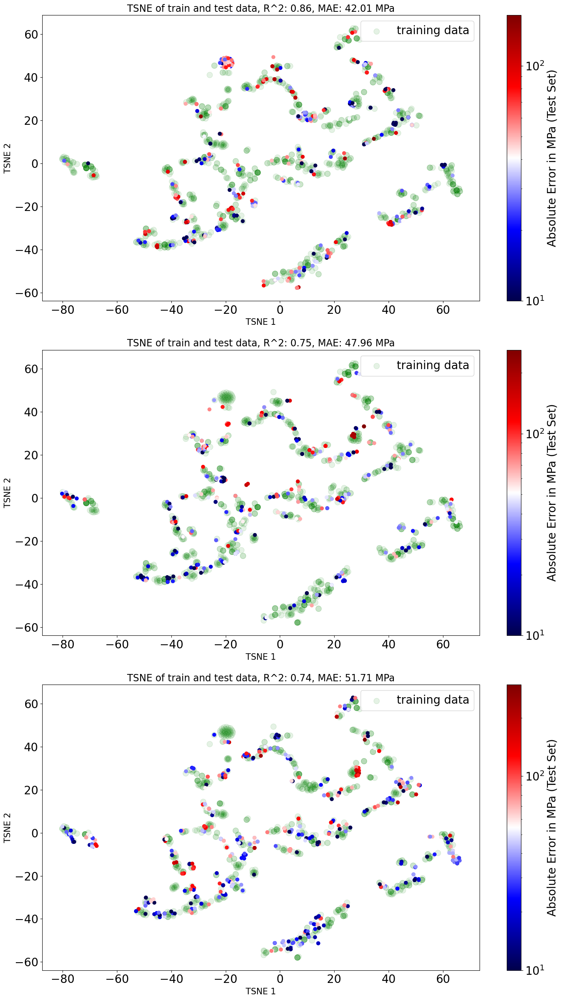

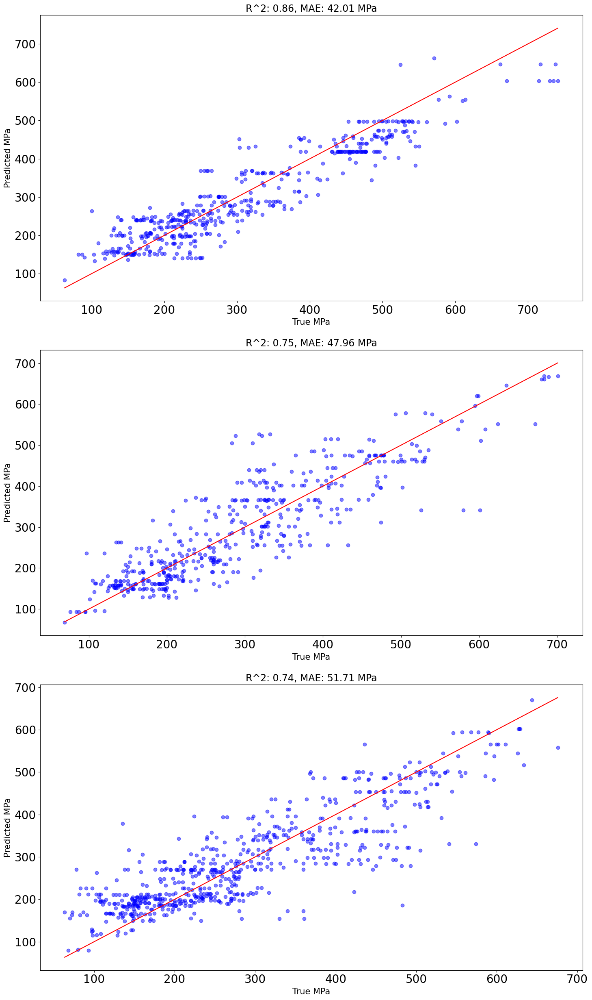

mean r2: 0.7841461655225789
mean mae: 48.10511580347475


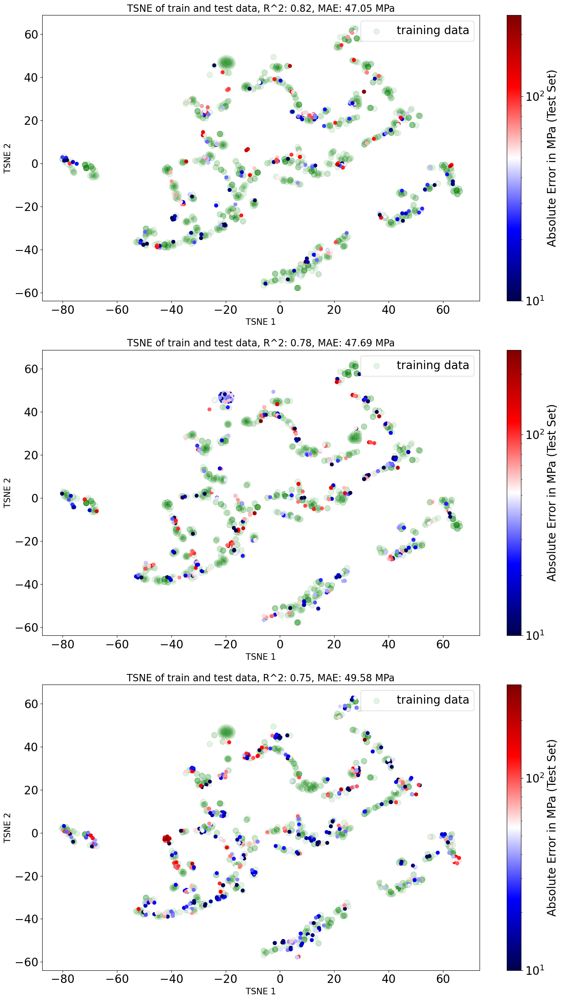

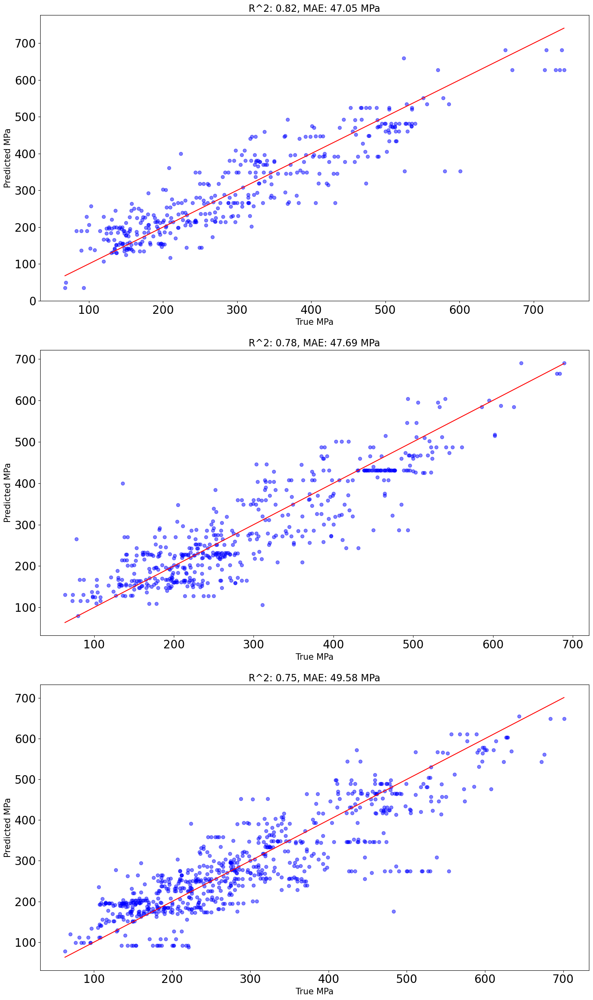

mean r2: 0.8076947952045183
mean mae: 44.410156006669844


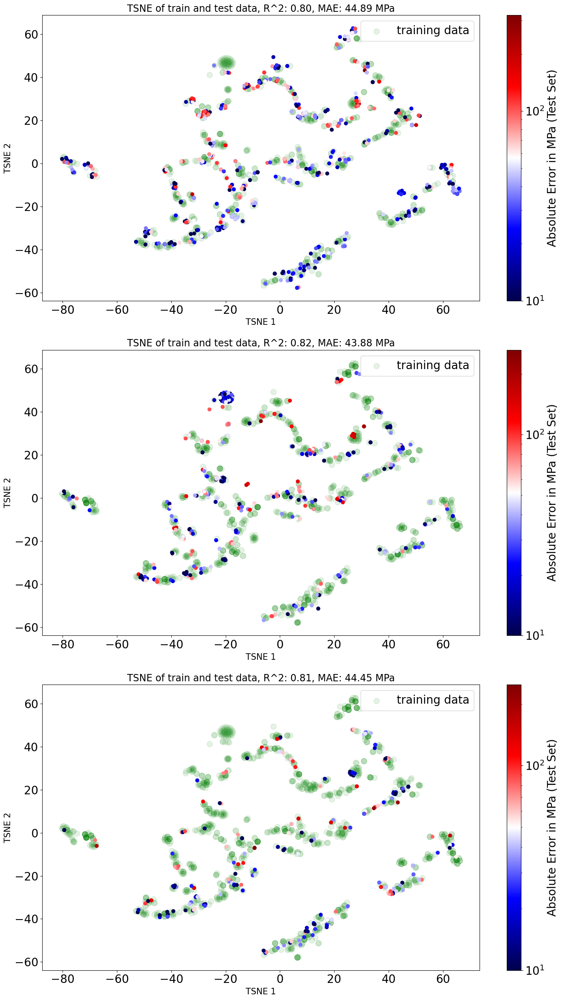

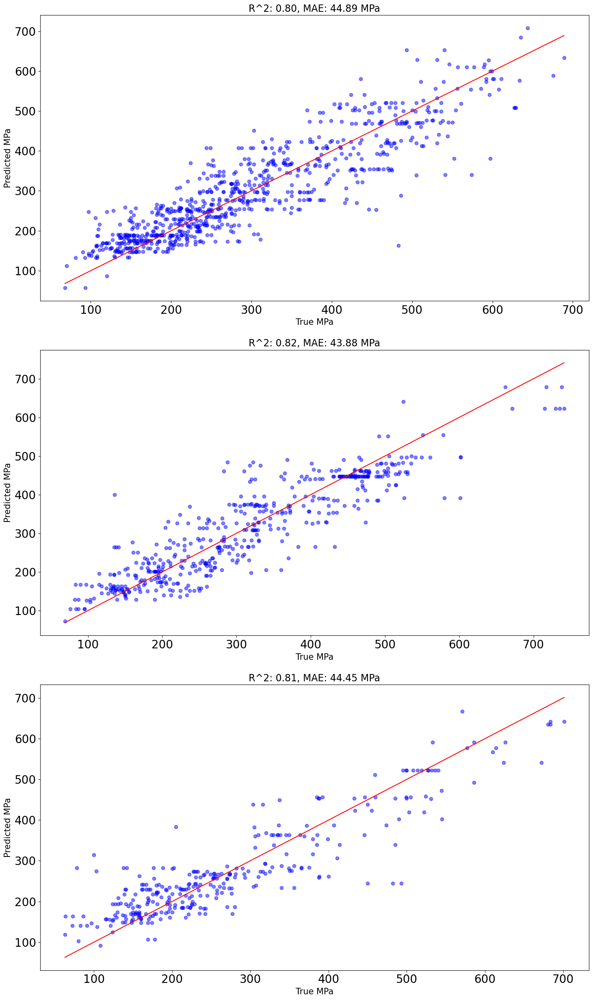

mean r2: 0.7953678773315144
mean mae: 46.84395239405257


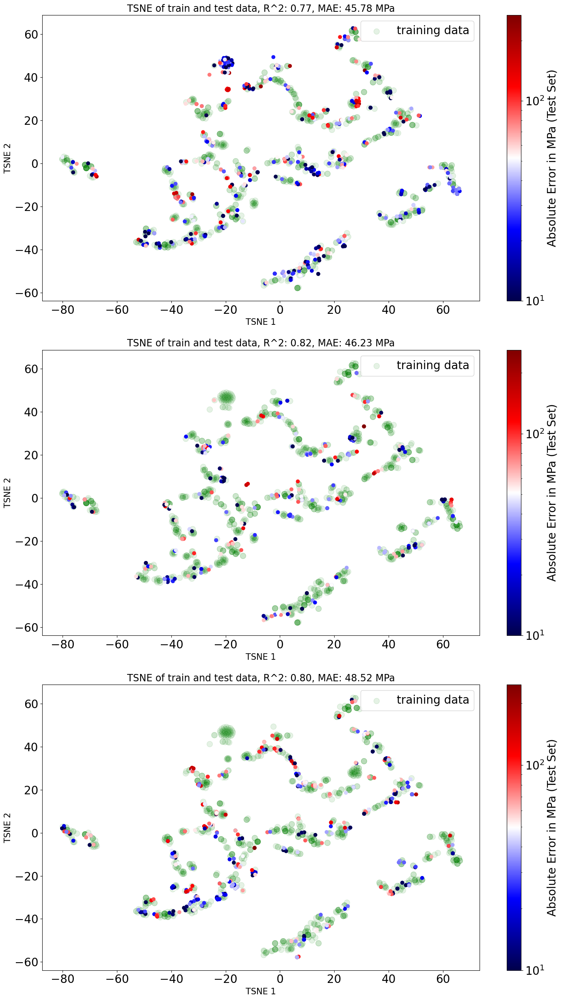

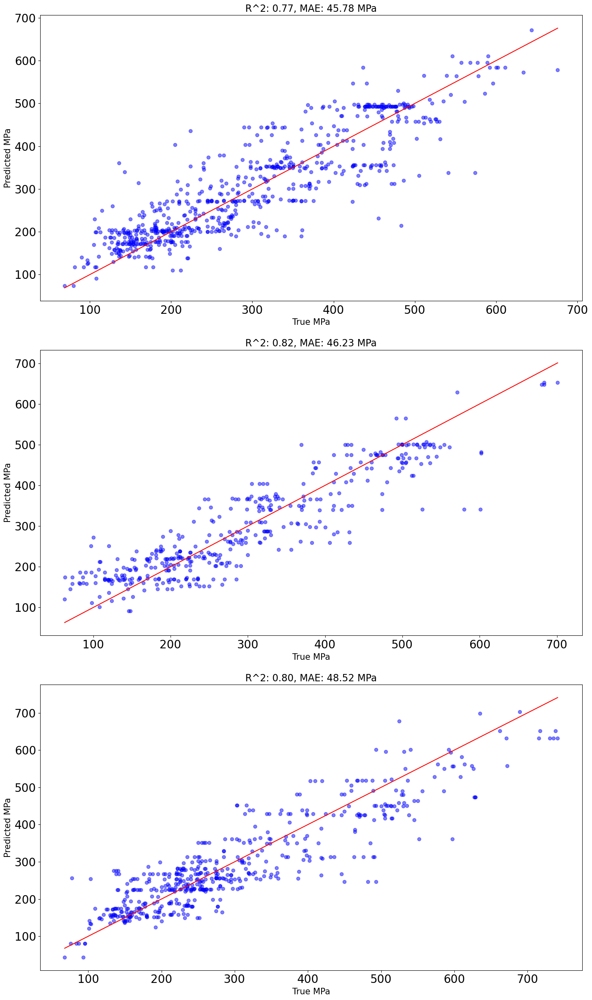

mean r2: 0.815017130881238
mean mae: 44.152081797271336


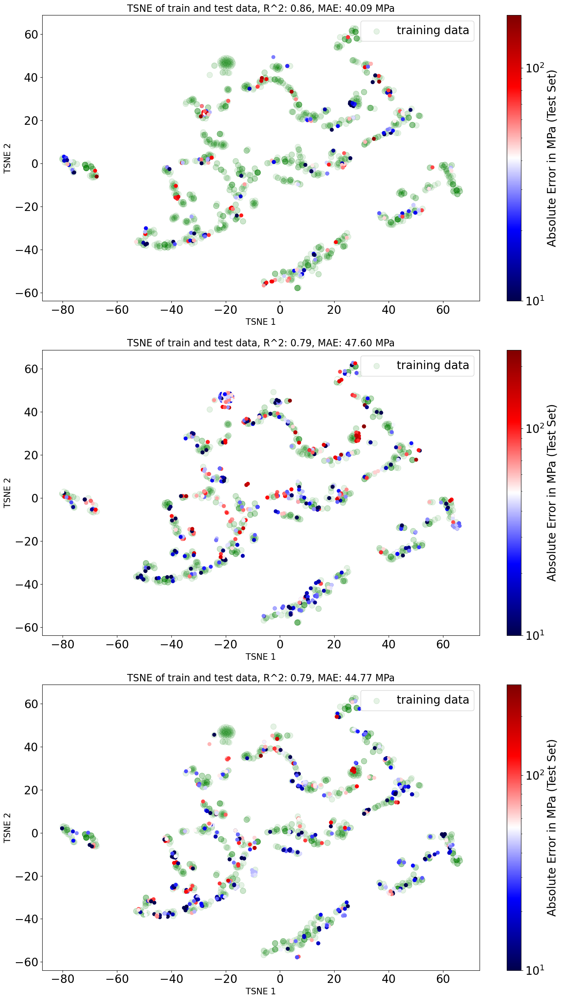

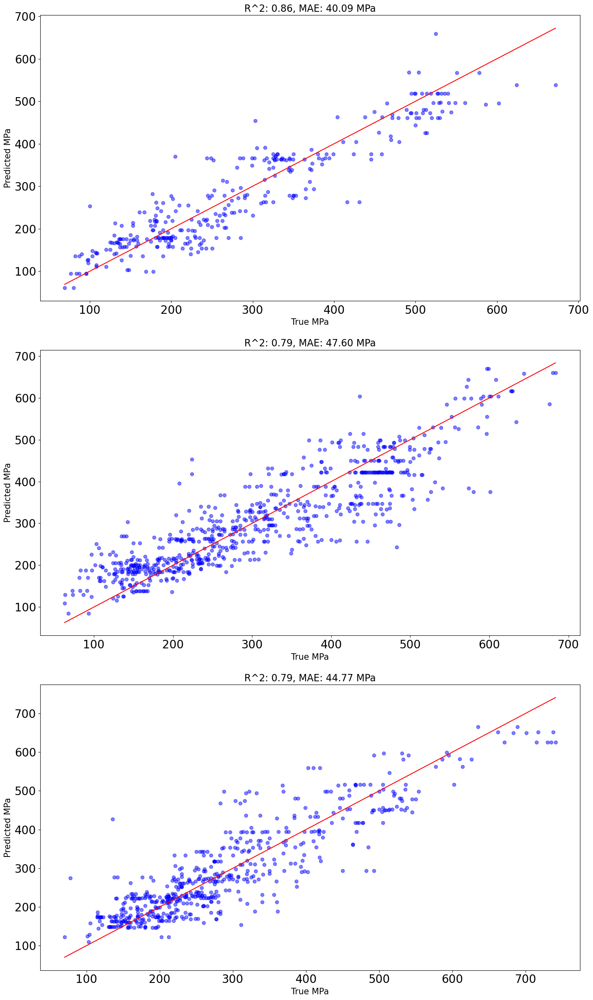

mean r2: 0.7778816615623954
mean mae: 47.140495939524634


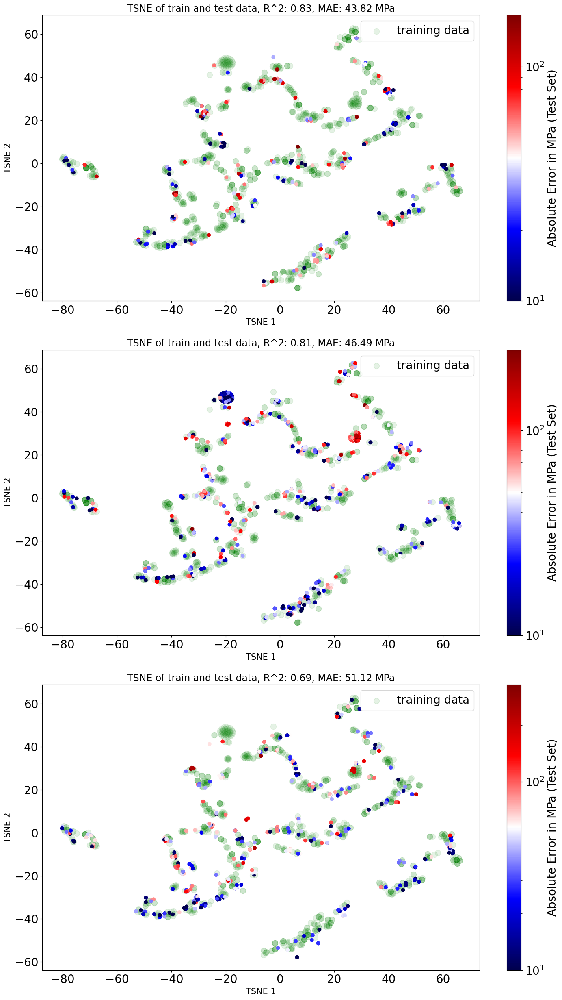

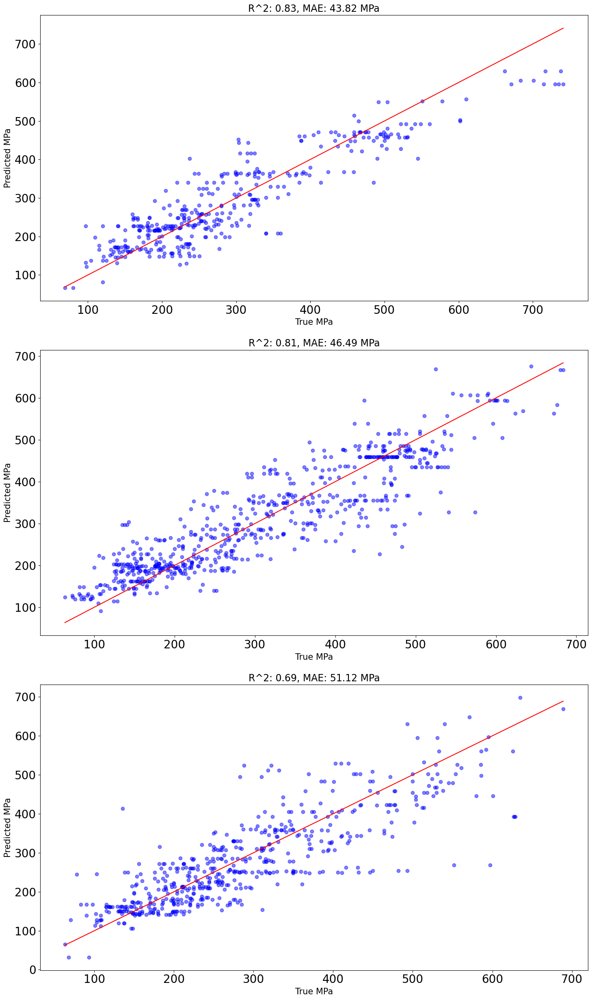

mean r2: 0.7829029077304169
mean mae: 46.927826870172304


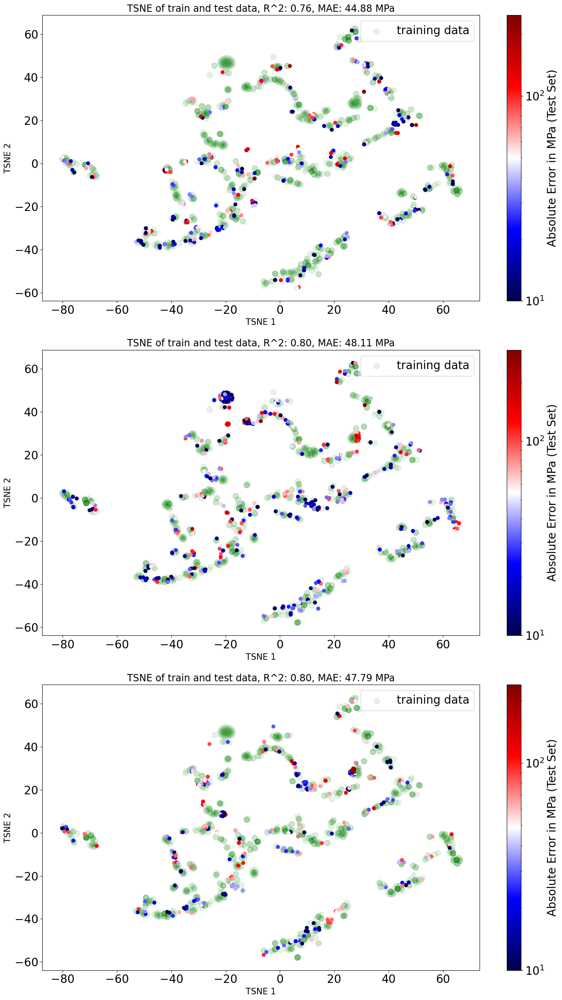

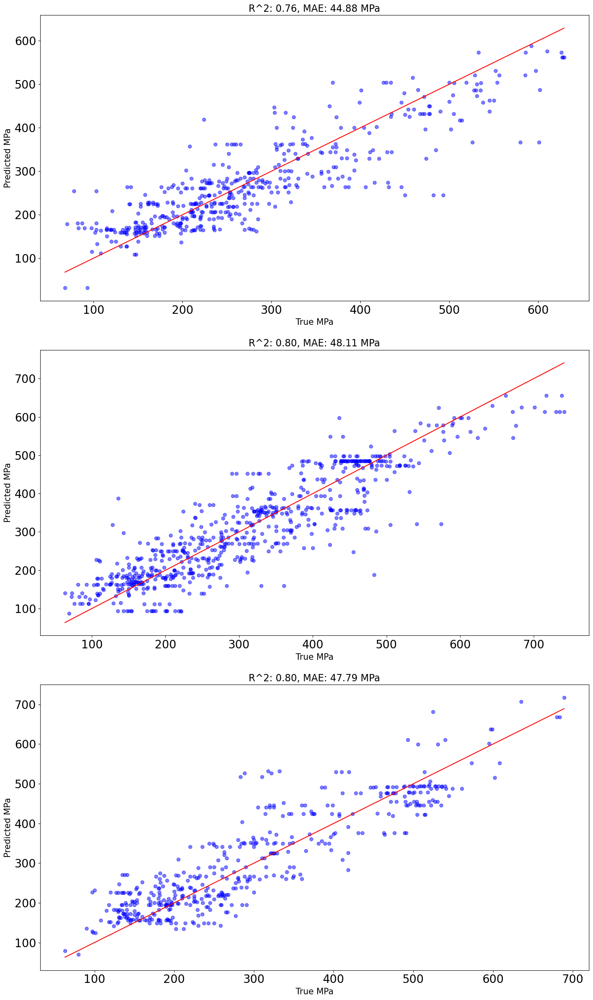

mean r2: 0.7888251303098919
mean mae: 47.59408209264882


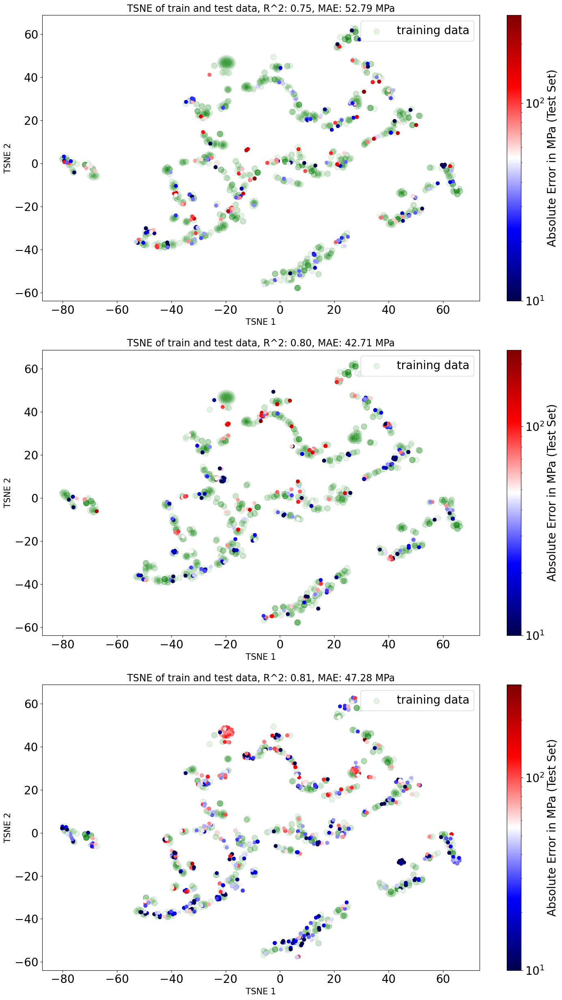

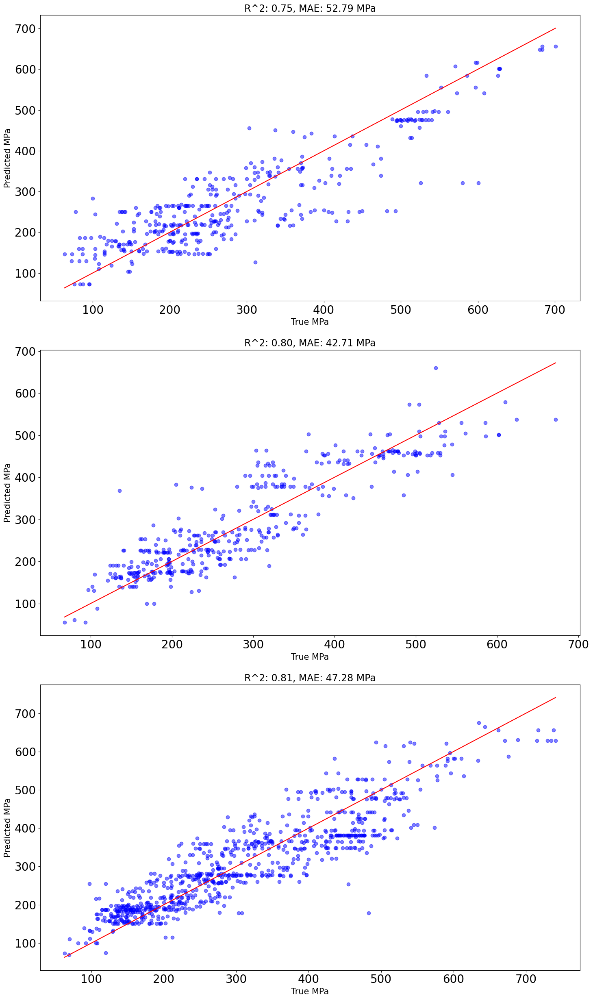

mean r2: 0.7894038430251493
mean mae: 46.642558071203986


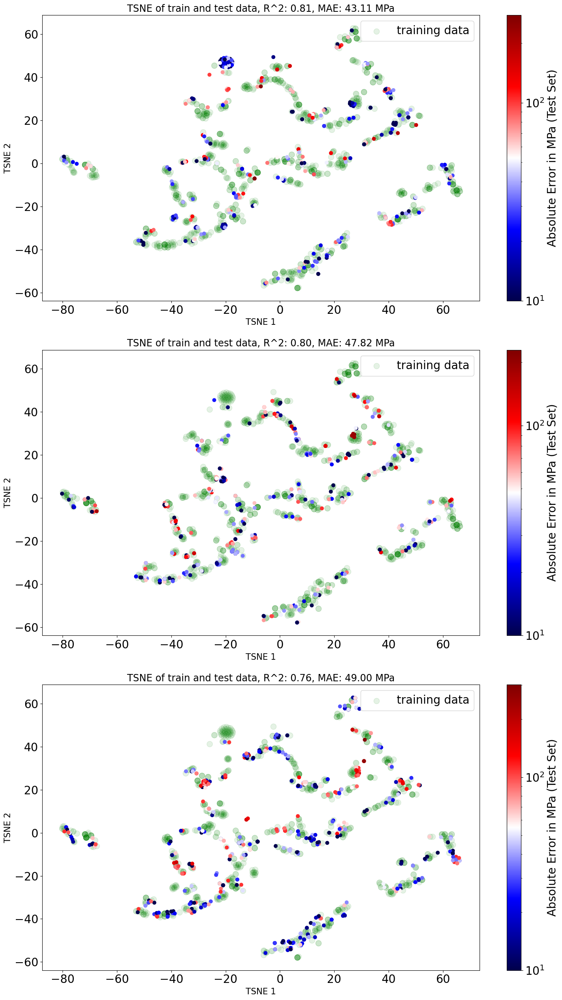

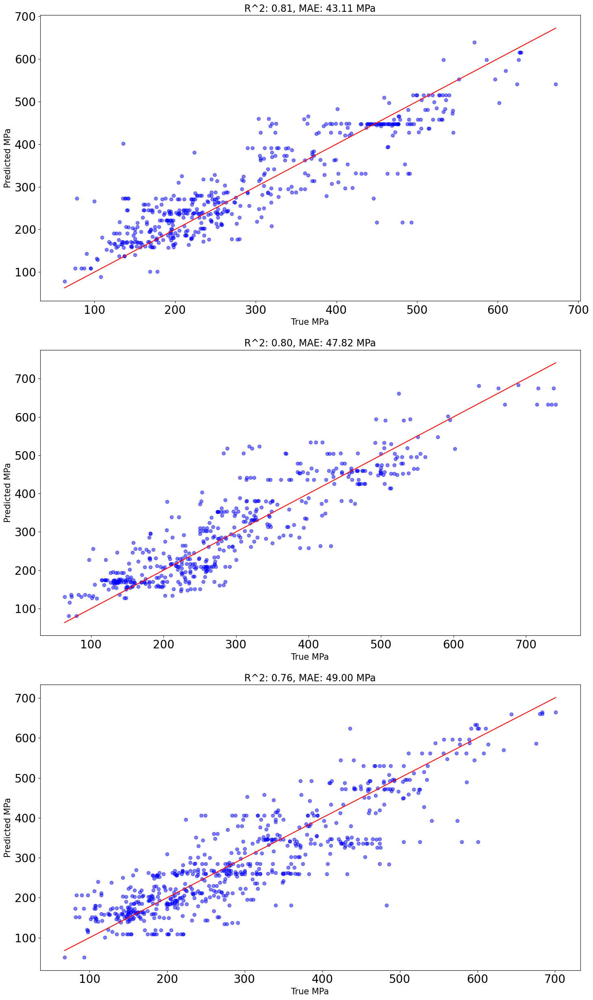

mean r2: 0.8049462075607184
mean mae: 44.76572124853377


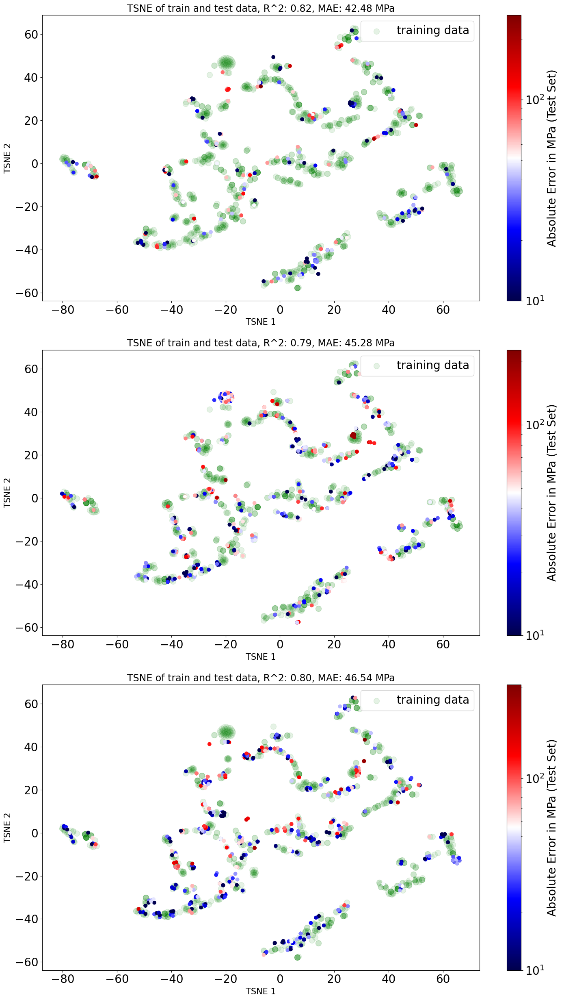

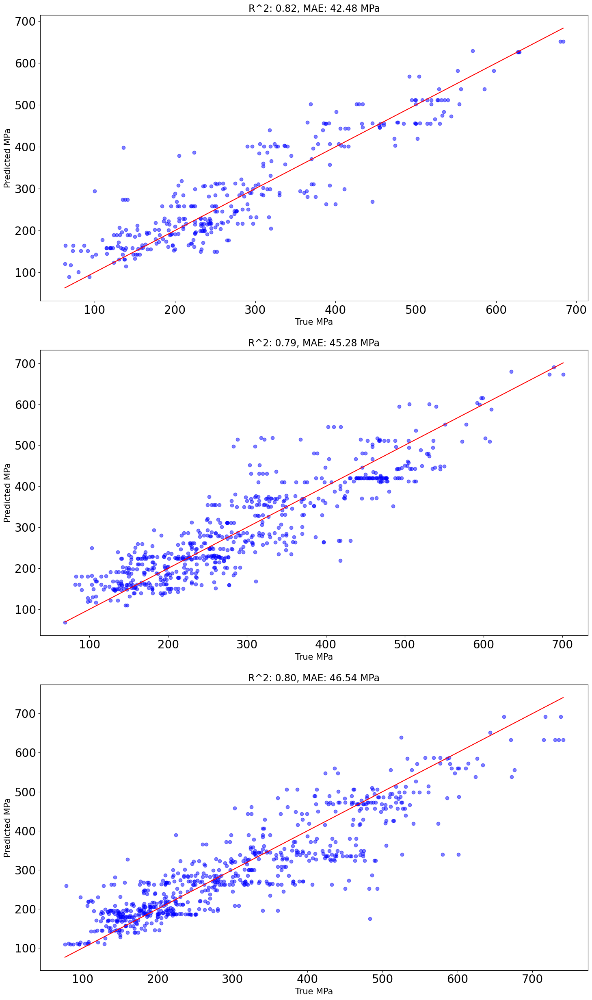

mean r2: 0.8038321500267435
mean mae: 46.042545710907156


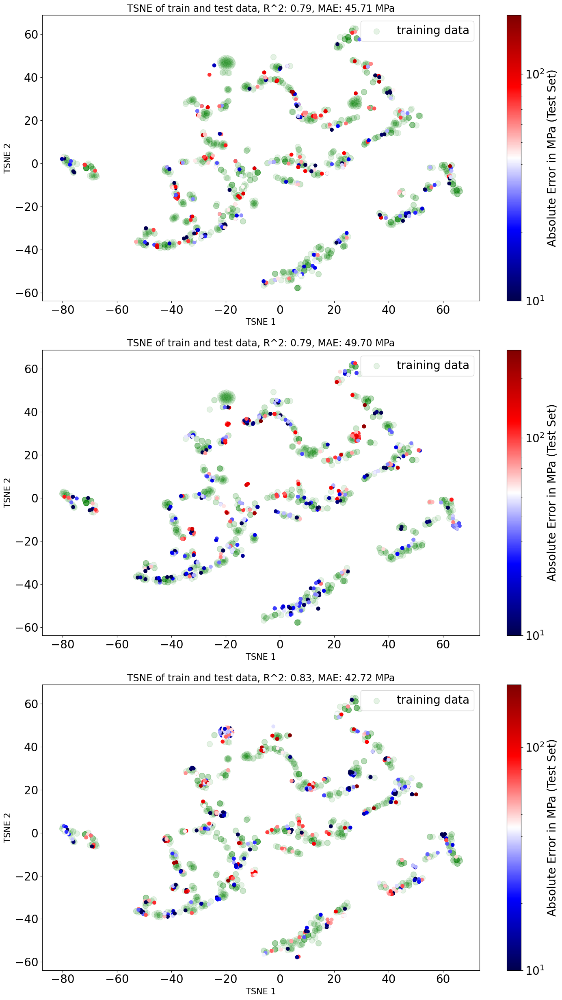

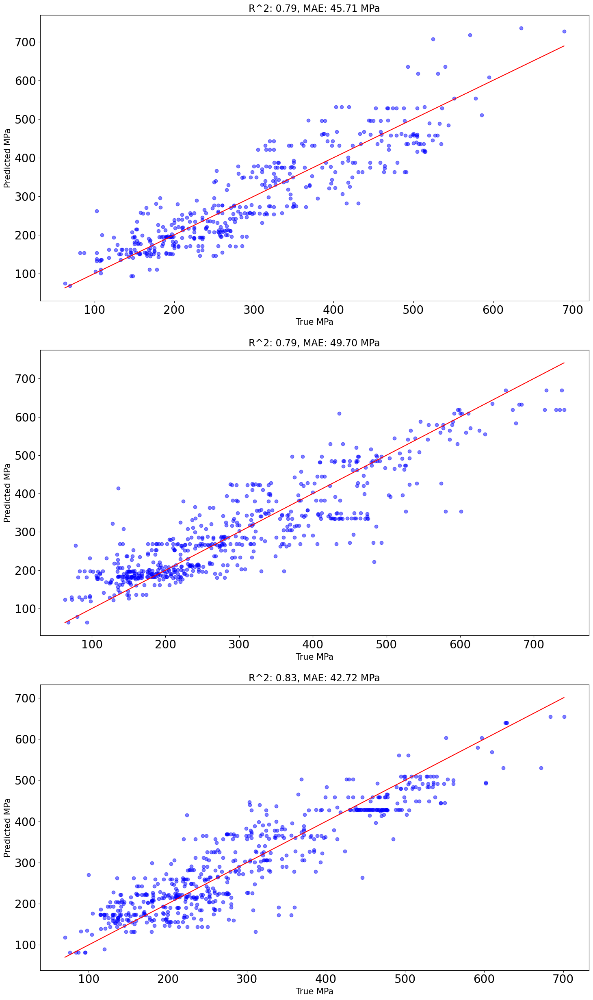

mean r2: 0.7890101842148844
mean mae: 47.751199829509936


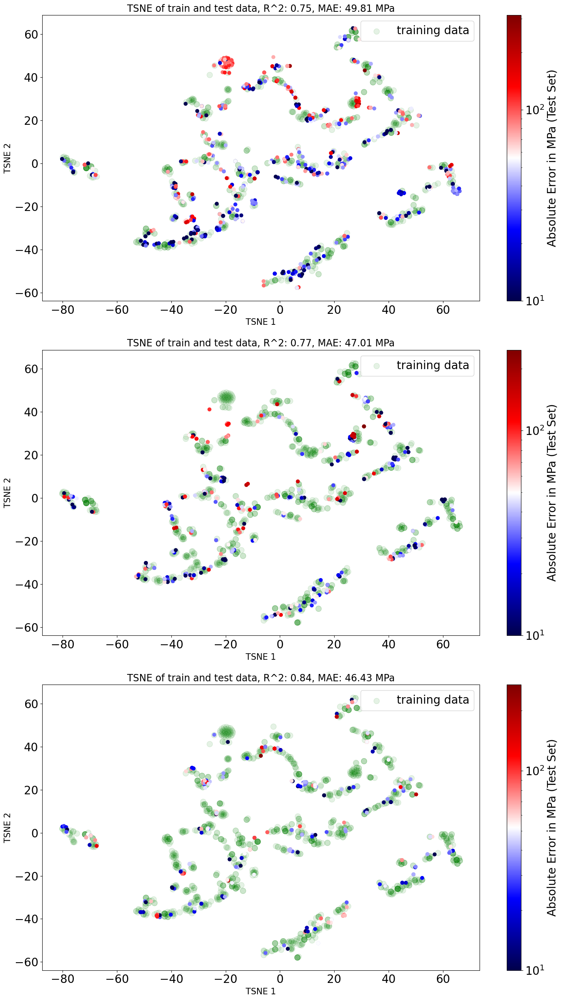

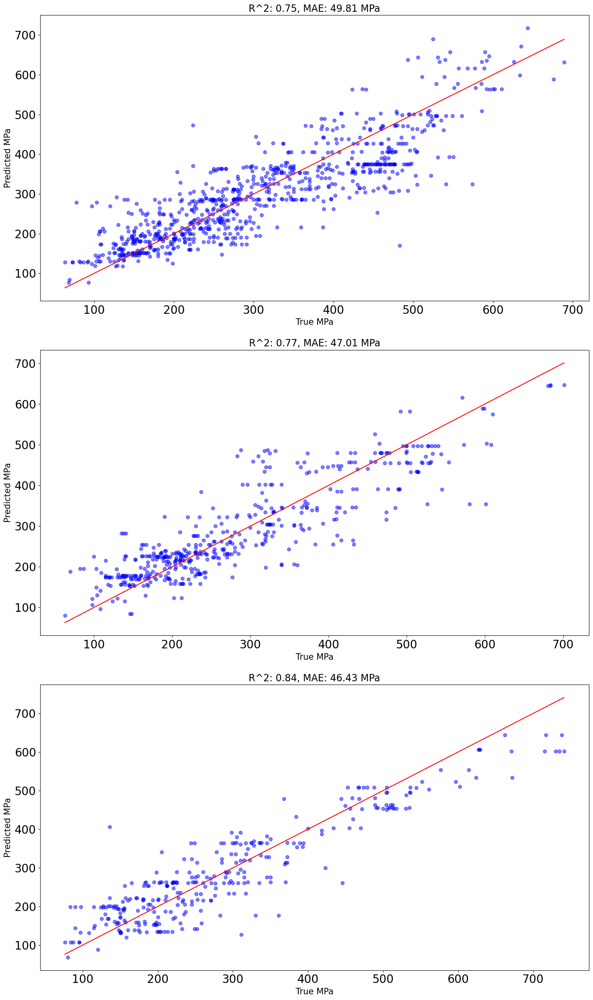

mean r2: 0.7909027525064175
mean mae: 46.74927370614895


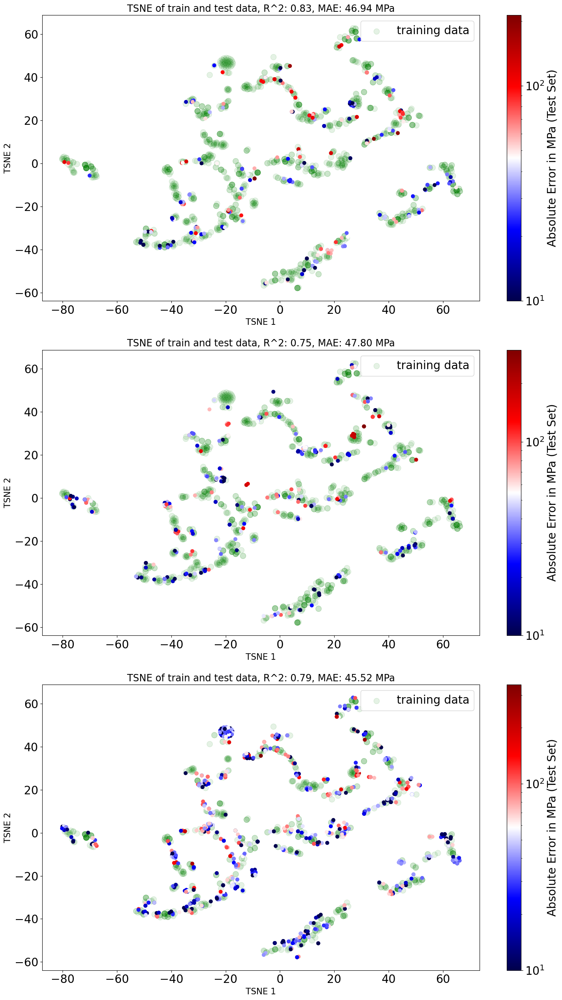

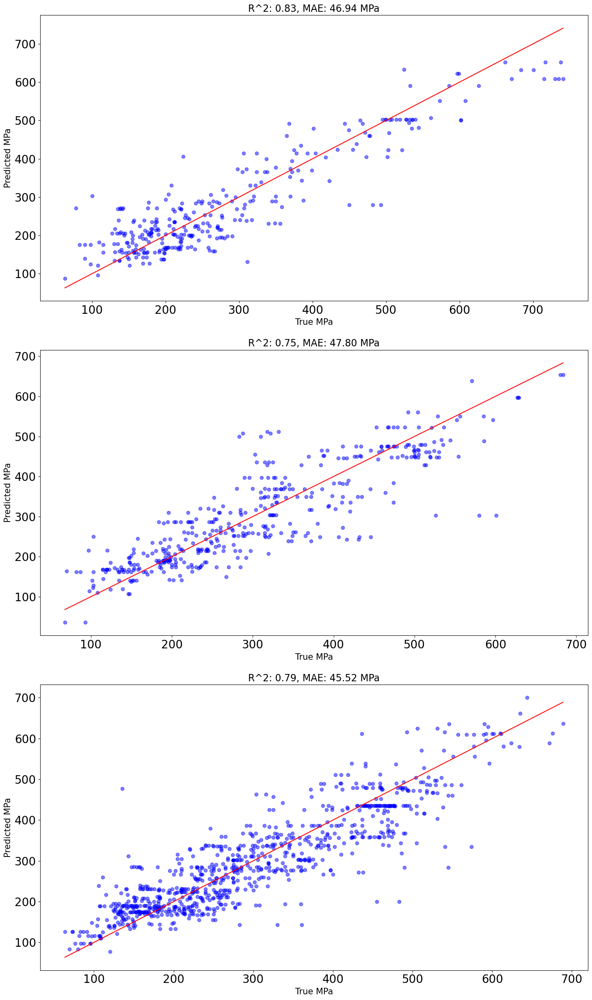

mean r2: 0.7852936048645943
mean mae: 46.651677785473254


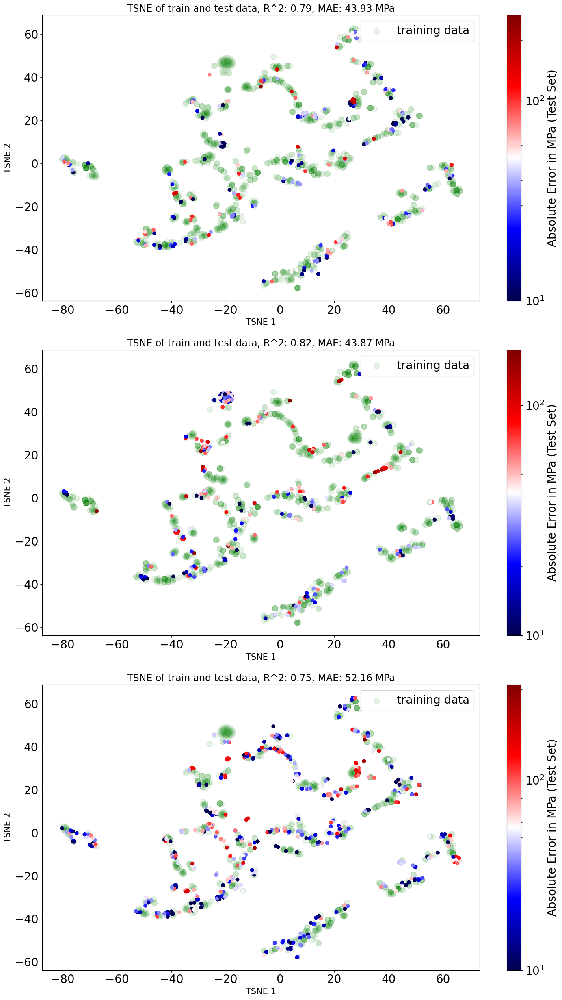

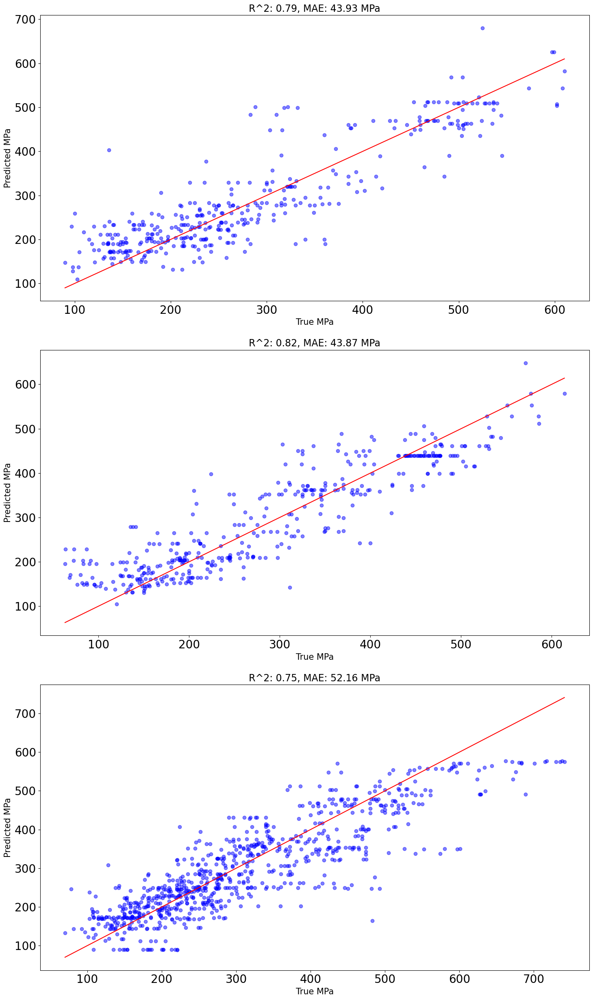

mean r2: 0.7873861958760071
mean mae: 46.75036911245766


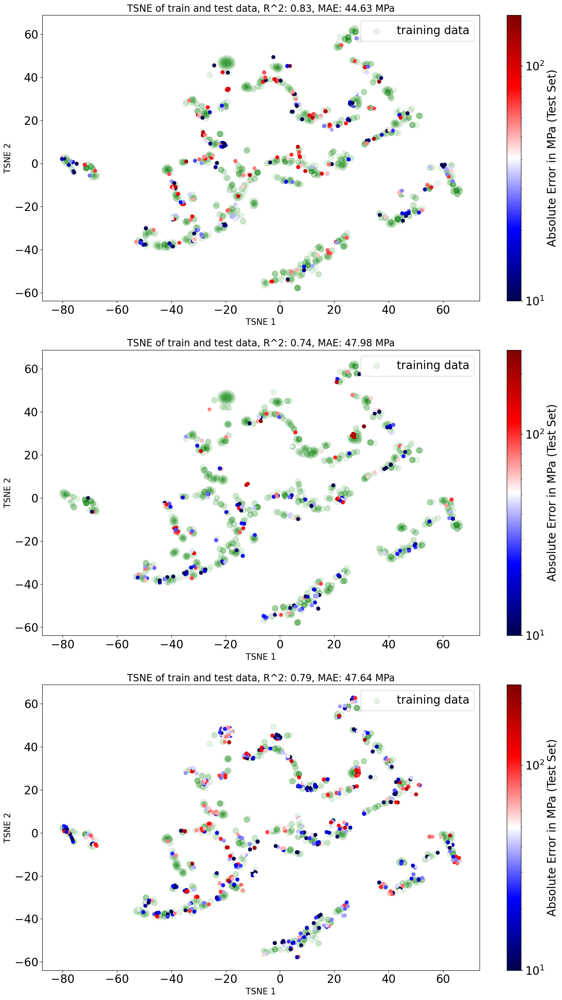

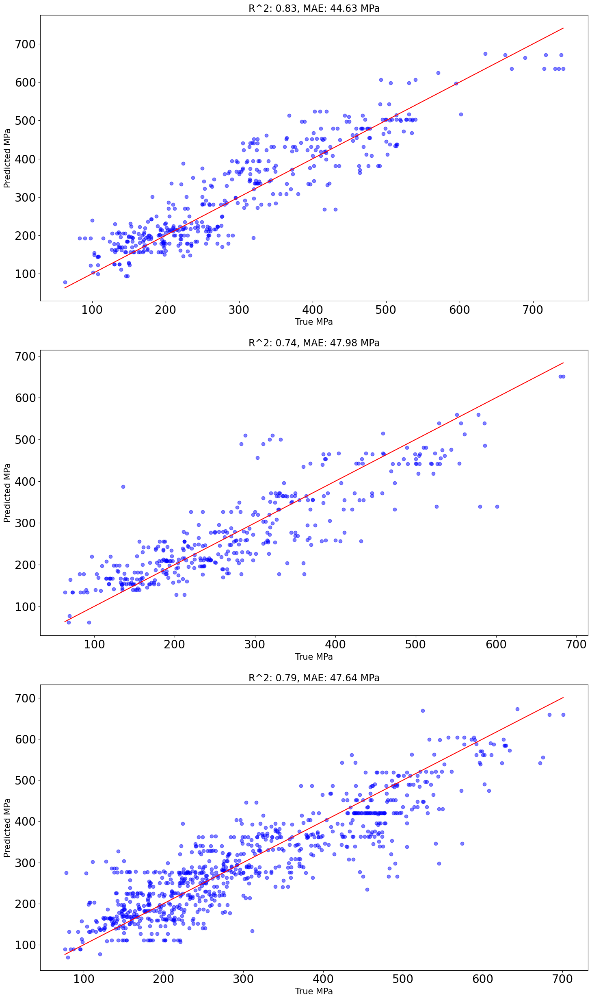

mean MAE: 46.65799094241438
std MAE: 2.837187663388188
mean R2: 0.7903590435893432
std R2: 0.03516311386685532


In [25]:
files = df_feat_target_file["file"].loc[setup[2].index].values
chem_val_cols = relevant_cols["chem_val_cols"]
chem_val = df_feat[chem_val_cols]
model_name = setup[0]
feat = setup[1].iloc[:, [i for i, el in enumerate(best_individual[:setup[1].shape[1]]) if el]]
y = setup[2]
hyperparams = [el for el in best_individual[setup[1].shape[1]:]]
p = {el["name"]: el["current"] for el in hyperparams}
assert (y.index == feat.index).all(), "index of features and target should match!"
maes = []
r2s = []
for seed in range(N_TRIES_CV):
    r, m = evaluation.cv_with_file_and_element_grouping(feat, y, p, model_name, chem_val, files, chem_val_cols, scaling_method, enable_plots=ENABLE_PLOTS, seed=seed, img_dir=SAVE_PATH_IMG, n_folds=3)
    maes.extend(m)
    r2s.extend(r)

maes_all_feat = maes
r2s_all_feat = r2s
print("mean MAE:", np.mean(maes_all_feat))
print("std MAE:", np.std(maes_all_feat))

print("mean R2:", np.mean(r2s_all_feat))
print("std R2:", np.std(r2s_all_feat))

### Perform 4-fold cross validation without phase features

dropping phase features: ['Mn-based group']
mean r2: 0.7896084143456087
mean mae: 46.81339747257321


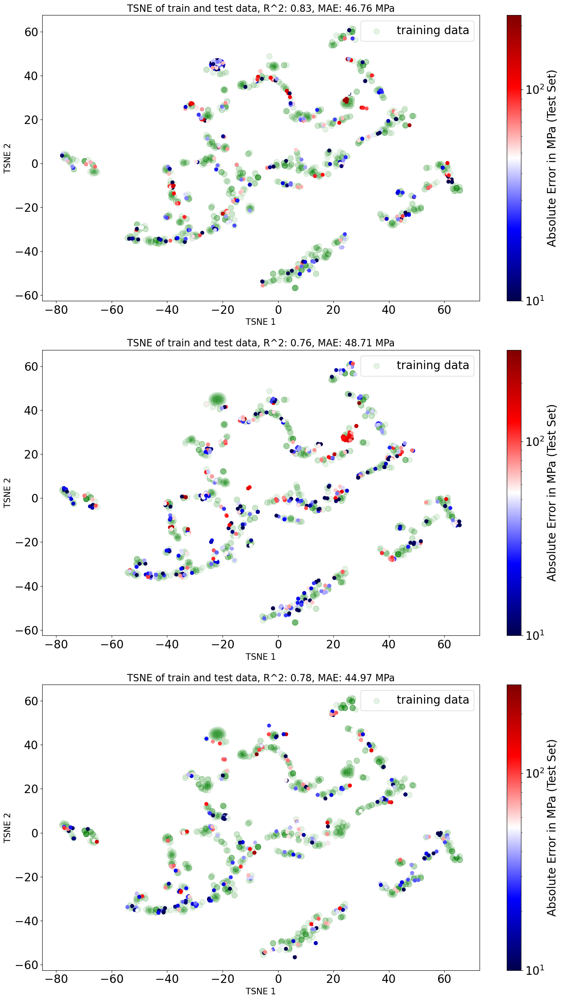

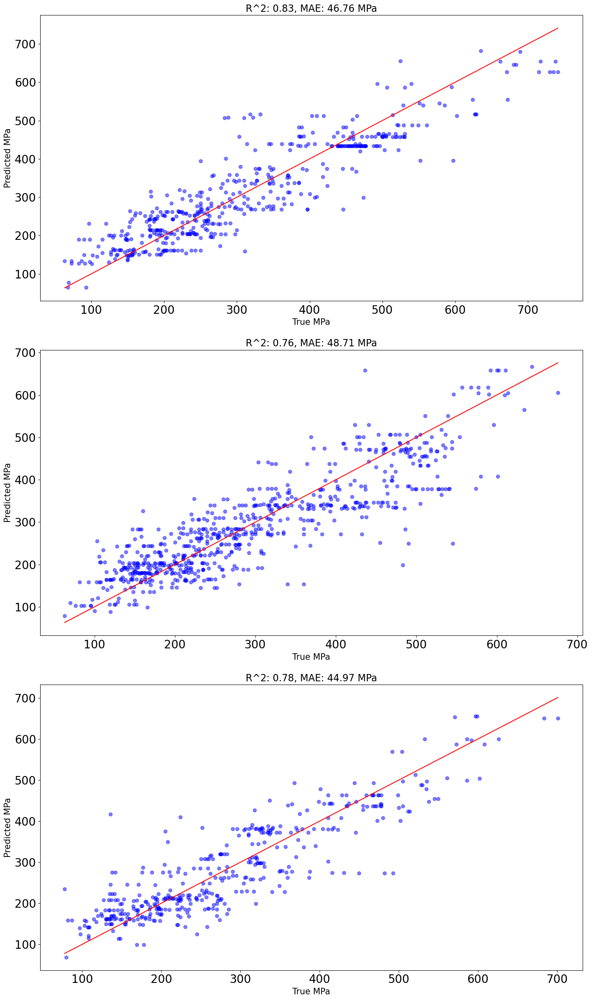

mean r2: 0.7830551794413138
mean mae: 47.98694426831623


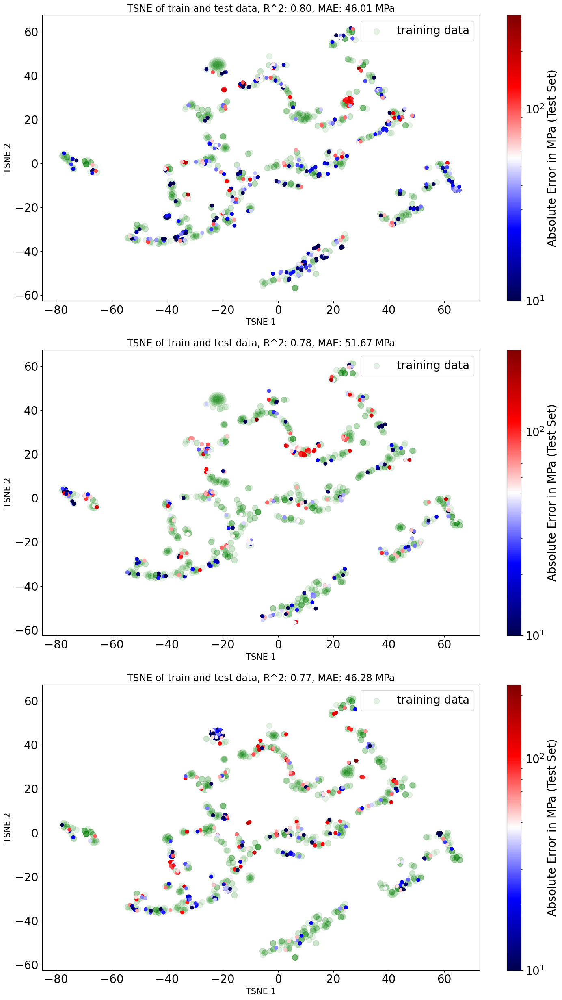

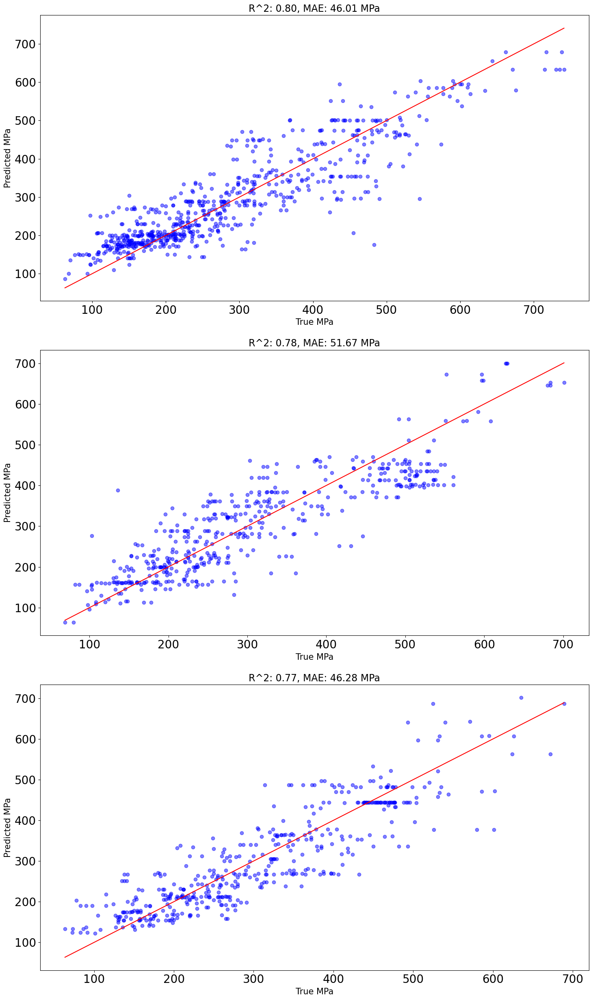

mean r2: 0.782294324148667
mean mae: 48.20336673200927


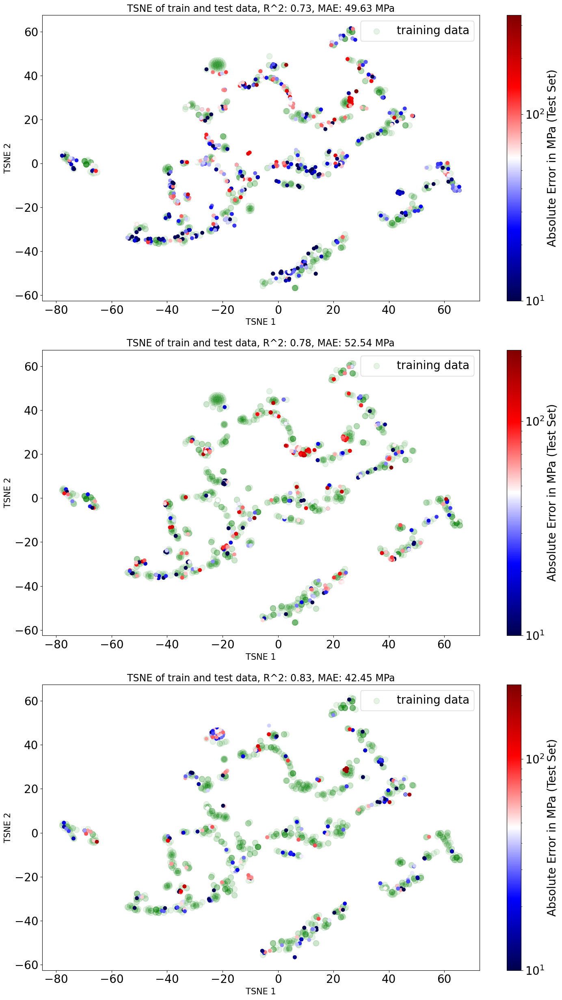

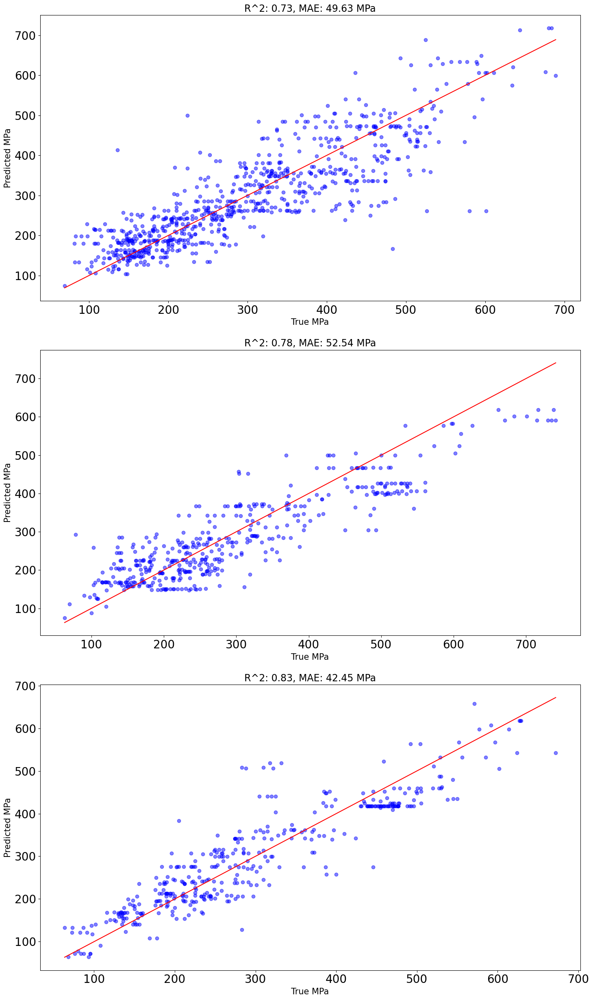

mean r2: 0.7646449471078522
mean mae: 49.09644299397227


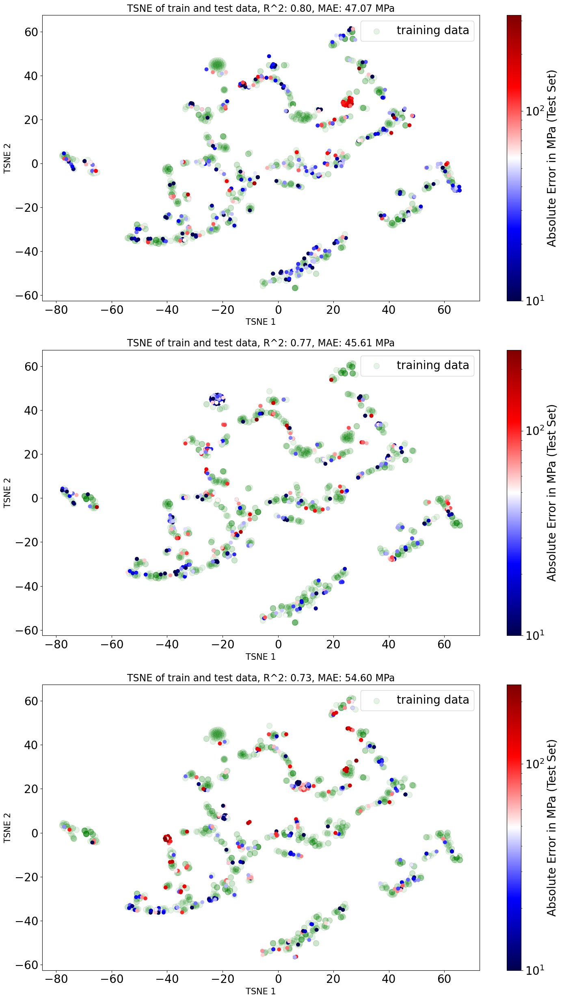

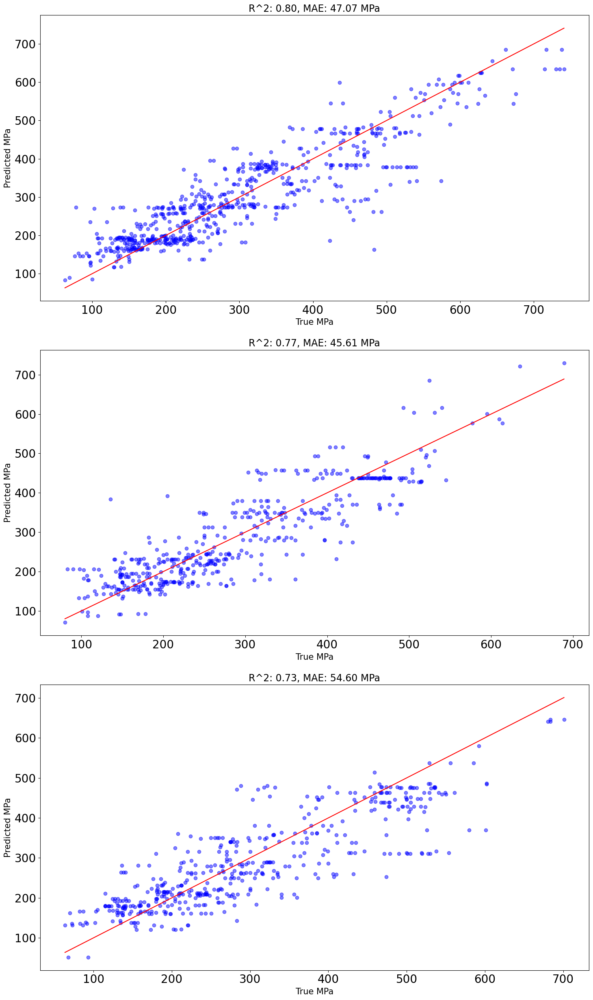

mean r2: 0.763677616287664
mean mae: 47.85697615455138


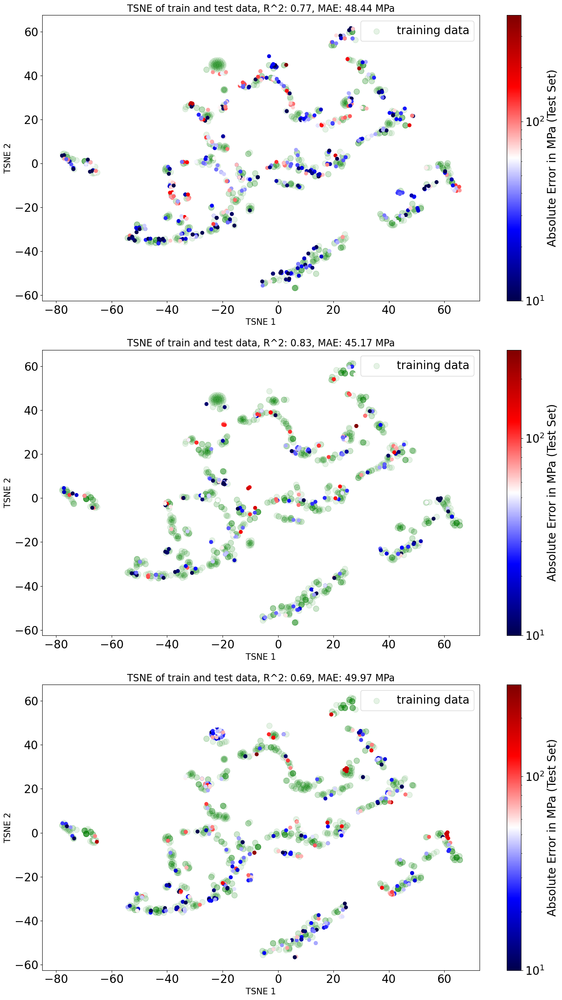

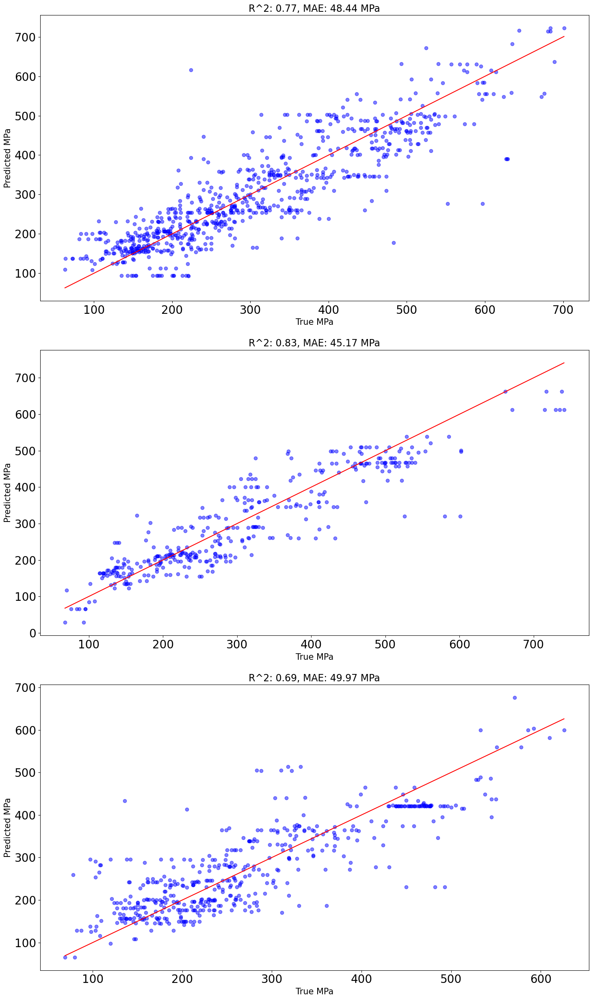

mean r2: 0.7855808509052662
mean mae: 47.70789204107376


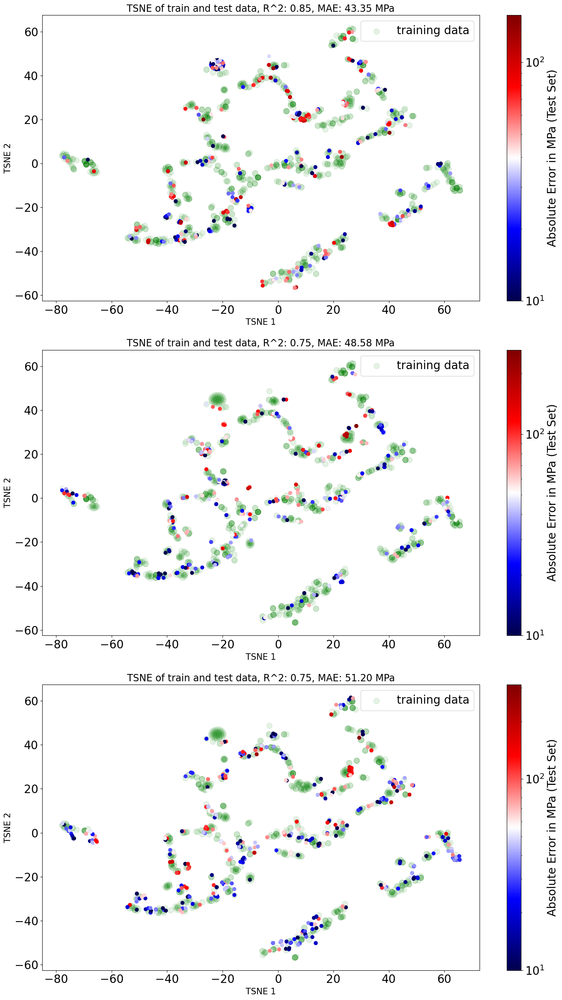

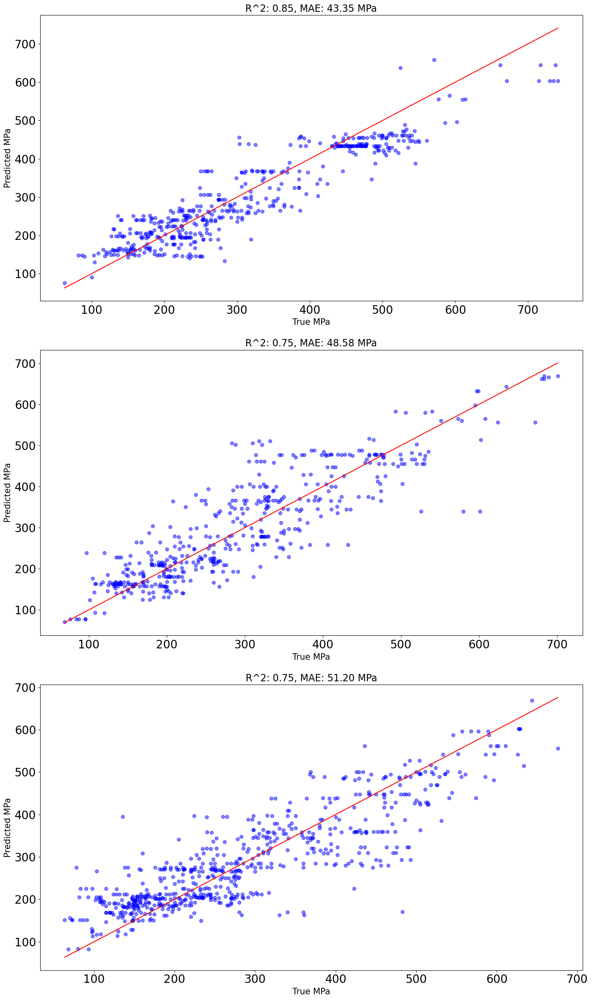

mean r2: 0.7815744697194681
mean mae: 48.46287695157496


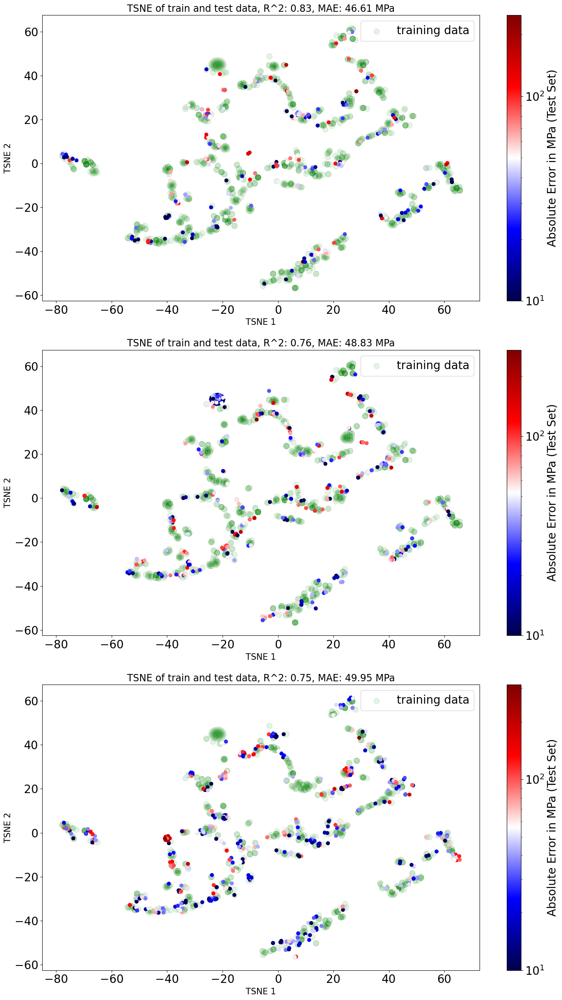

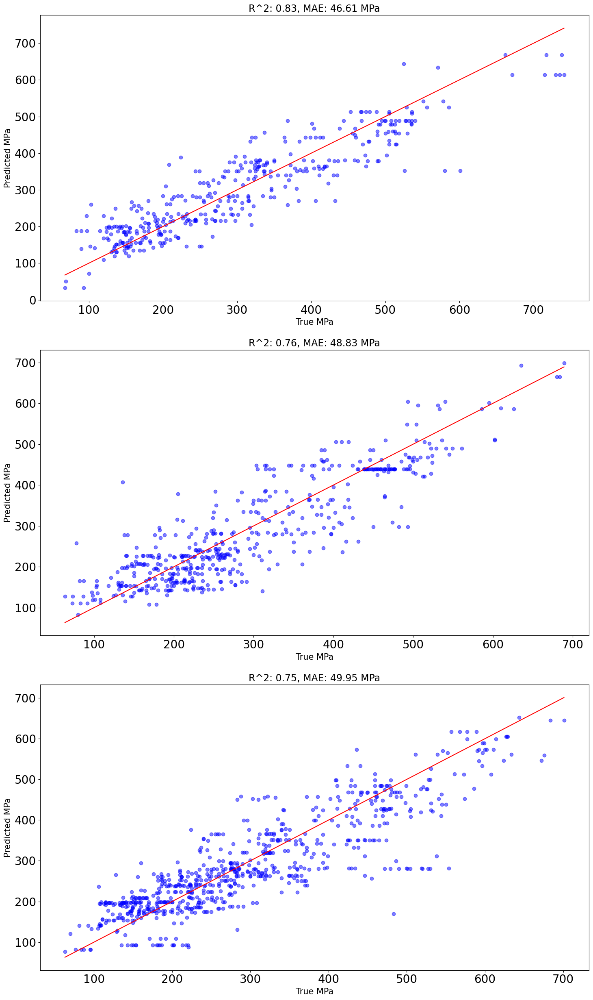

mean r2: 0.8061945800361491
mean mae: 45.419938840803326


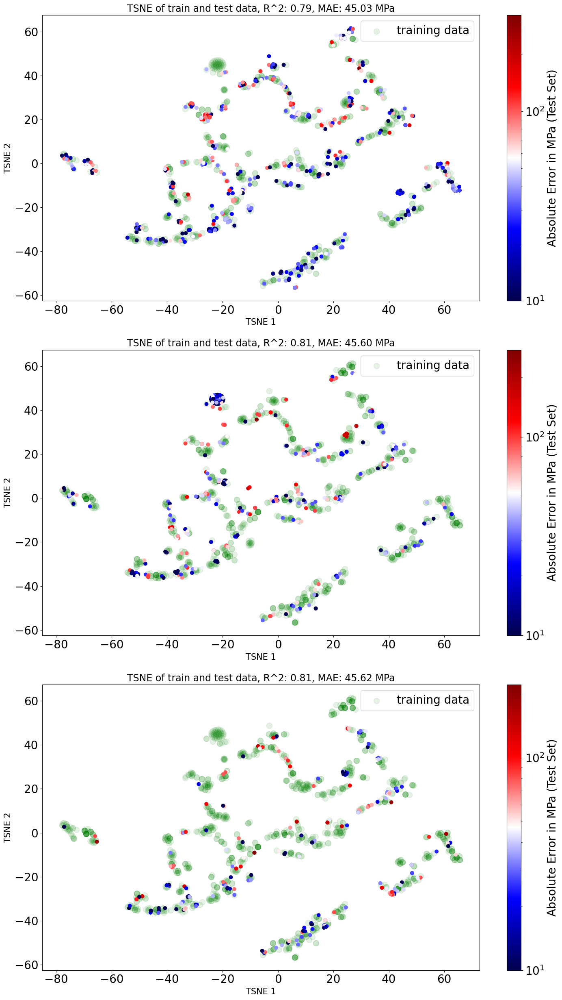

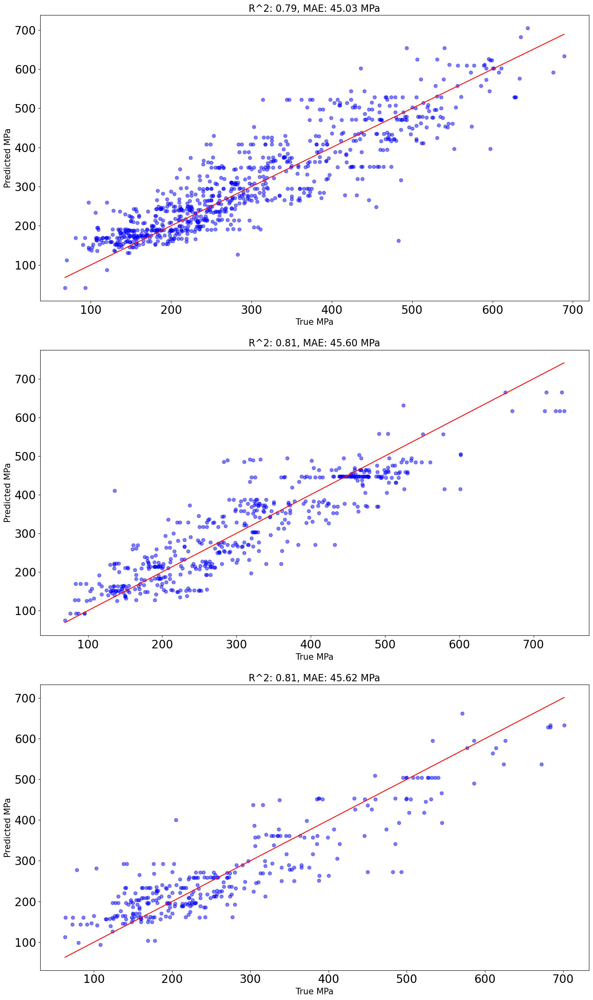

mean r2: 0.7942097806385799
mean mae: 47.00746534132882


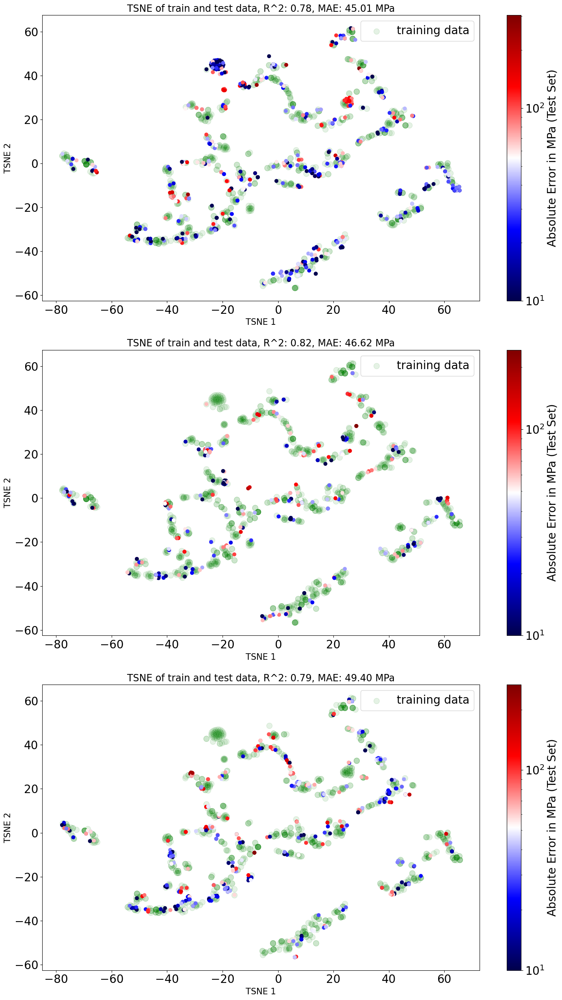

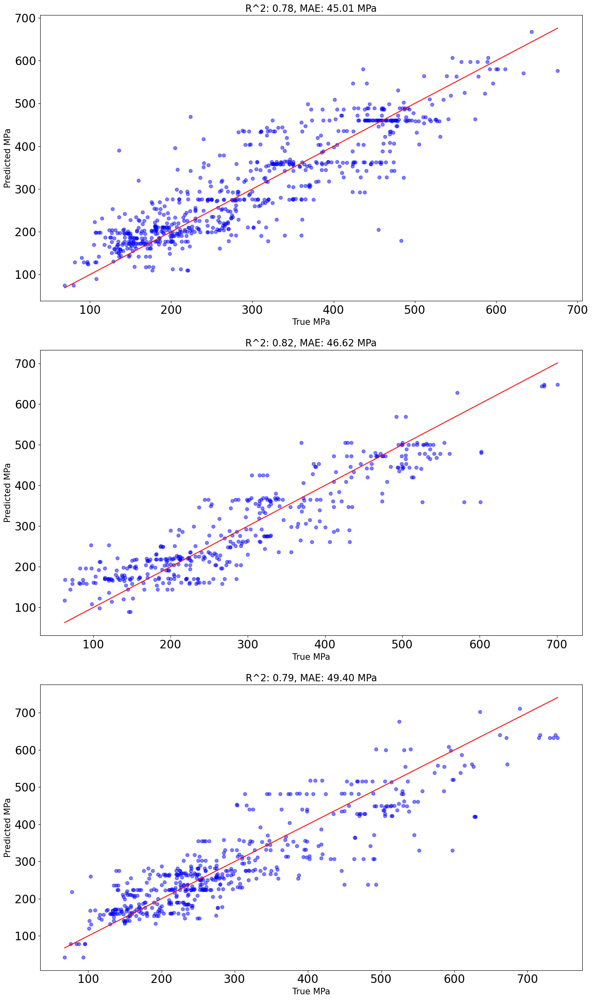

mean r2: 0.8038607928200042
mean mae: 45.585703104035225


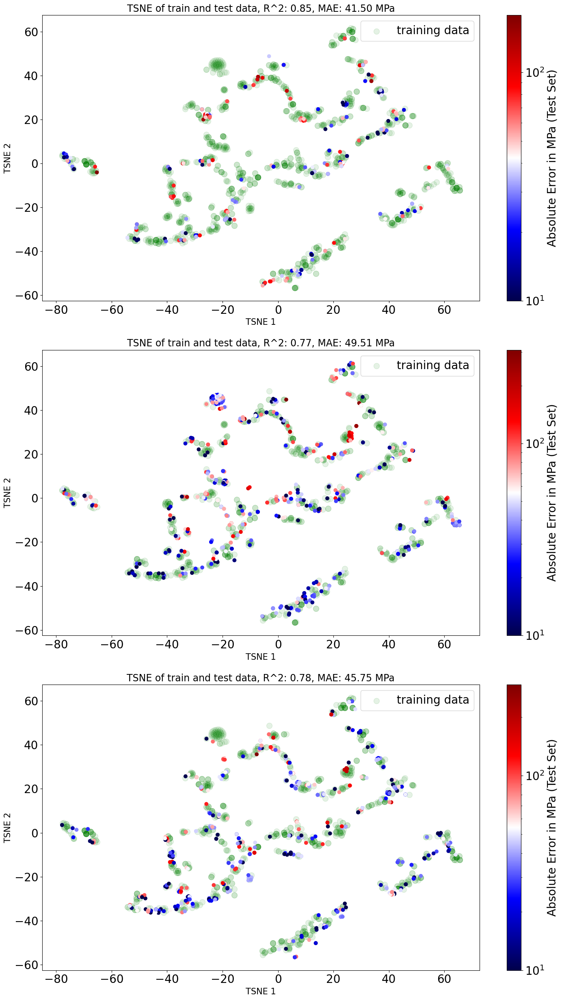

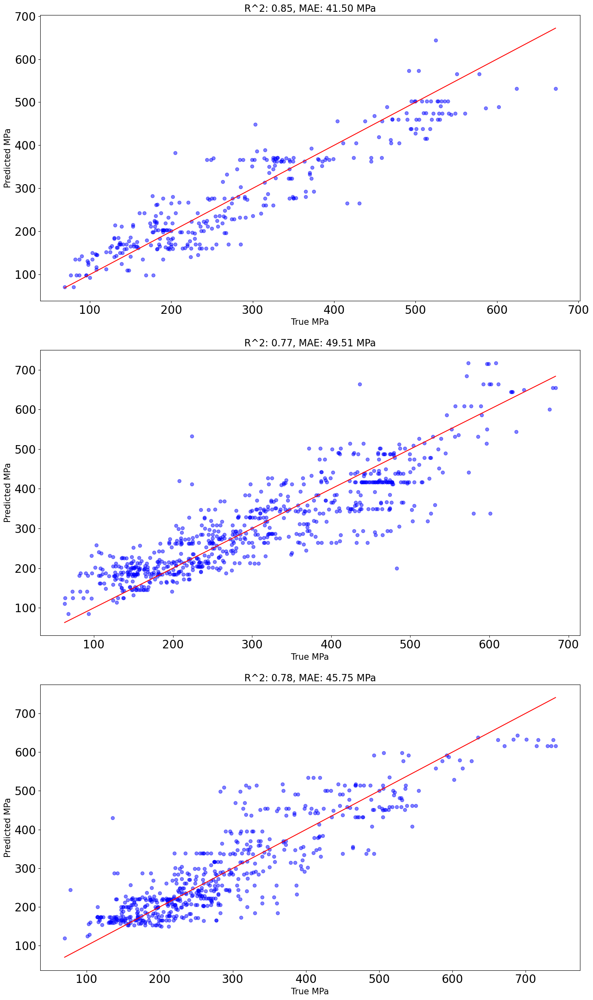

mean r2: 0.760922300541664
mean mae: 48.69172614594246


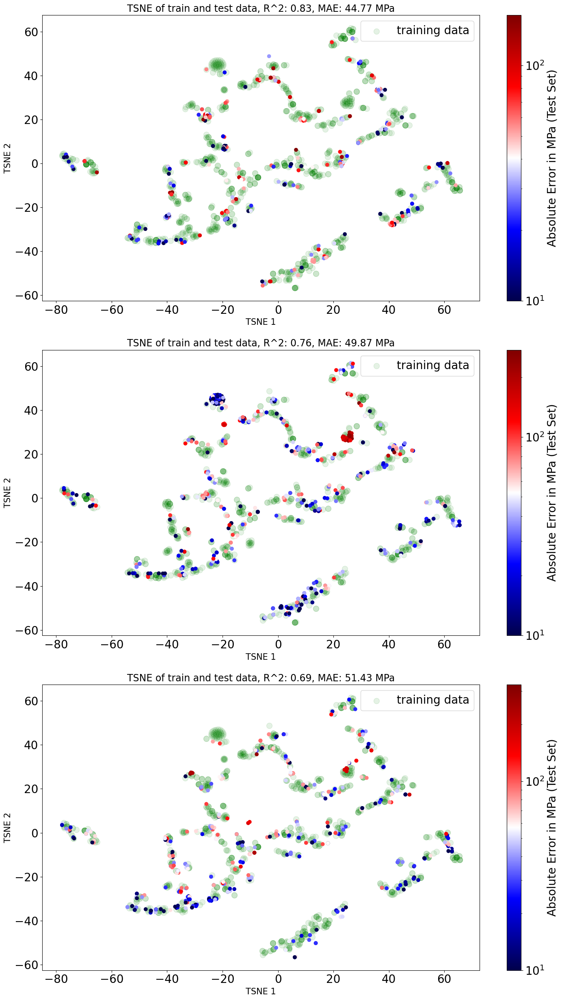

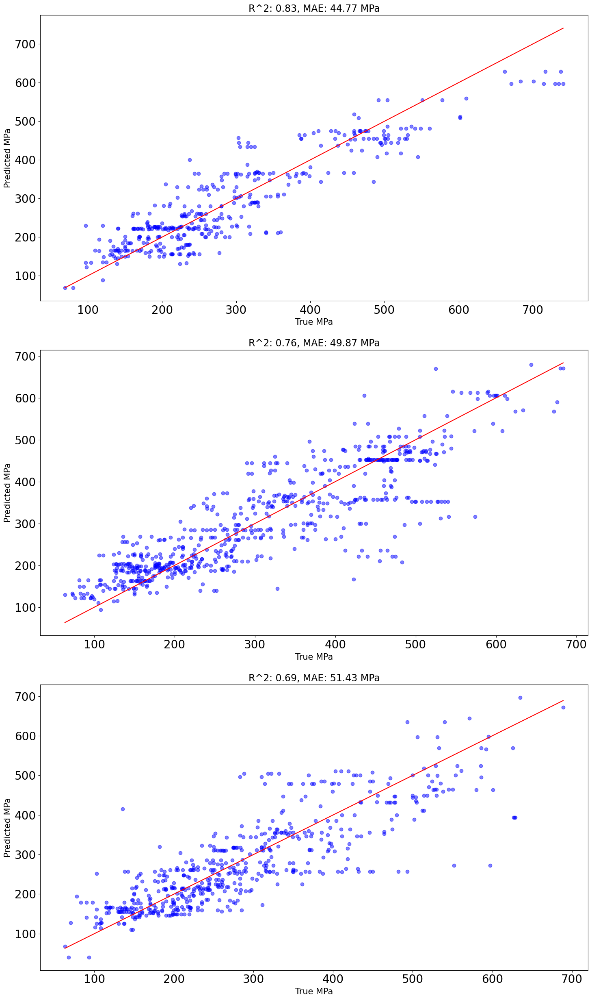

mean r2: 0.7832260299227243
mean mae: 46.9911222196381


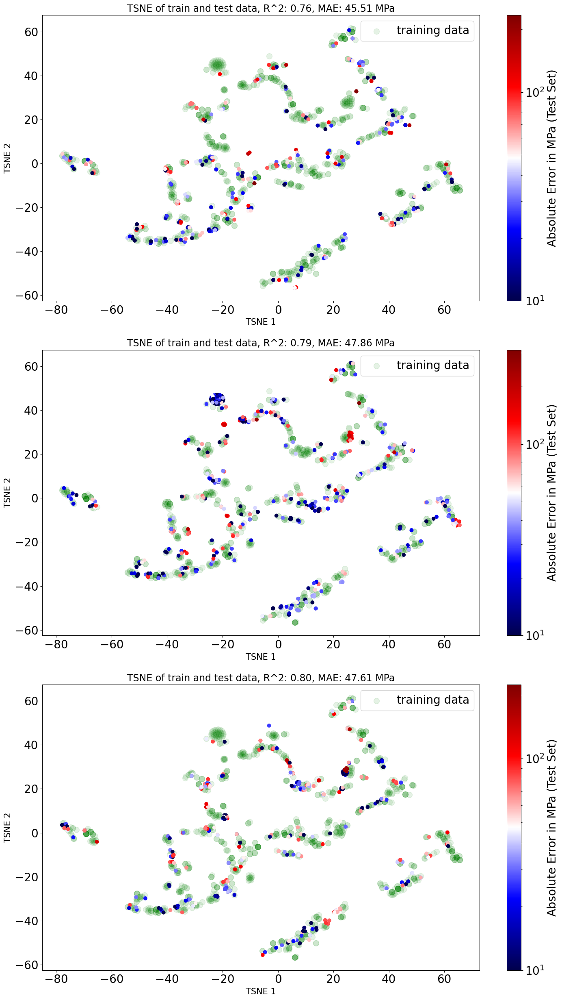

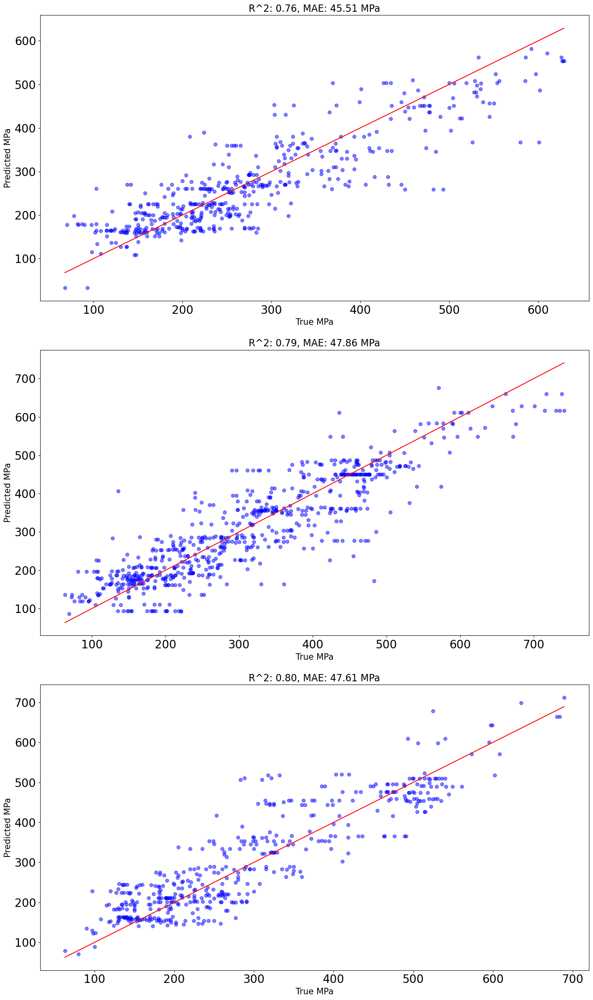

mean r2: 0.797593324047448
mean mae: 46.644026700068785


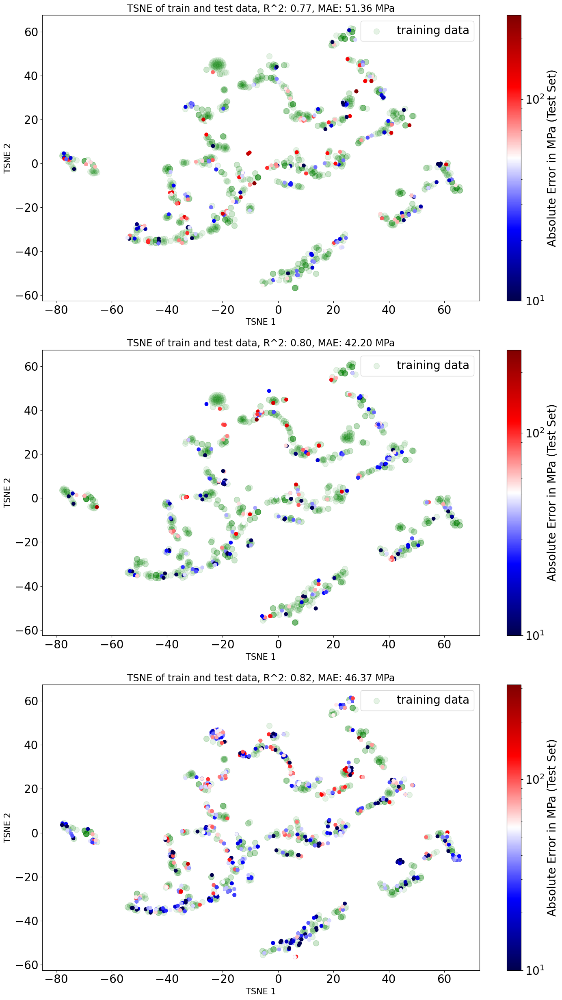

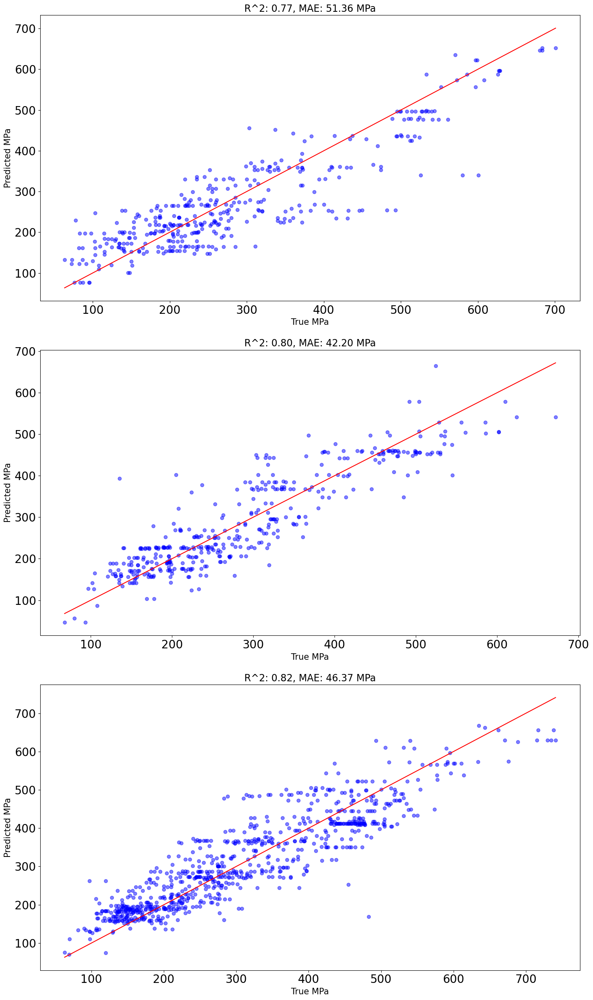

mean r2: 0.7892320073399507
mean mae: 47.21101493152694


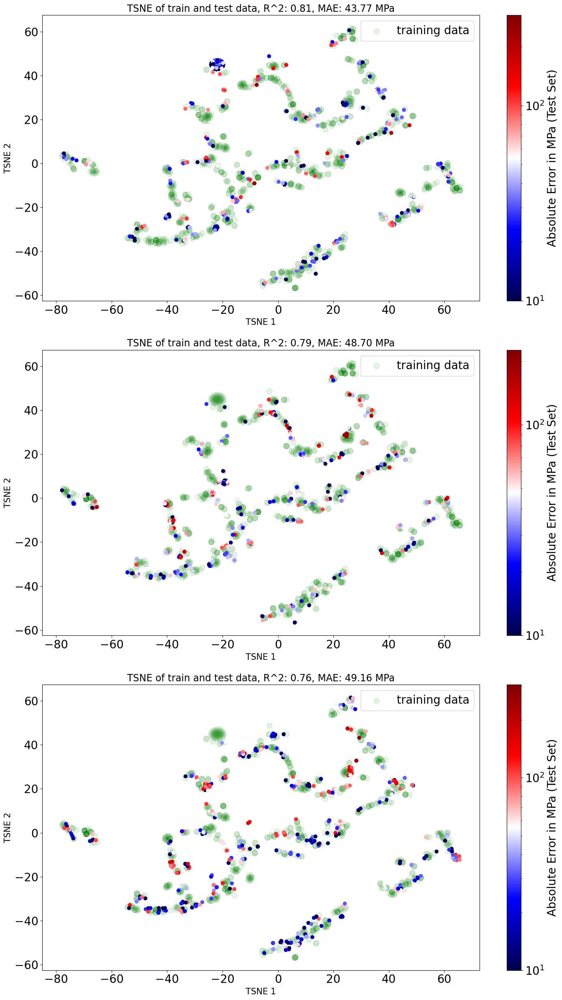

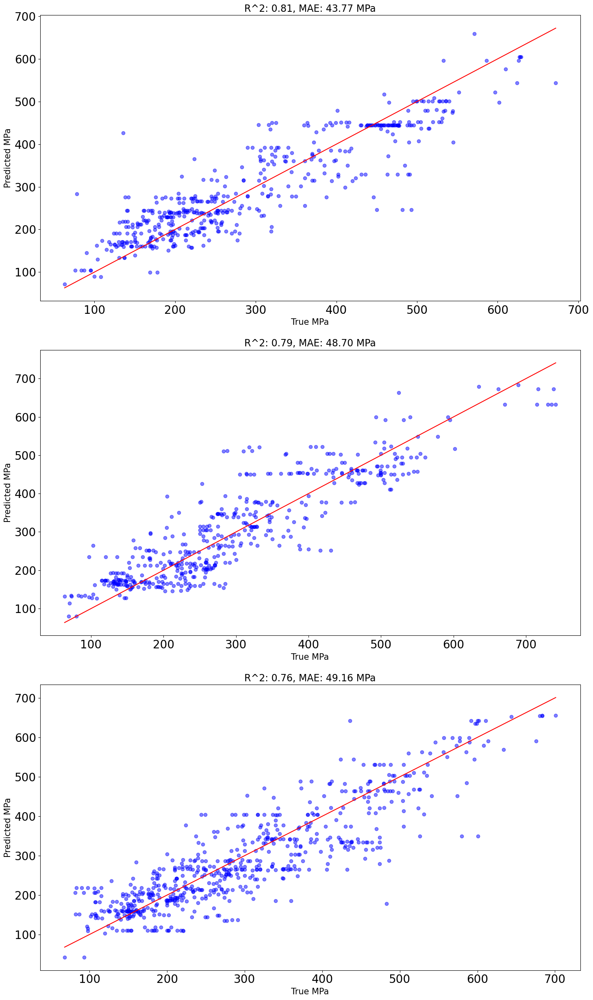

mean r2: 0.8054033594505151
mean mae: 45.31242002049709


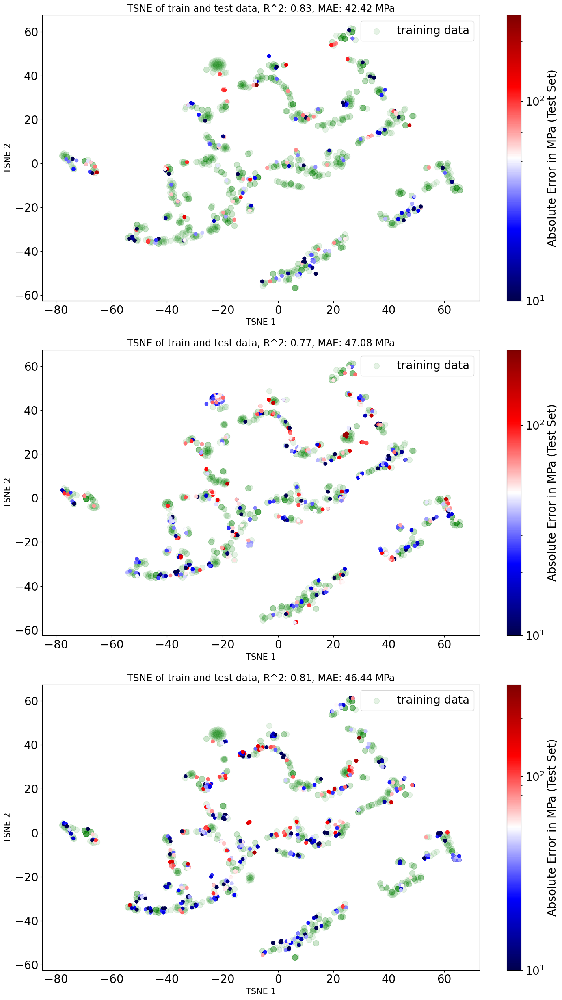

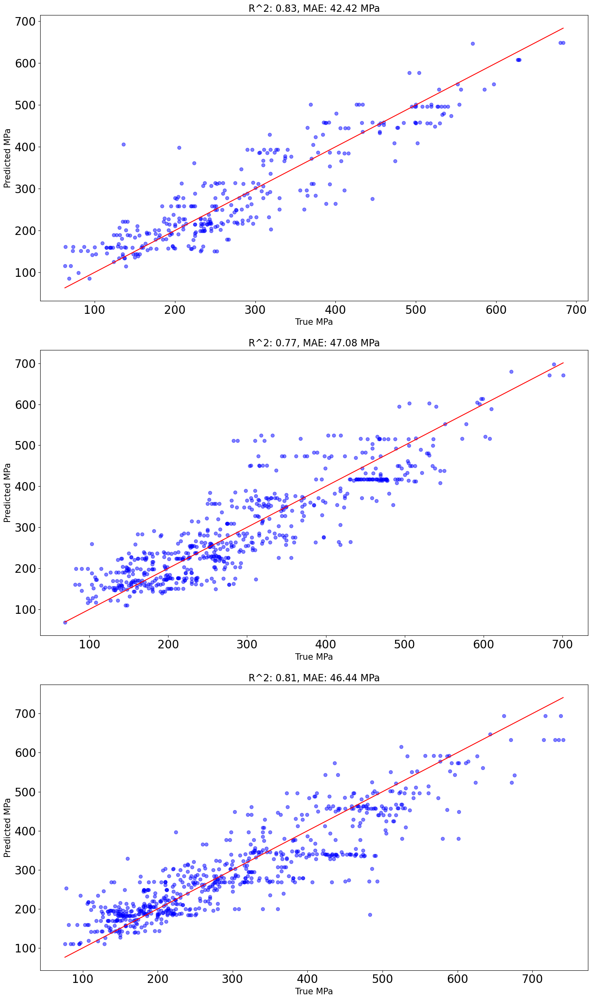

mean r2: 0.7984497260195415
mean mae: 46.65783823388178


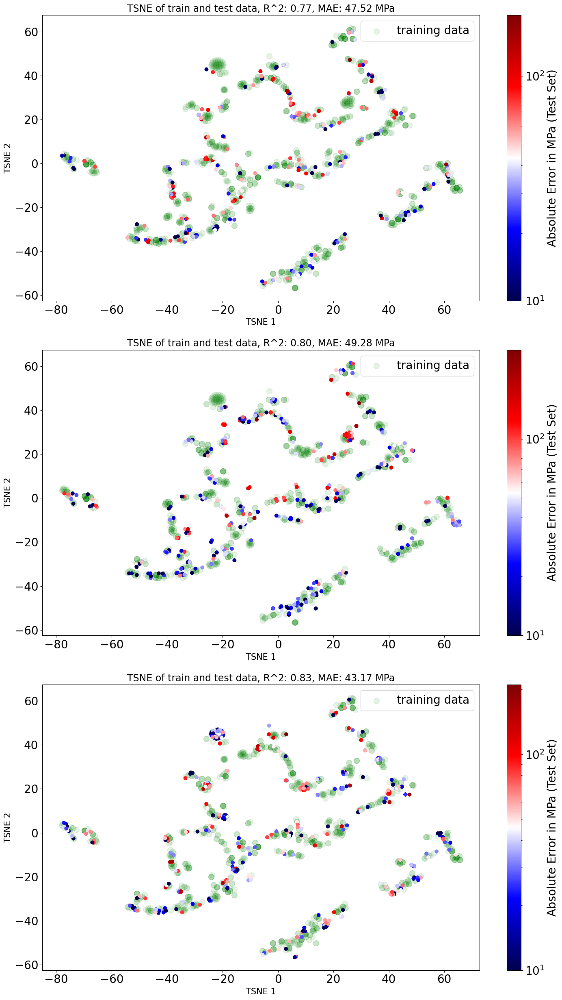

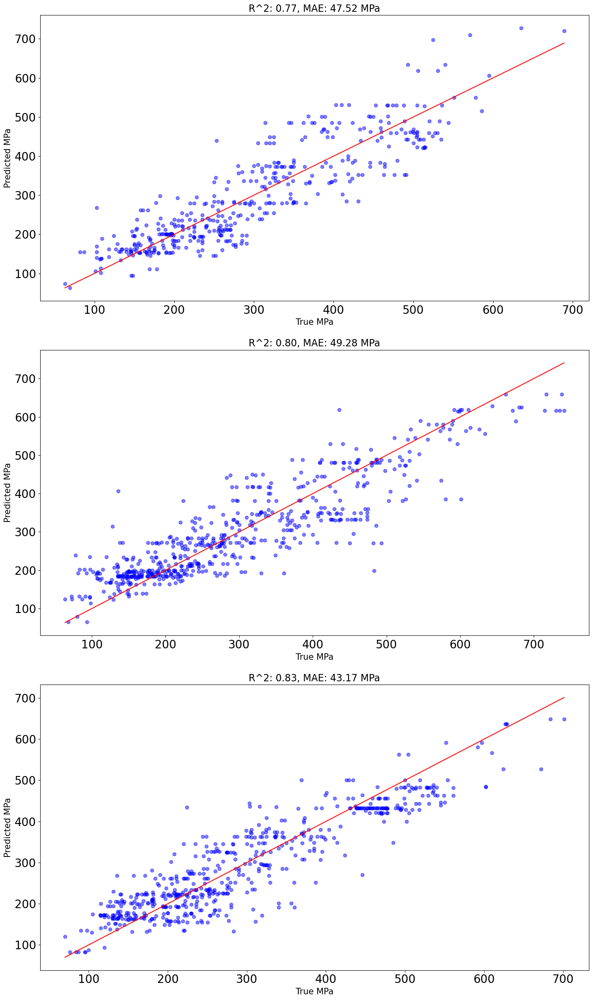

mean r2: 0.7987925801105434
mean mae: 46.87468020400741


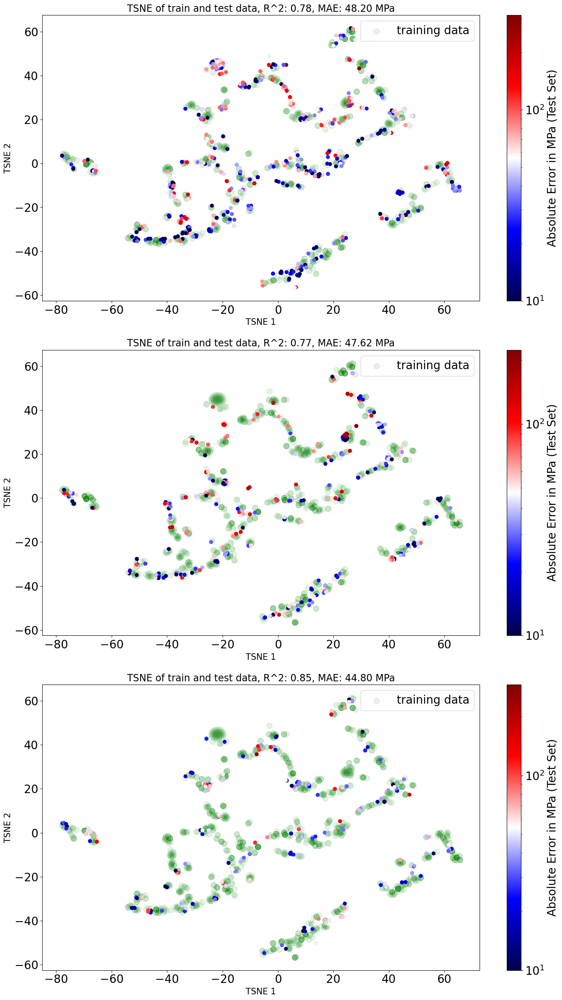

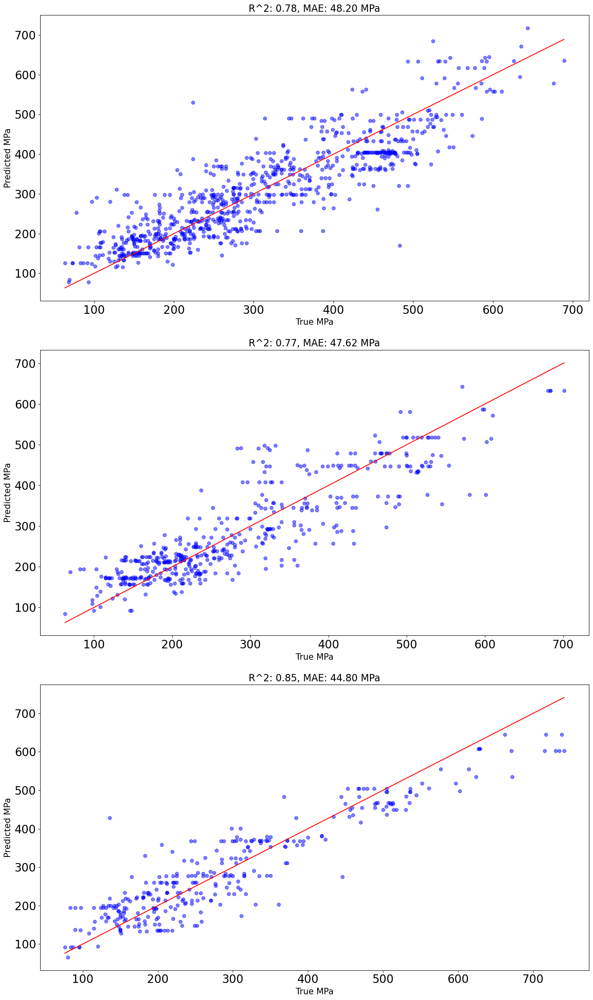

mean r2: 0.8024506528389526
mean mae: 46.05165385202025


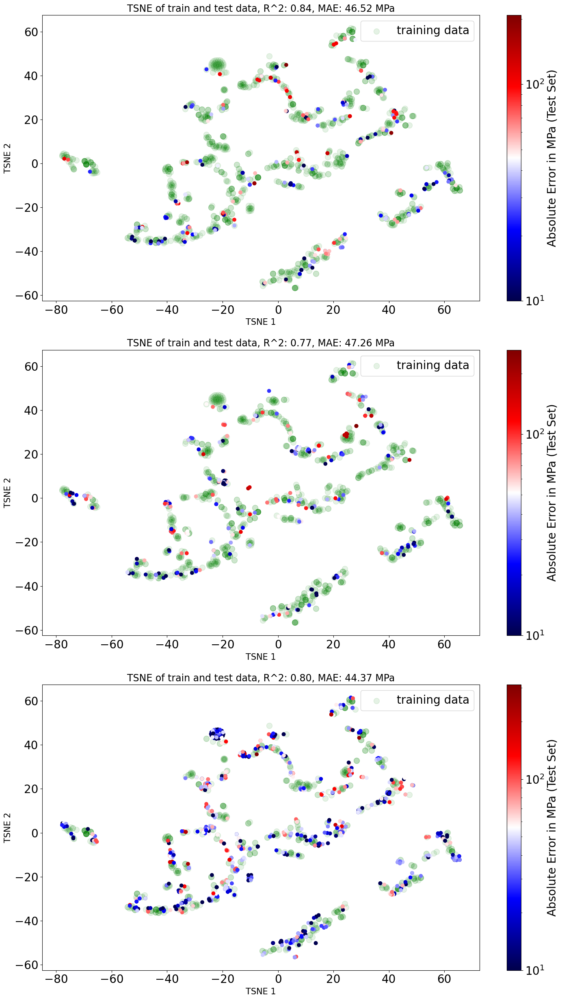

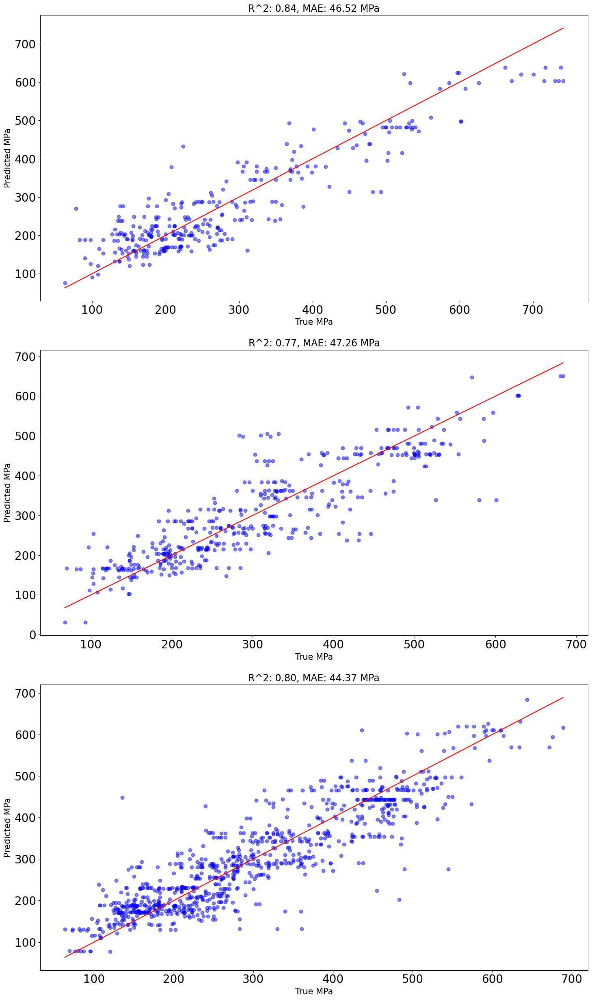

mean r2: 0.7909577673898424
mean mae: 46.20840852407313


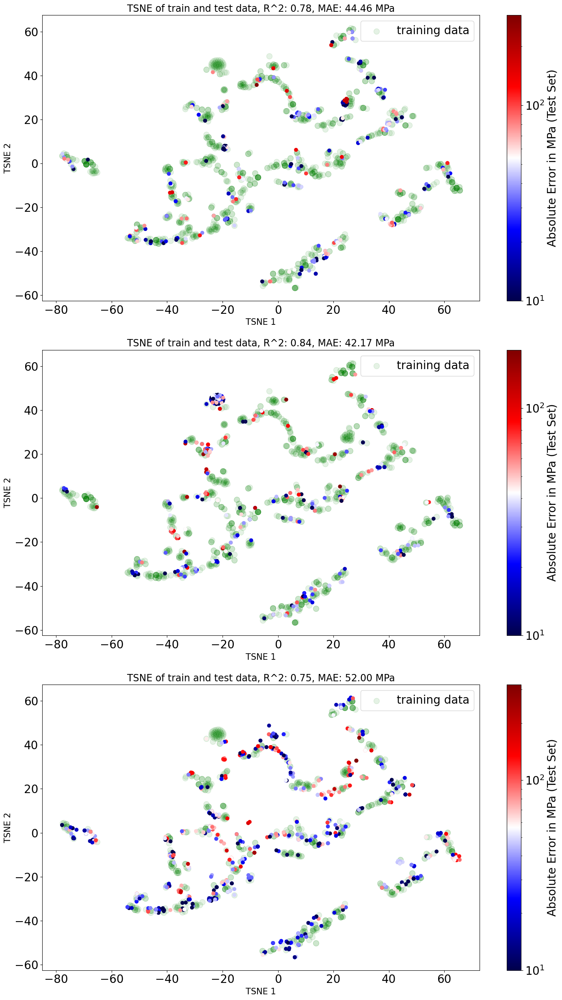

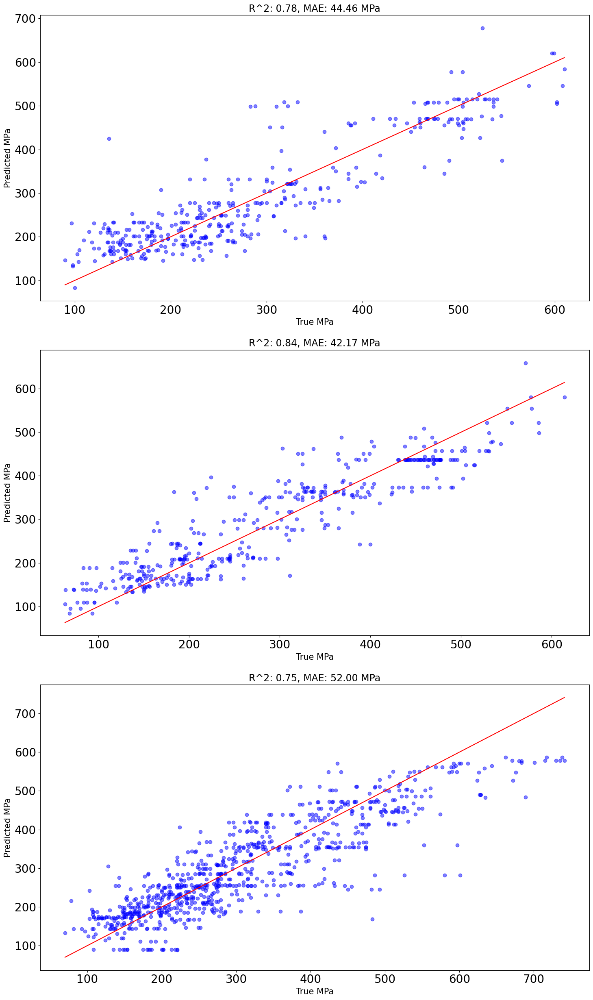

mean r2: 0.7894107696190837
mean mae: 46.937758752874494


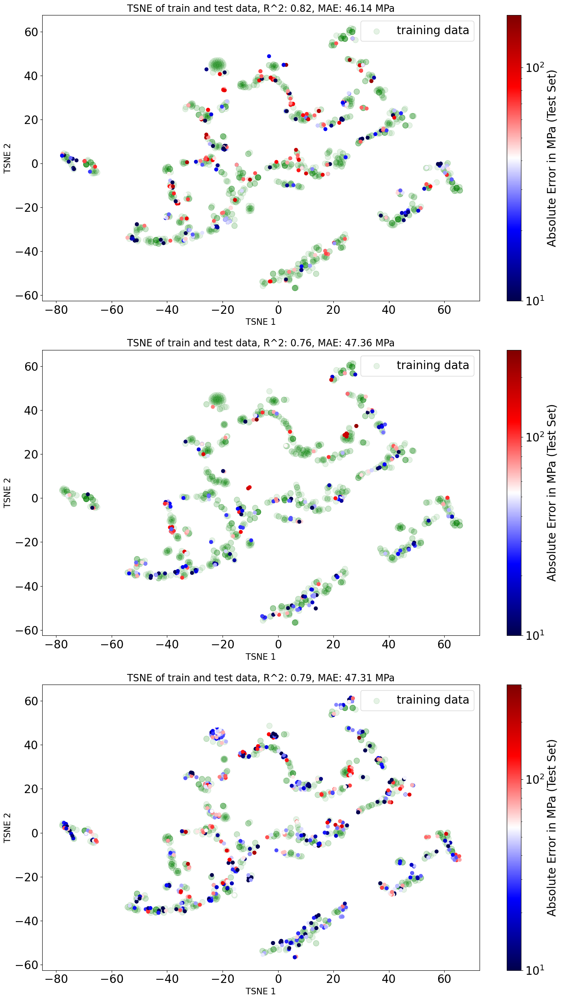

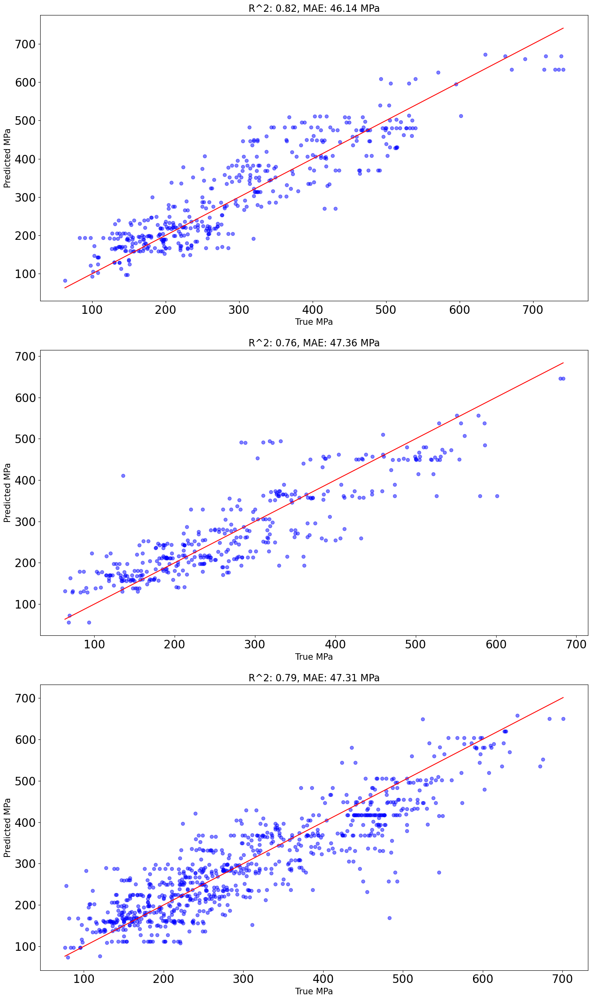

mean MAE: 47.086082674238455
std MAE: 2.802067401034391
mean R2: 0.788556973636542
std R2: 0.035199271559002425


In [26]:
files = df_feat_target_file["file"].loc[setup[2].index].values
chem_val_cols = relevant_cols["chem_val_cols"]
chem_val = df_feat[chem_val_cols]
model_name = setup[0]
#feat = setup[1].iloc[:, [i for i, el in enumerate(best_individual[:setup[1].shape[1]]) if el]]
#phase_feat_cols = [col for col in feat.columns if "scheil" in col or "equ" in col]
phase_feat_cols = [col for col in feat.columns if "cluster" in col or "based" in col]
print("dropping phase features:", phase_feat_cols)
feat = feat.drop(columns=phase_feat_cols)
y = setup[2]
hyperparams = [el for el in best_individual[setup[1].shape[1]:]]
p = {el["name"]: el["current"] for el in hyperparams}
assert (y.index == feat.index).all(), "index of features and target should match!"

maes = []
r2s = []
for seed in range(N_TRIES_CV):
    r,m = evaluation.cv_with_file_and_element_grouping(feat, y, p, model_name, chem_val, files, chem_val_cols, scaling_method, enable_plots=ENABLE_PLOTS, seed=seed, img_dir=SAVE_PATH_IMG, n_folds=3)
    maes.extend(m)
    r2s.extend(r)

maes_no_phase = maes
r2s_no_phase = r2s

print("mean MAE:", np.mean(maes_no_phase))
print("std MAE:", np.std(maes_no_phase))

print("mean R2:", np.mean(r2s_no_phase))
print("std R2:", np.std(r2s_no_phase))

### only chemical comps

mean r2: 0.7917806565775508
mean mae: 46.31367944387117


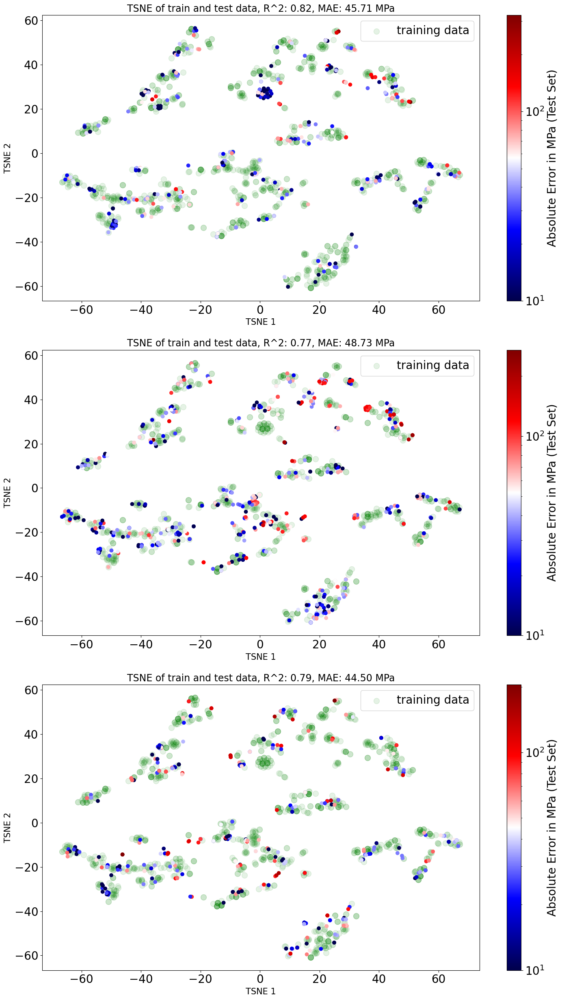

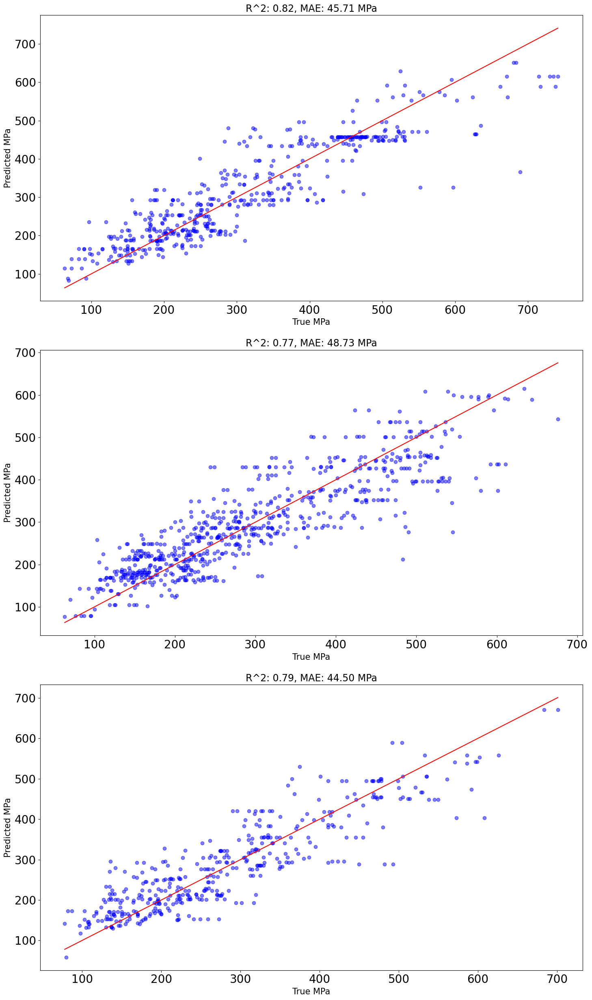

mean r2: 0.760103735658522
mean mae: 48.5080175050551


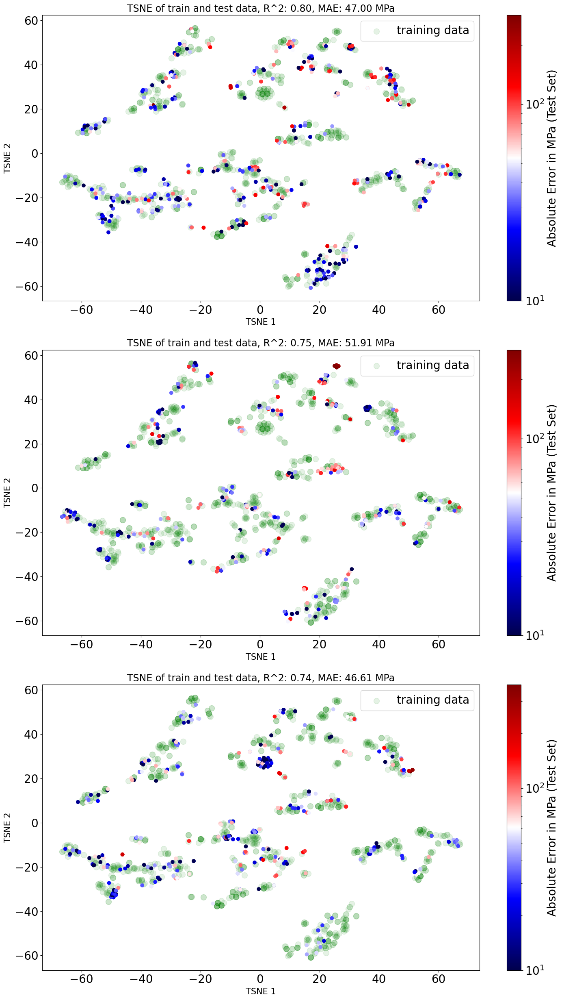

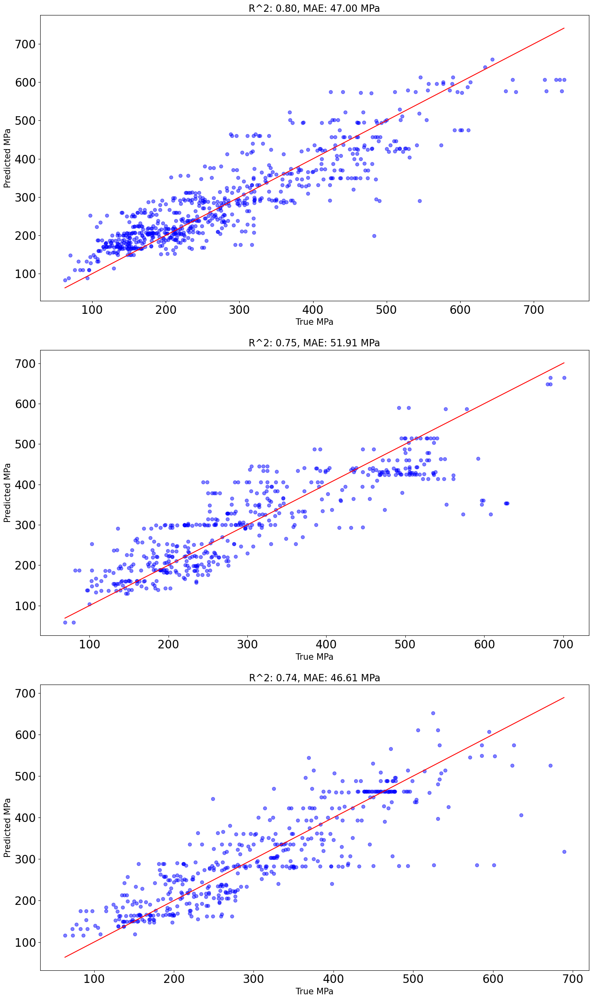

mean r2: 0.7674834124584985
mean mae: 49.2804188154437


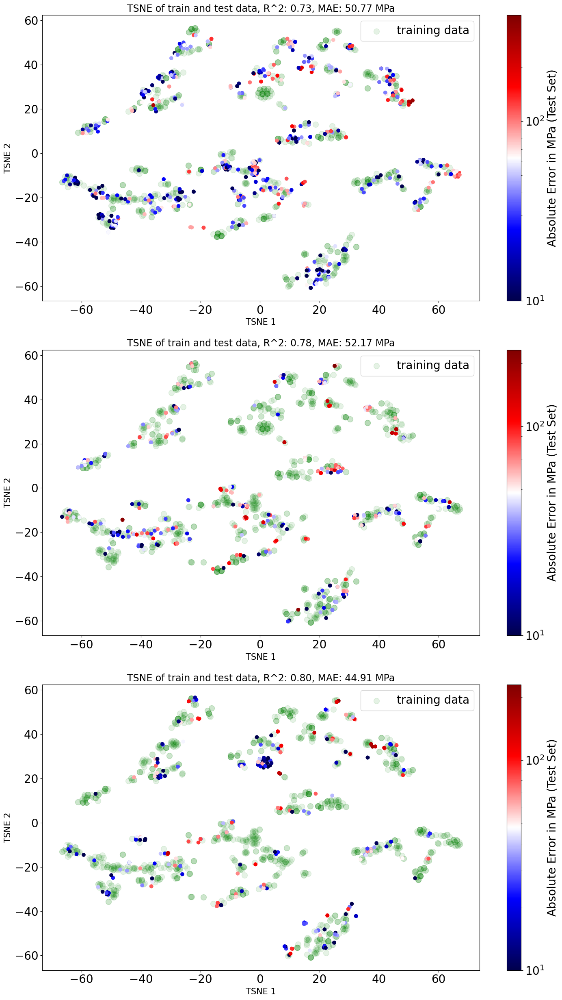

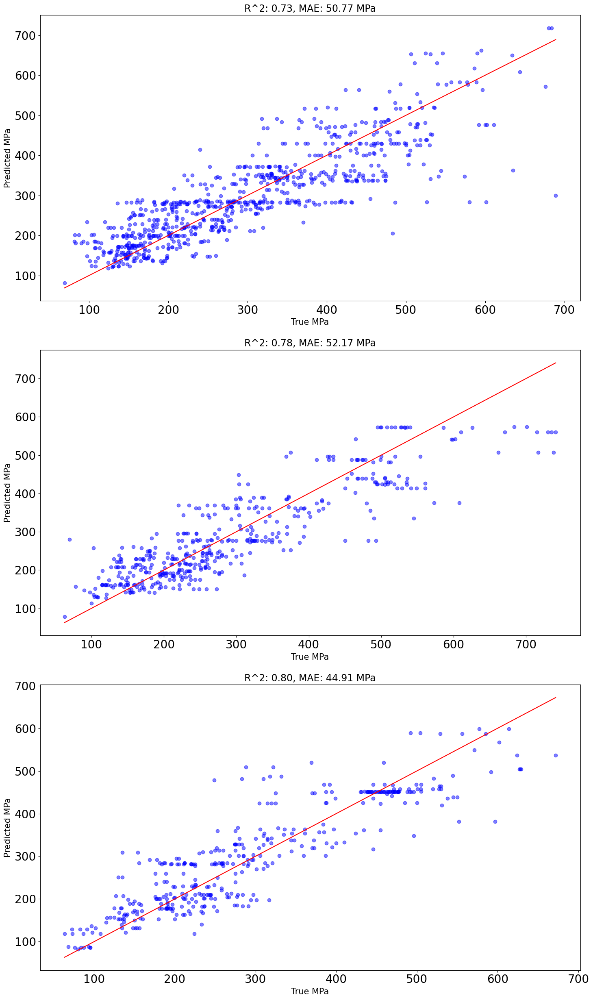

mean r2: 0.7347453054985268
mean mae: 50.4472980556927


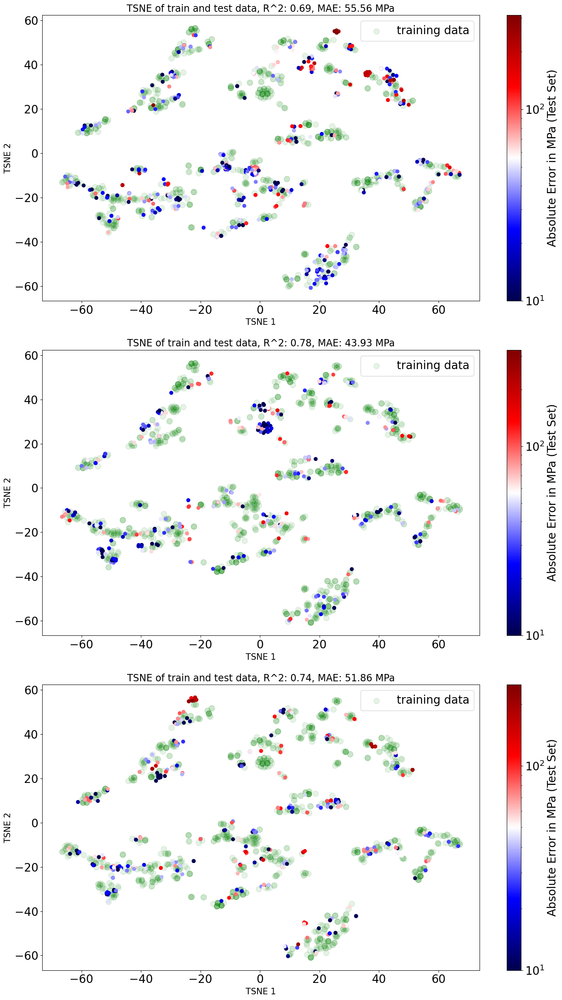

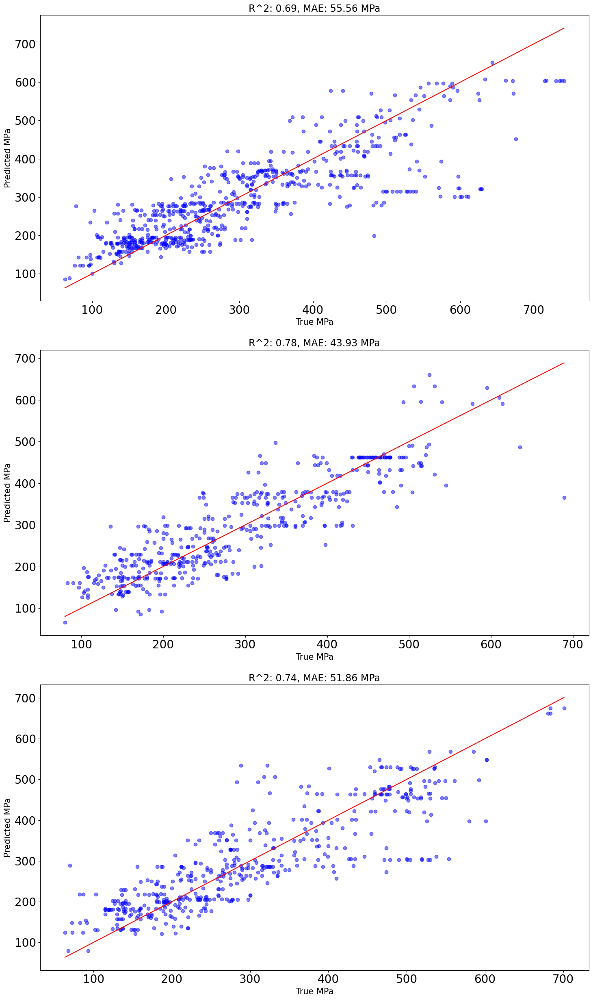

mean r2: 0.7679453416540426
mean mae: 47.327396608404946


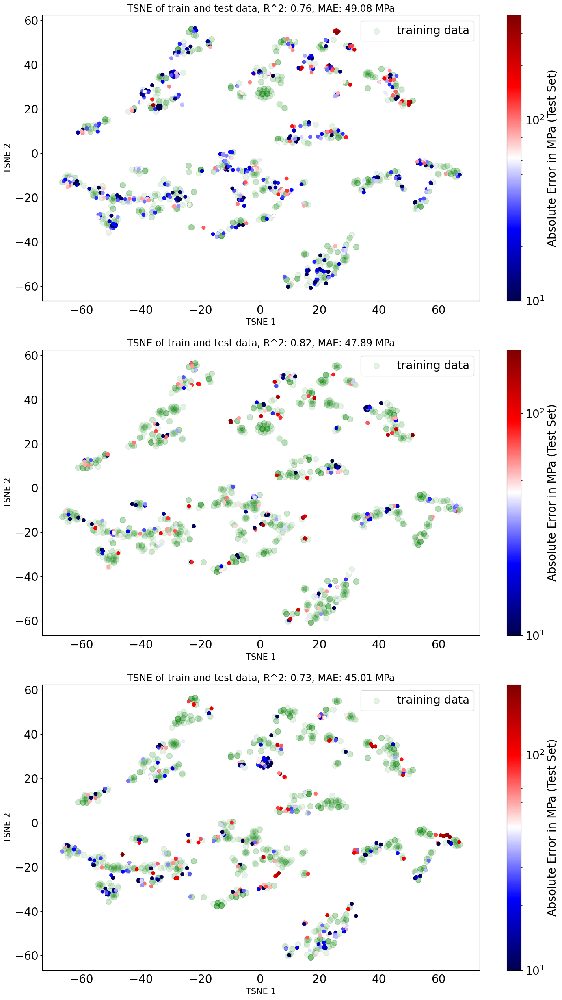

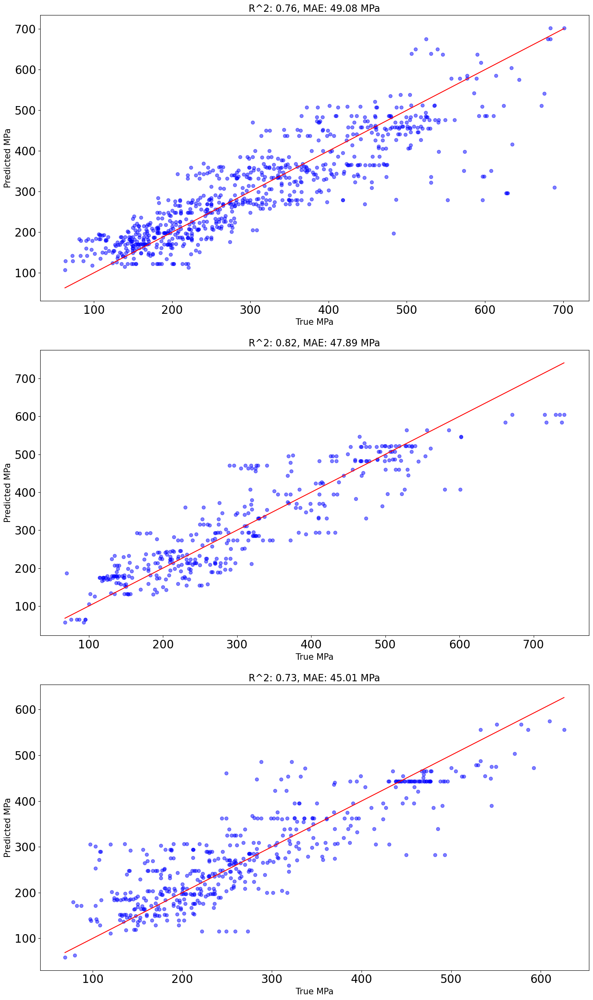

mean r2: 0.7840969760720427
mean mae: 46.24741709132346


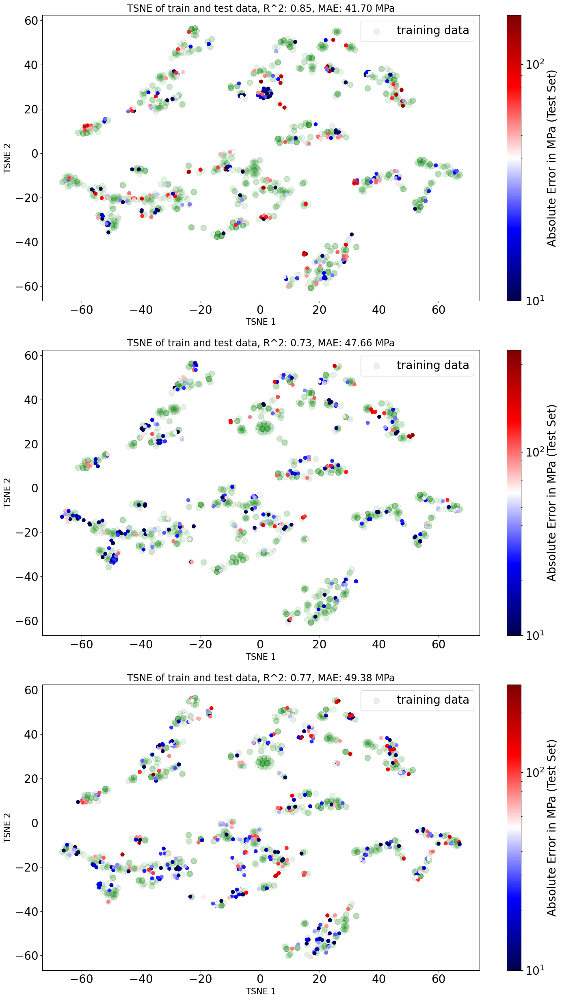

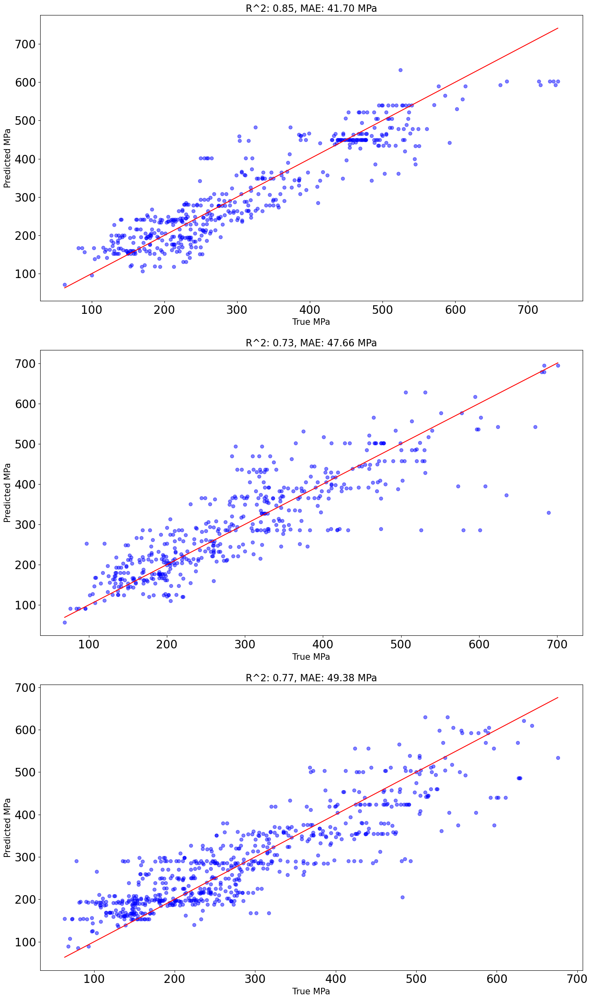

mean r2: 0.7610919057396593
mean mae: 49.08528093370756


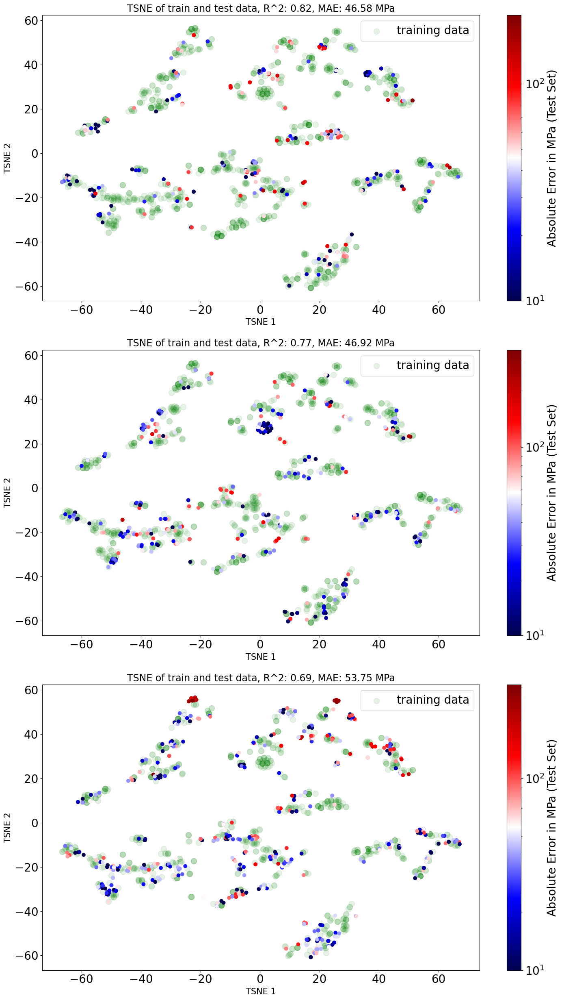

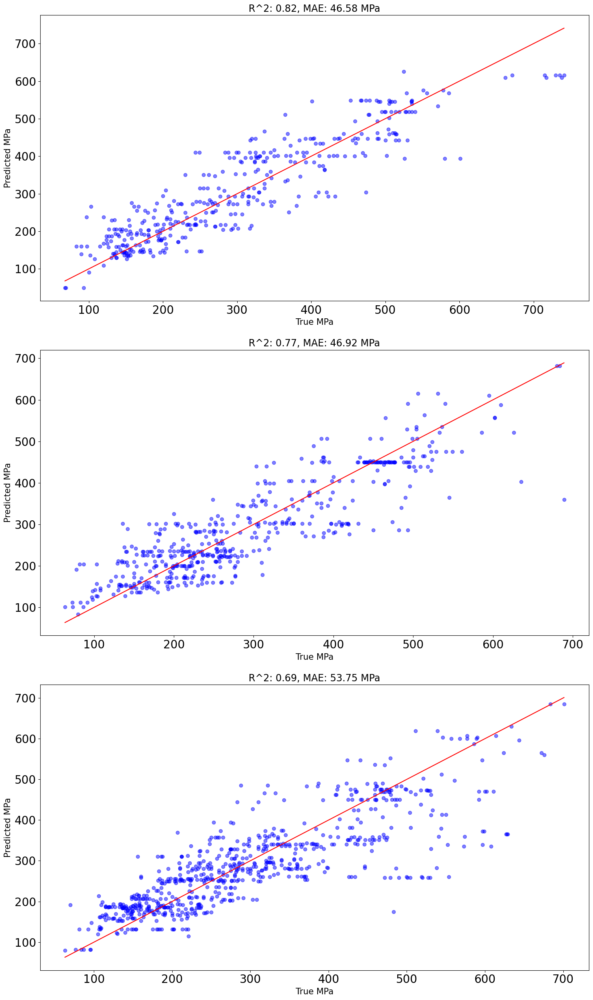

mean r2: 0.7867349454854878
mean mae: 46.13748398351578


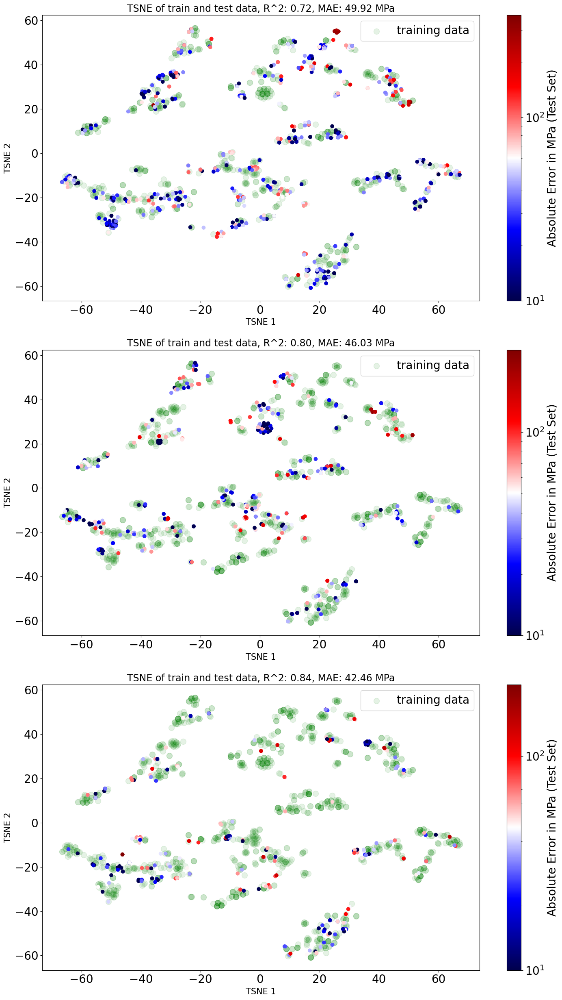

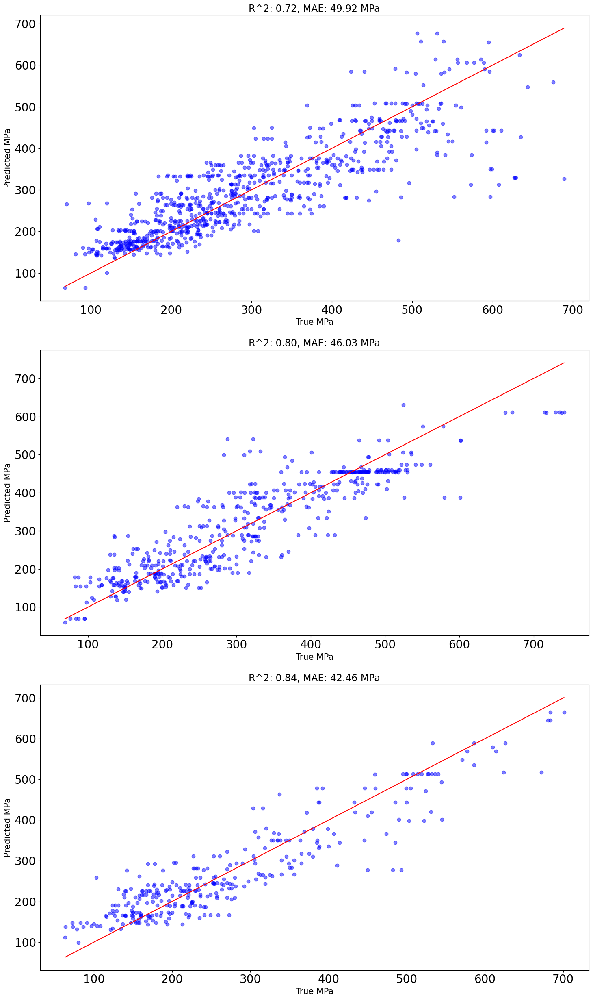

mean r2: 0.7793340806252577
mean mae: 48.40965688528164


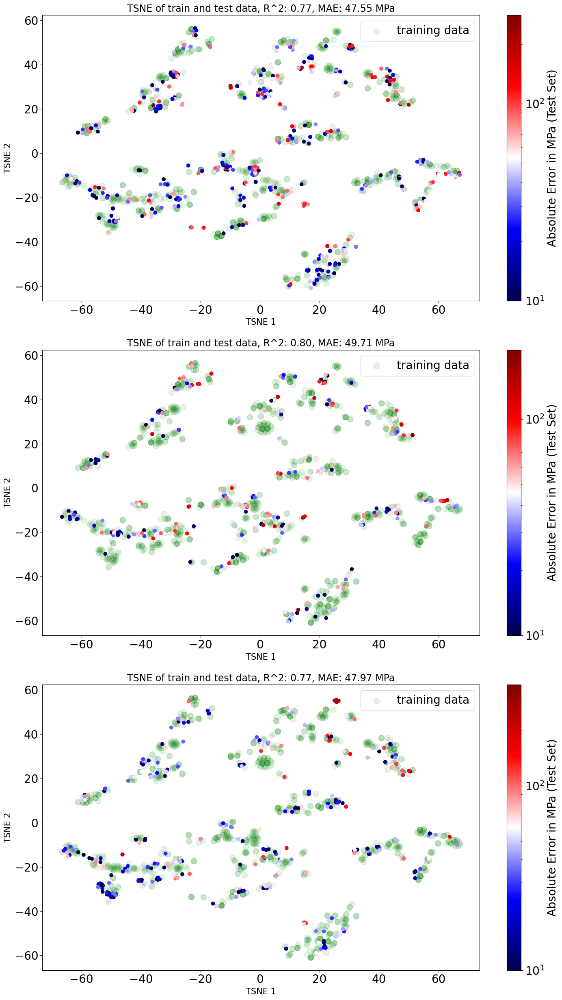

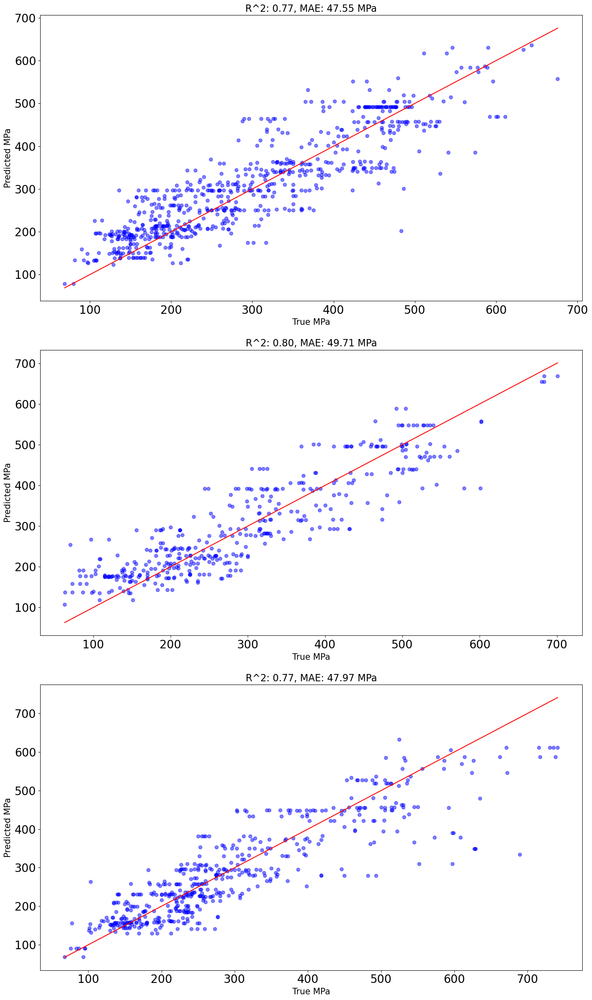

mean r2: 0.7954140286036244
mean mae: 46.00322228815697


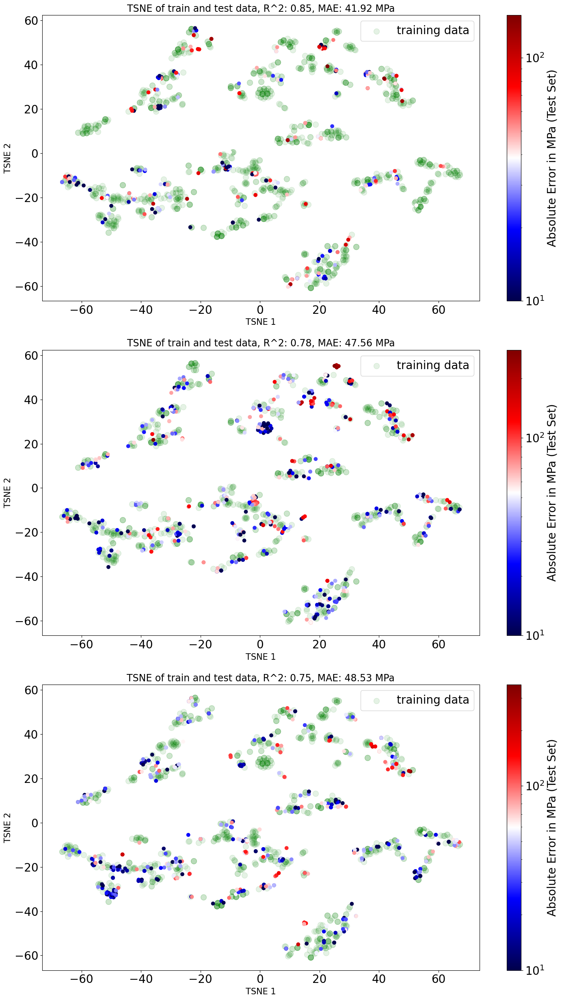

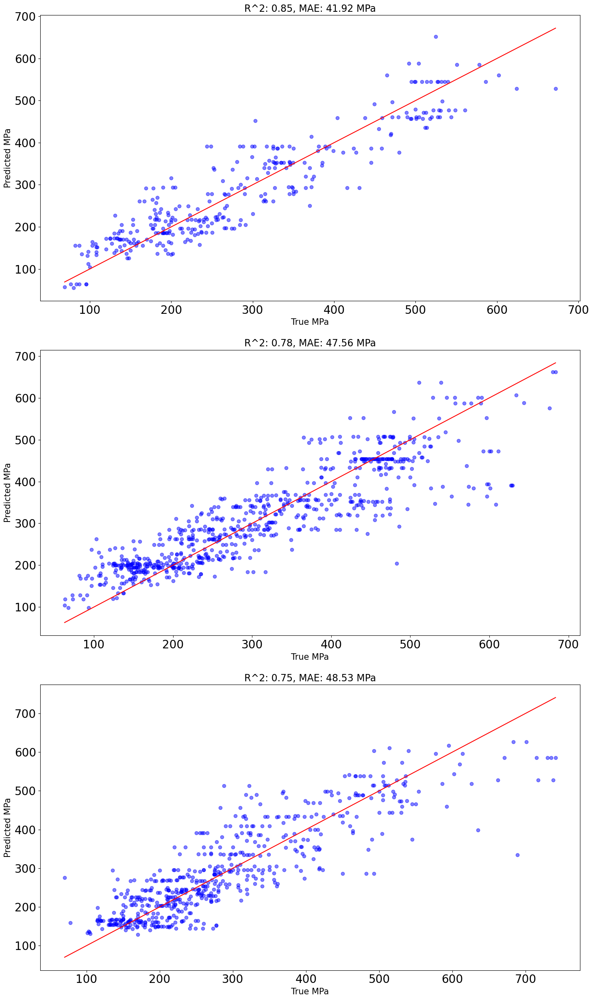

mean r2: 0.7597960931526755
mean mae: 48.51471359896829


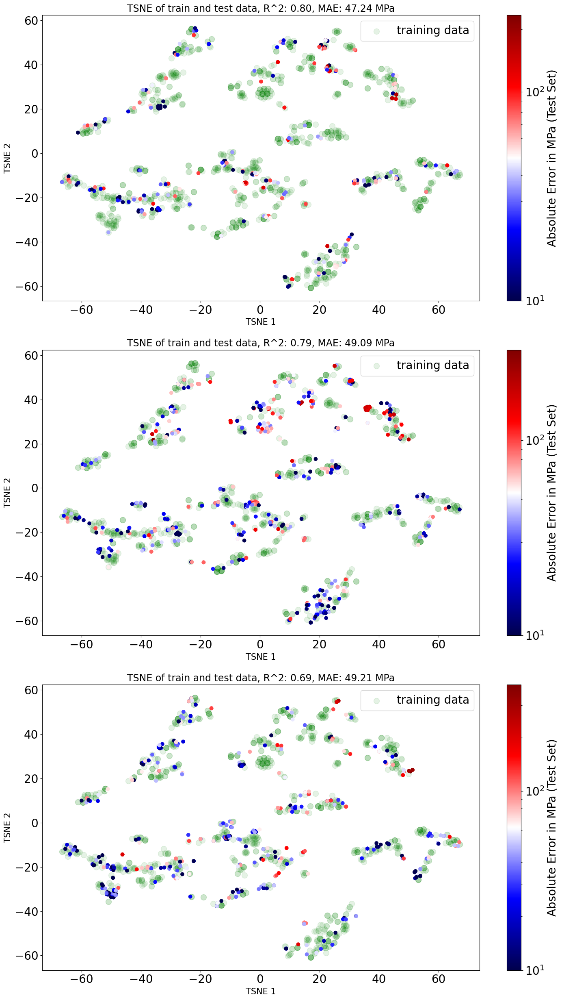

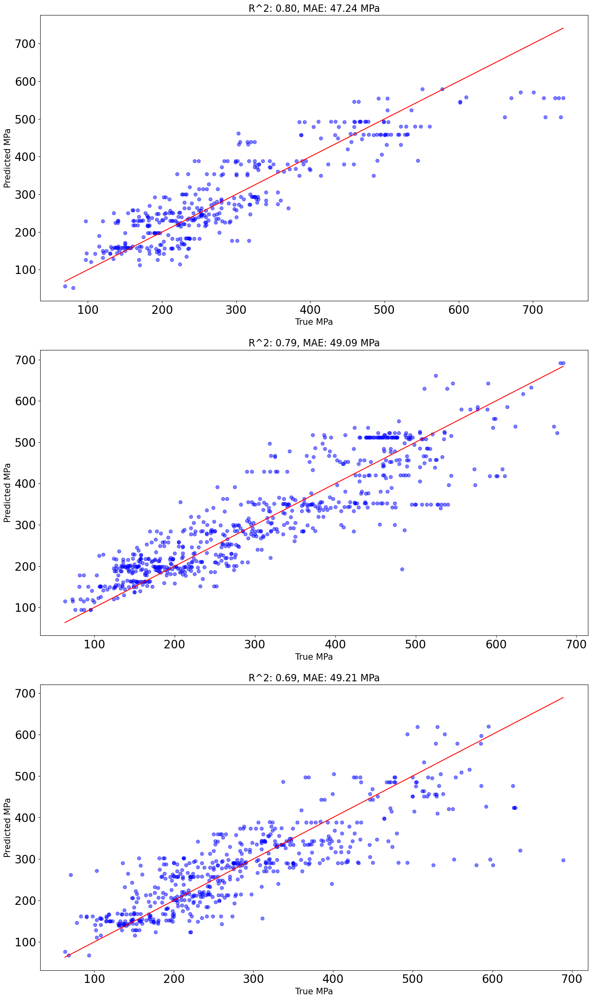

mean r2: 0.7658509584741785
mean mae: 48.76122389890505


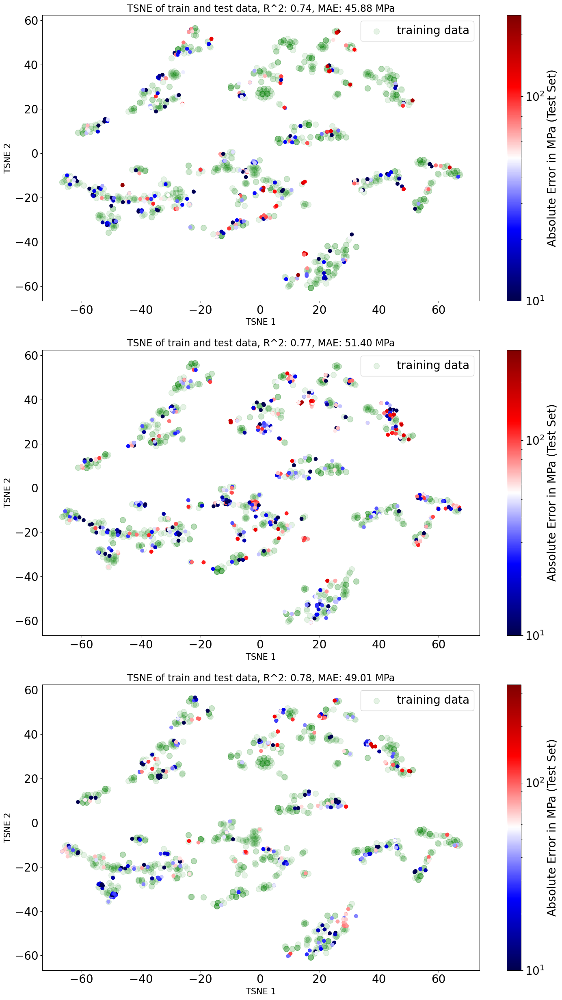

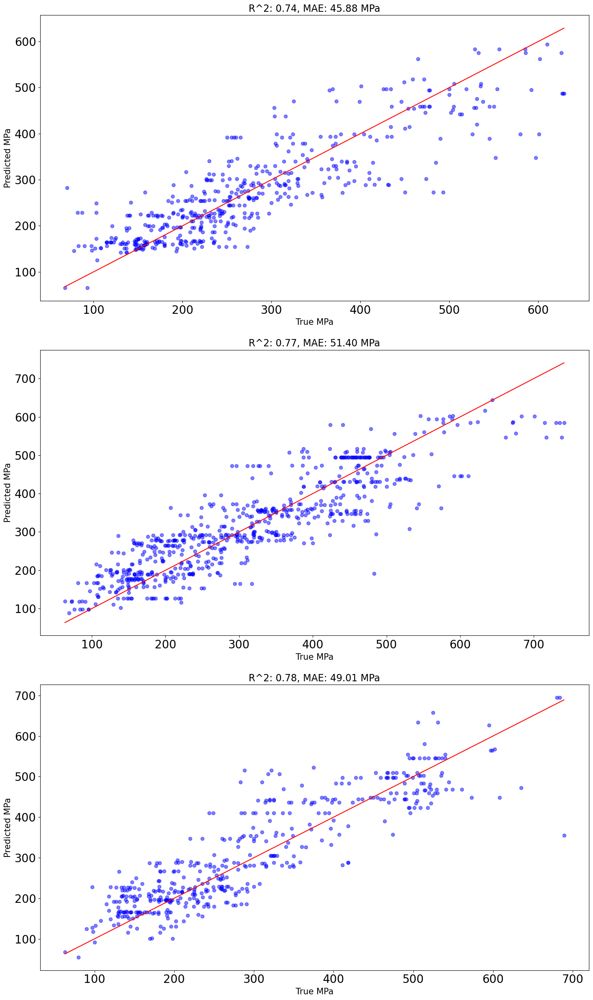

mean r2: 0.7737740907941094
mean mae: 47.93212321162169


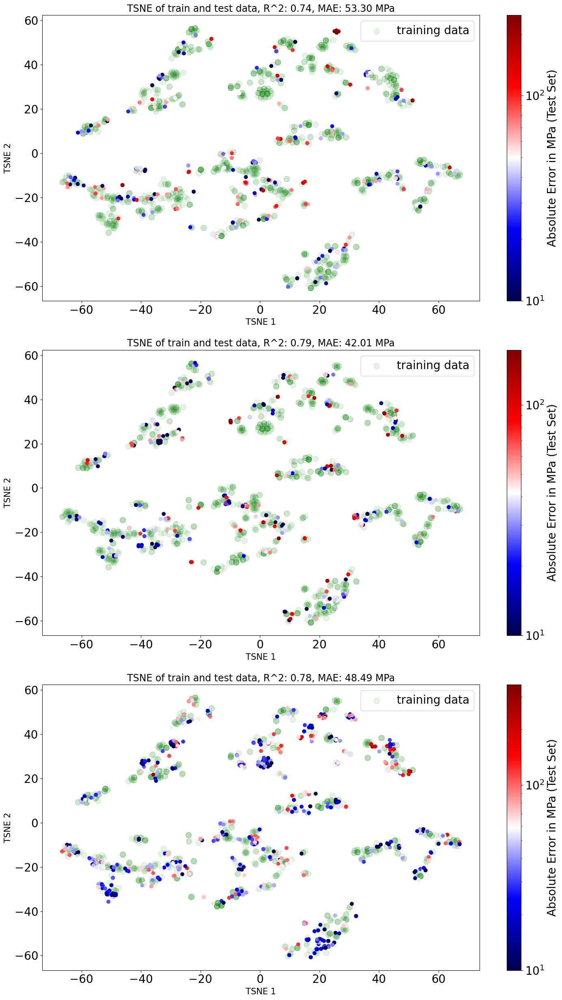

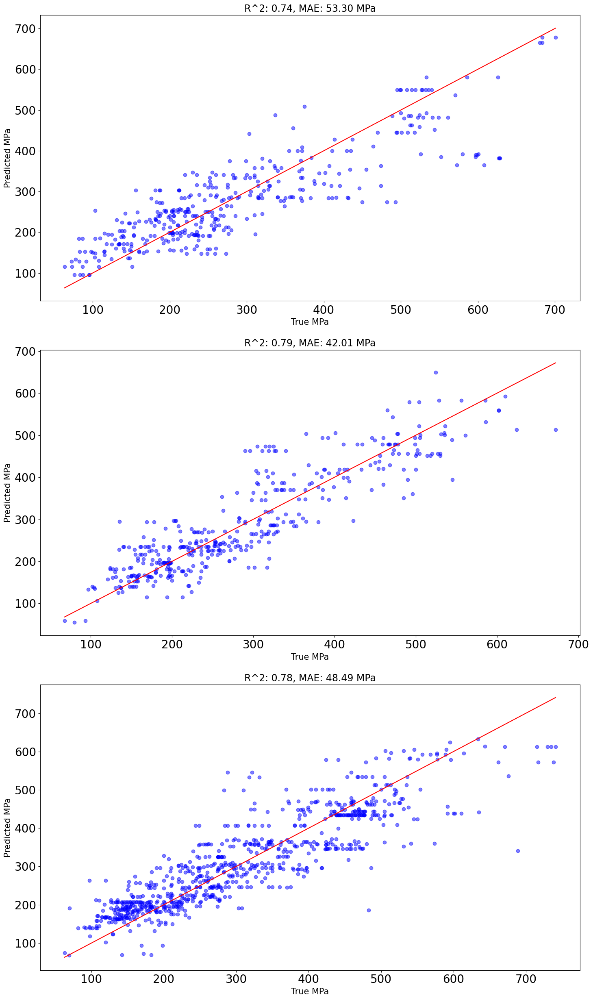

mean r2: 0.7959805864144132
mean mae: 46.08113260938941


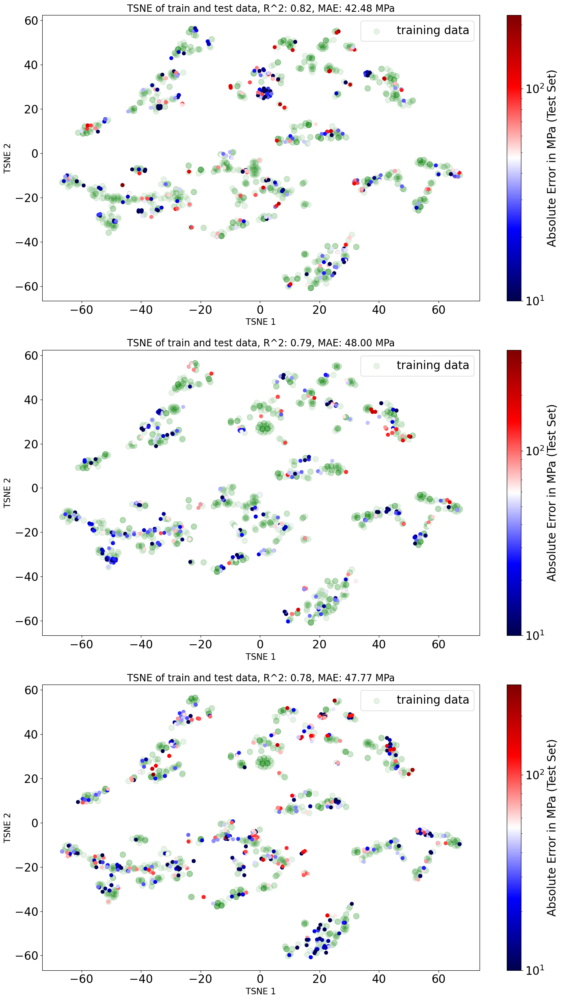

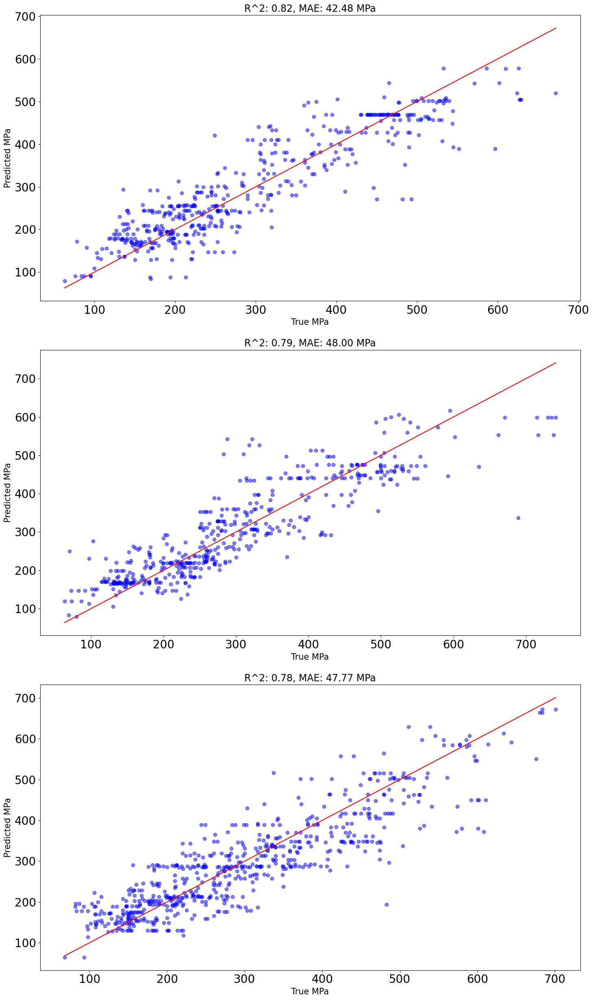

mean r2: 0.7997763177404961
mean mae: 45.21925056333966


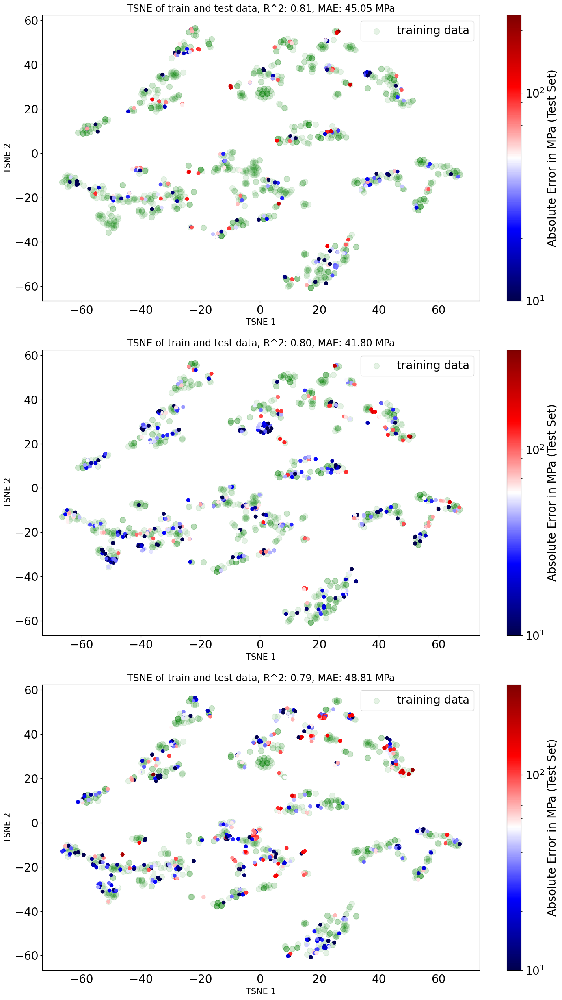

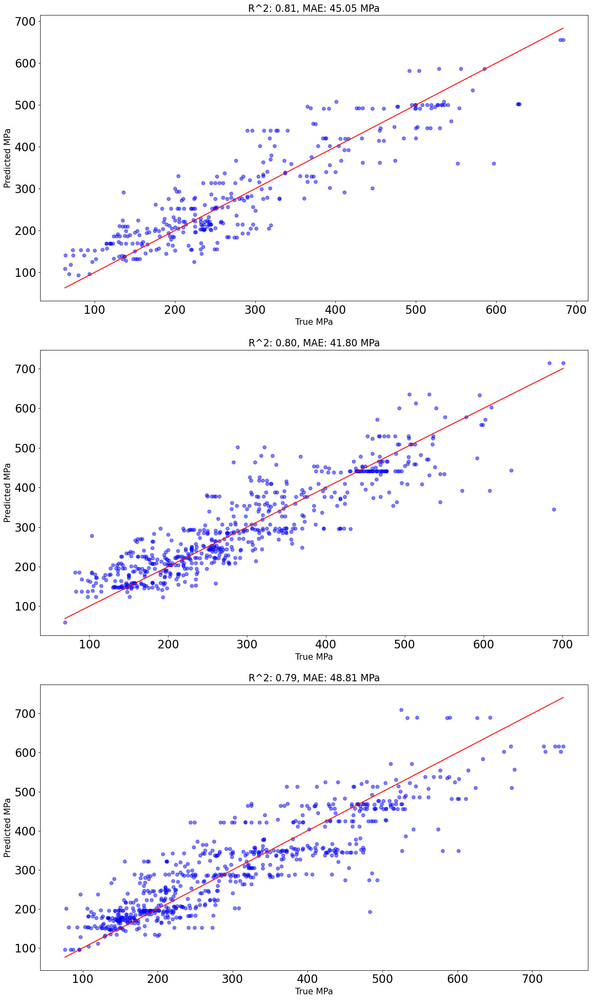

mean r2: 0.7923994564453096
mean mae: 46.25092992837936


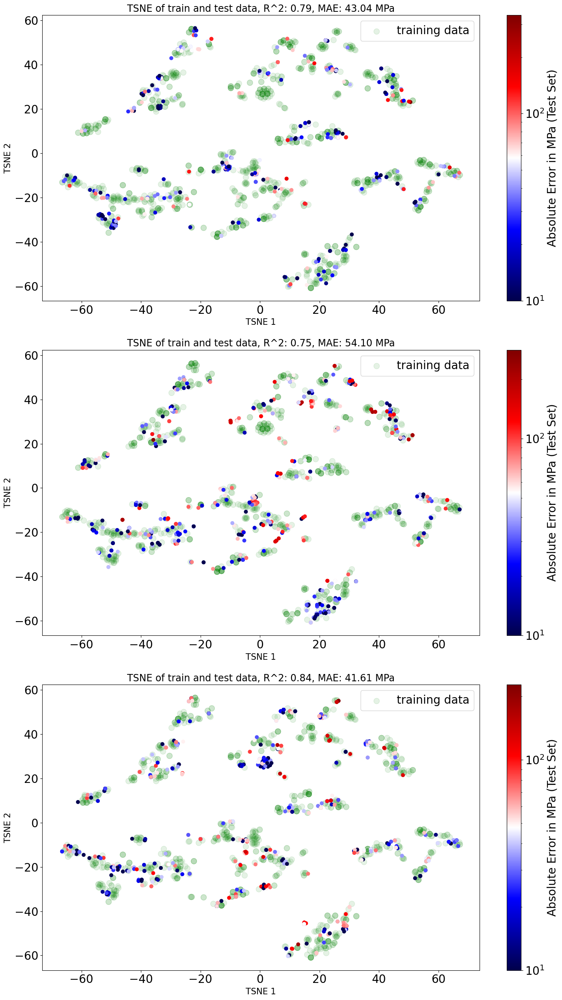

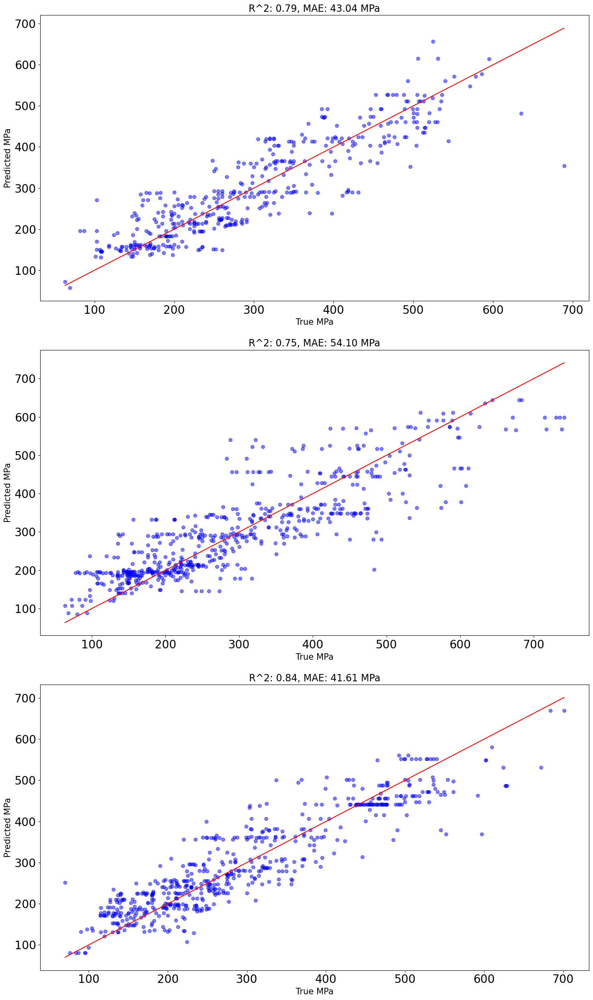

mean r2: 0.7849739608110607
mean mae: 47.14143158835072


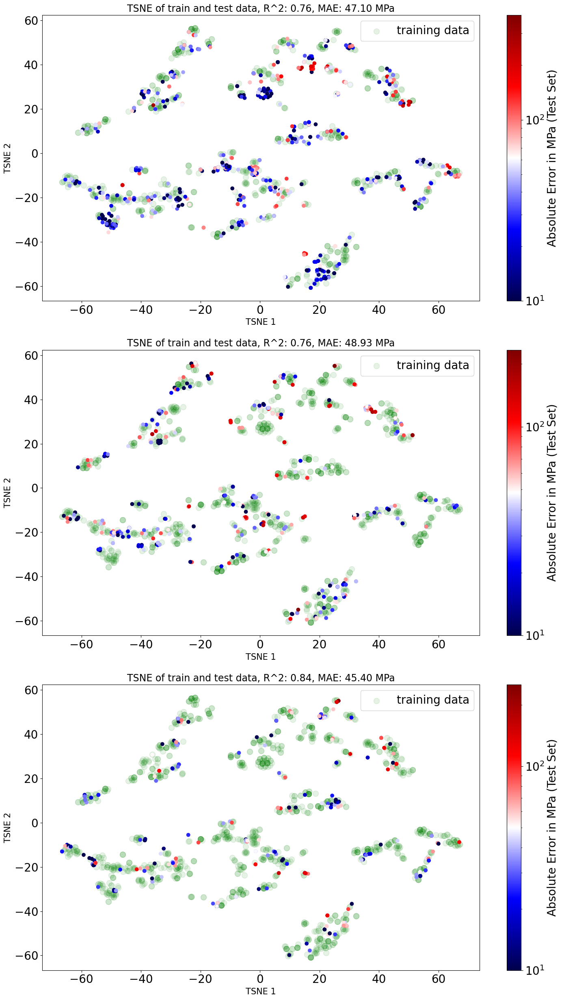

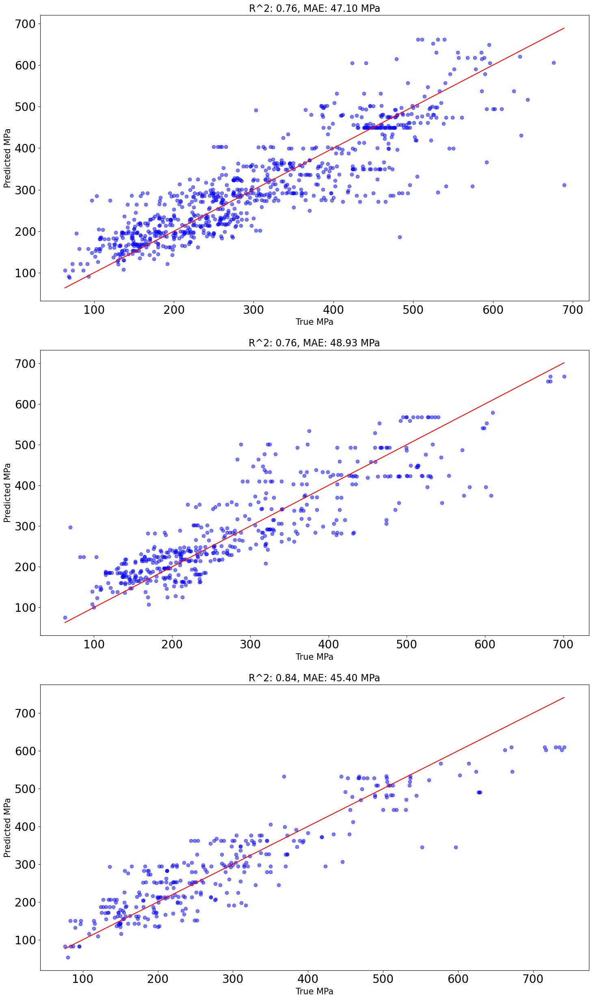

mean r2: 0.7785013951869856
mean mae: 48.6183782122611


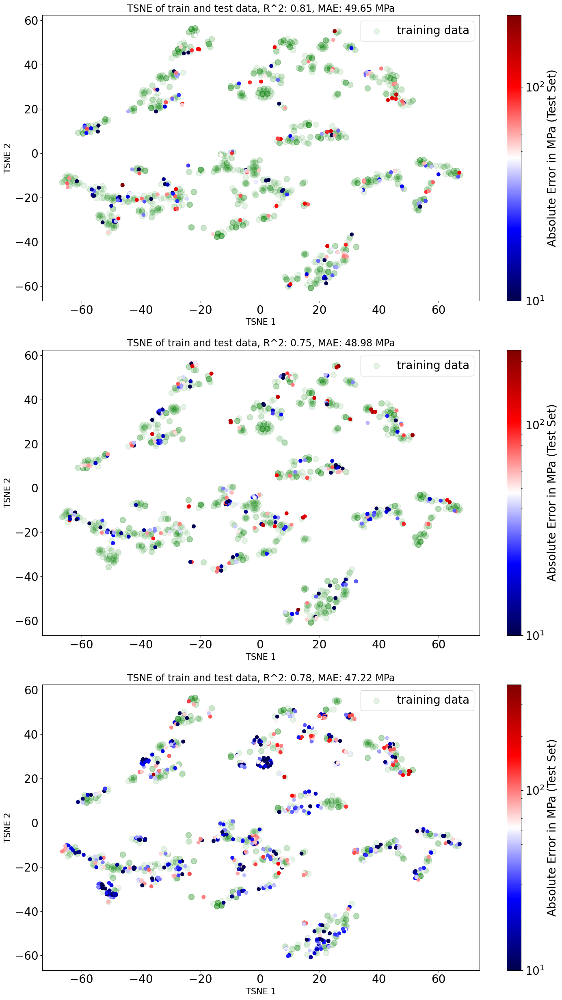

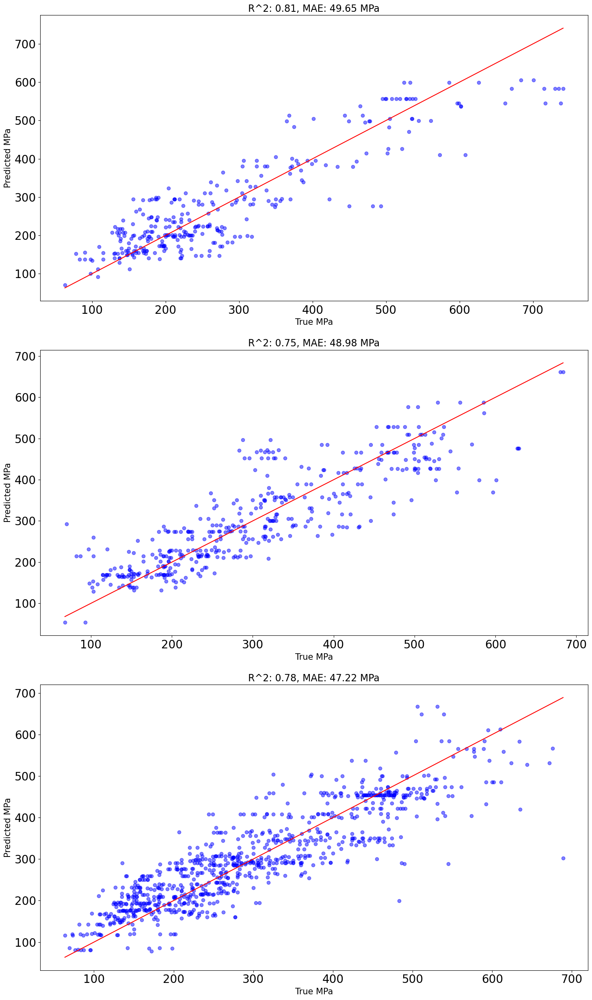

mean r2: 0.7690264371559438
mean mae: 47.865683889187096


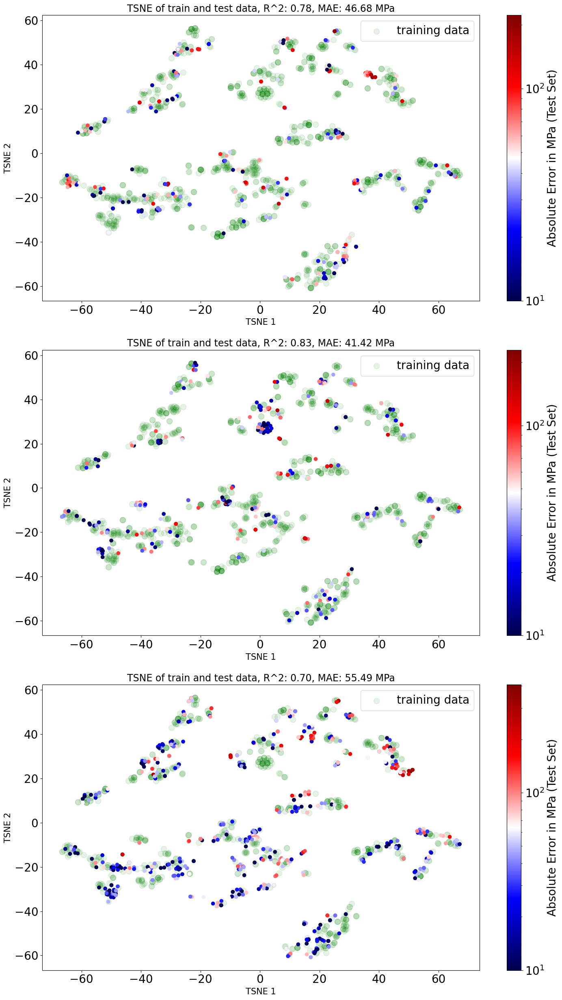

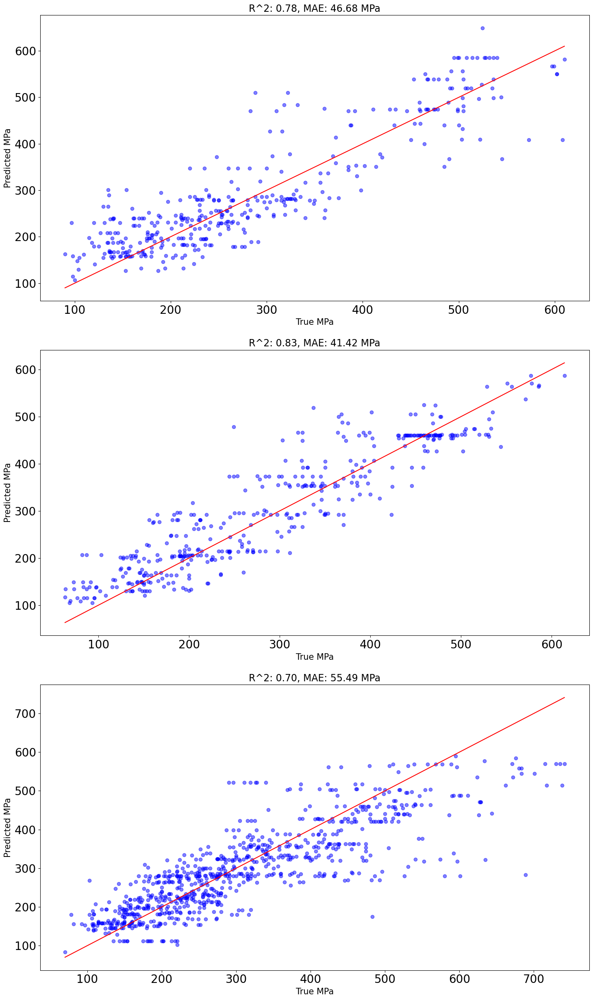

mean r2: 0.79058323325473
mean mae: 45.524540255396964


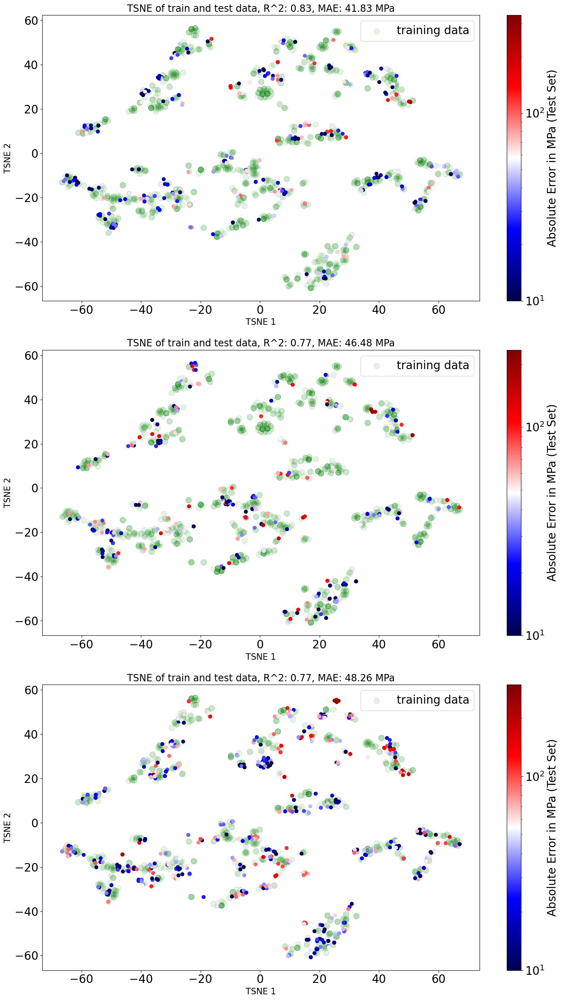

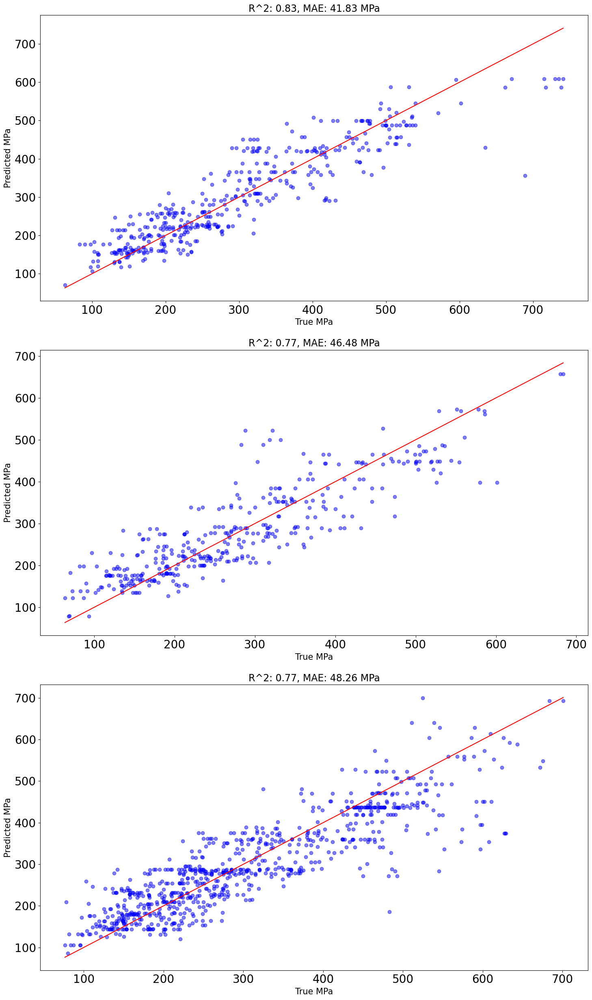

mean MAE: 47.48346396831262
std MAE: 3.4881261167683086
mean R2: 0.7769696458901556
std R2: 0.03895618902644879


In [27]:
files = df_feat_target_file["file"].loc[setup[2].index].values
chem_val_cols = relevant_cols["chem_val_cols"]
chem_val = df_feat[chem_val_cols]
model_name = setup[0]
feat = setup[1][chem_val_cols]
y = setup[2]
hyperparams = [el for el in best_individual[setup[1].shape[1]:]]
p = {el["name"]: el["current"] for el in hyperparams}
assert (y.index == feat.index).all(), "index of features and target should match!"
maes = []
r2s = []
for seed in range(N_TRIES_CV):
    r,m = evaluation.cv_with_file_and_element_grouping(feat, y, p, model_name, chem_val, files, chem_val_cols, scaling_method, enable_plots=ENABLE_PLOTS, seed=seed, img_dir=SAVE_PATH_IMG, n_folds=3)
    maes.extend(m)
    r2s.extend(r)

maes_chem = maes
r2s_chem = r2s

print("mean MAE:", np.mean(maes_chem))
print("std MAE:", np.std(maes_chem))

print("mean R2:", np.mean(r2s_chem))
print("std R2:", np.std(r2s_chem))

In [28]:
print(f"N={N_TRIES_CV} tries")
print(f"\nWith original features:")
print("mean R2:", np.mean(r2s_all_feat))
print("std R2:", np.std(r2s_all_feat))
print("mean MAE:", np.mean(maes_all_feat))
print("std MAE:", np.std(maes_all_feat))

print(f"\nWithout phase features:")
print("mean R2:", np.mean(r2s_no_phase))
print("std R2:", np.std(r2s_no_phase))
print("mean MAE:", np.mean(maes_no_phase))
print("std MAE:", np.std(maes_no_phase))

print(f"\nOnly chemical compositions:")
print("mean R2:", np.mean(r2s_chem))
print("std R2:", np.std(r2s_chem))
print("mean MAE:", np.mean(maes_chem))
print("std MAE:", np.std(maes_chem))

N=20 tries

With original features:
mean R2: 0.7903590435893432
std R2: 0.03516311386685532
mean MAE: 46.65799094241438
std MAE: 2.837187663388188

Without phase features:
mean R2: 0.788556973636542
std R2: 0.035199271559002425
mean MAE: 47.086082674238455
std MAE: 2.802067401034391

Only chemical compositions:
mean R2: 0.7769696458901556
std R2: 0.03895618902644879
mean MAE: 47.48346396831262
std MAE: 3.4881261167683086


## Create latex tables

In [29]:
def create_latex_table_from_df(df, n_decimals=2, caption=None, label=None):

    df = df.rename(columns={"N non-zero": r"$N_{\textnormal{non-zero}}$"})
    df = df.round(n_decimals)
    for col in df.columns:
        df[col] = df[col].apply(lambda x: f"{x:.{n_decimals}f}")

    cols_no_dec = [r"$N_{\textnormal{non-zero}}$"]
    for col in cols_no_dec:
        df[col] = df[col].apply(lambda x: f"{int(float(x))}")

    df = df.astype(str)

    latex = df.to_latex(index=True, escape=False)
    latex = latex.replace("\\toprule", "\\hline")
    latex = latex.replace("\\midrule", "\\hline")
    latex = latex.replace("\\bottomrule", "\\hline")

    latex = latex.replace("\\begin{tabular}", "\\begin{table}[h!]\n\\small\n\\begin{tabular}")
    latex = latex.replace("\\end{tabular}", "\\end{tabular}\n\\end{table}")

    latex = latex.replace("__", " ")
    latex = latex.replace("_", " ")

    if caption is not None:
        latex = latex.replace("\\end{tabular}", f"\\end{{tabular}}\n\\caption{{{caption}}}")

    if label is not None:
        latex = latex.replace("\\end{tabular}", f"\\end{{tabular}}\n\\label{{{label}}}")

    return latex

chem_comps = setup[1][relevant_cols["chem_val_cols"]].copy()
chem_comps[chem_comps<0] = 0 # nan values were replaced with -1 -> revert this for the following description
desc = chem_comps.describe().T.drop(columns=["count", "25%", "75%"]).rename(columns={"50%": "Median", "min": "Min", "max": "Max", "mean": "Mean", "std": "Std"})
desc["N non-zero"] = (chem_comps > 0).sum()

desc = desc.round(2)
with open(os.path.join(SAVE_PATH_DATA, "chem_comps_desc.tex"), "w") as f:
    f.write(create_latex_table_from_df(desc, 2, caption="Overview of chemical compositions in the final dataset (wt. \\%)", label="tab:chemical_compositions"))

meta_feat = setup[1][setup[1].columns[12:41]]

oh_cols = meta_feat.columns[meta_feat.columns.str.contains("OH")]
non_oh_cols = meta_feat.columns[~meta_feat.columns.str.contains("OH")]

oh_feat = meta_feat[oh_cols]
oh_feat[oh_feat<0] = np.nan

desc = oh_feat[oh_cols].describe()
desc = desc.T.drop(columns=["count", "25%", "50%", "75%", "std"]).rename(columns={"mean": "Mean", "max": "Max", "min": "Min", "median": "Median"})
desc["N non-zero"] = (oh_feat > 0).sum()
desc = desc[["N non-zero"]]
with open(os.path.join(SAVE_PATH_DATA, "oh_feat_desc.tex"), "w") as f:
    f.write(create_latex_table_from_df(desc, 0, caption="Overview of One-Hot encoded features in the final dataset", label="tab:oh_feat"))

non_oh_feat = meta_feat[non_oh_cols]
non_oh_feat[non_oh_feat<0] = np.nan
desc = non_oh_feat.describe().T.drop(columns=["count", "25%", "50%", "75%", "std"]).rename(columns={"50%": "median", "min": "Min", "max": "Max", "mean": "Mean", "median": "Median"})
desc["N non-zero"] = (non_oh_feat > 0).sum()

desc = desc.round(2)
with open(os.path.join(SAVE_PATH_DATA, "non_oh_feat_desc.tex"), "w") as f:
    f.write(create_latex_table_from_df(desc, 2, caption="Overview of numeric heat treatment features in the final dataset", label="tab:heat_treatment_numeric"))

## Plot feature importances

In [30]:
# plot importances using shapley values (whole dataset)
import shap
from sklearn.preprocessing import RobustScaler

recalc_shap_values = False
np.random.seed(2)
feat = setup[1]

#shap_feat = setup[1][best_features]
#shap_feat = setup[1][list(set(selected_cols) | set(relevant_cols["chem_val_cols"]))]
shap_feat = setup[1][selected_cols]

p = {k: int(el) if MODEL_PARAMS[model_name][k].get("dt", None) is int else el for k, el in selected_params.items()}

x = shap_feat
y = setup[2]

if scaling_method == "minmax":
    min_ = x.min(0)
    max_ = x.max(0)
    x = (x - min_) / (max_ - min_ + 1e-7)
elif scaling_method == "standard":
    mean = x.mean(0)
    std = x.std(0)
    x = (x - mean) / (std + 1e-7)
elif scaling_method == "robust":
    scaler = RobustScaler()
    x = scaler.fit_transform(x)


assert "p" in locals(), "p should be defined"
model = MODELS[model_name](**p)
model.fit(x, y)


columns=x.columns

shap_values = None
if model_name == "lgbm":
    print("using lightgbm's plot_importance")
    from lightgbm import plot_importance
    plot_importance(model, importance_type="gain", figsize=(15, 10))
    plt.show()
else:
    print("using shap values")
    explainer = shap.Explainer(lambda x: model.predict(x), x)
    if not os.path.isfile(os.path.join(SAVE_PATH_DATA, f"shap_values_{model_name}.pkl")) or recalc_shap_values:
        shap_values = explainer(x)
        with open(os.path.join(SAVE_PATH_DATA, f"shap_values_{model_name}.pkl"), "wb") as f:
            pickle.dump(shap_values, f)
    else:
        with open(os.path.join(SAVE_PATH_DATA, f"shap_values_{model_name}.pkl"), "rb") as f:
            shap_values = pickle.load(f)

    shap.summary_plot(shap_values, x, plot_type="bar", feature_names=columns, show=False, max_display=x.shape[1])
    current_xlabel = plt.gca().get_xlabel()
    plt.gca().set_xlabel(current_xlabel, fontsize=10.5)

    def format_ylabels():
        ylabels = plt.gca().get_yticklabels()
        ylabels = [el.get_text()
                   .replace("__solidus_val", "")
                   .replace("equ__", "")
                   .replace("Mg2Si_b", r"$\beta$-Mg$_2$Si")
                   .replace("THETA_Al2Cu", r"$\theta$-Al$_2$Cu") for el in ylabels
                   ]
        plt.gca().set_yticklabels(ylabels)

    def increase_ticklabel_sizes():
        fsize = 23
        xlabels = plt.gca().get_xticklabels()
        ylabels = plt.gca().get_yticklabels()
        for label in xlabels:
            label.set_fontsize(fsize)
        for label in ylabels:
            label.set_fontsize(fsize)

        # also increase size of axis labels
        plt.gca().set_xlabel(plt.gca().get_xlabel(), fontsize=fsize)
        plt.gca().set_ylabel(plt.gca().get_ylabel(), fontsize=fsize)

    #save_path = "./publication/feb14/images/"
    save_path = SAVE_PATH_IMG

    plt.gcf().set_size_inches(15, 8)
    format_ylabels()
    plt.gca().set_xlabel(plt.gca().get_xlabel().replace("average impact on model output magnitude", "average abs. impact on output - YS"), fontsize=20)
    increase_ticklabel_sizes()
    plt.tight_layout()
    # add (YS) to xlabel
    plt.savefig(os.path.join(save_path, f"shap_summary_plot_{model_name}.pdf"))
    plt.close()

    shap_values.feature_names = list(columns)
    #shap.plots.waterfall(shap_values[0], show=False, max_display=x.shape[1])
    # create a 4x4 grid of waterfall plots of random samples

    #random_samples = np.random.choice(x.shape[0], 16)
    random_samples = [ 230, 1023,  559, 1301,   29, 1376, 1448,  881,   85,  453,  141, 837,  601,  121, 1273,  528]
    for i, idx in enumerate(random_samples):
        plt.subplot(4, 4, i+1)
        ax = shap.plots.waterfall(shap_values[idx], show=False, max_display=x.shape[1])
        ax.set_title(f"Sample {idx}")
        ax.set_xlabel(ax.get_xlabel().replace("average impact on model output magnitude", "average abs. impact on output").replace(")", "") + " - YS)", fontsize=20)


    format_ylabels()
    plt.tight_layout()
    #plt.gcf().set_size_inches(12, 6)
    increase_ticklabel_sizes()
    #plt.savefig(os.path.join(save_path, f"shap_waterfall_plot_{model_name}.png"))
    plt.gcf().set_size_inches(40, 30)
    plt.tight_layout()
    plt.savefig(os.path.join(save_path, f"shap_waterfall_plot_multiple.pdf"))
    plt.close()

    shap.plots.beeswarm(shap_values, show=False, max_display=x.shape[1])
    #plt.subplots_adjust(left=0.3)
    plt.gcf().set_size_inches(15, 8)
    format_ylabels()
    plt.gca().set_xlabel(plt.gca().get_xlabel().replace(")", "") + " - YS)", fontsize=20)
    increase_ticklabel_sizes()

    # increase text size in colorbar
    cbar = plt.gcf().get_axes()[1]
    cbar.tick_params(labelsize=23)
    cbar.set_ylabel(cbar.get_ylabel(), fontsize=23)

    plt.tight_layout()
    plt.savefig(os.path.join(save_path, f"shap_beeswarm_plot_{model_name}.pdf"))
    plt.close()

using shap values


## Metrics on Mendeley Dataset

In [31]:
skip_feature_generation_mendeley = True
if skip_feature_generation_mendeley:
    df_feat_mendeley = pd.read_csv(os.path.join(SAVE_PATH_DATA, "df_feat_mendeley_final.csv"), index_col=0)
    targets_mendeley = pd.read_csv(os.path.join(SAVE_PATH_DATA, "targets_mendeley_final.csv"), index_col=0)["Yield Strength (MPa)"]
    mendeley_chem_cols = [col for col in df_feat_mendeley.columns if len(col) <= 2]
    with open(os.path.join(SAVE_PATH_DATA, "idx_orig_mendeley.pkl"), "rb") as f:
        idx_orig = pickle.load(f)
else:
    fname = "./miscellaneous/evaluation_data/data.mendeley.com_datasets_b6br4yk6r3_1.csv"
    df_mendeley = pd.read_csv(fname, index_col=0)
    num_duplicates = df_mendeley.duplicated().sum()
    print(f"dropping {num_duplicates} duplicates")
    df_mendeley = df_mendeley.drop_duplicates()
    mendeley_chem_cols = [el for el in df_mendeley.columns if len(el) <= 2]

    #non_trained_elems = [el for el in mendeley_chem_cols if el not in relevant_cols["chem_val_cols"]]

    #drop_idx = df_mendeley[non_trained_elems].sum(1) > 0
    #print(f"dropping {drop_idx.sum()} samples with elements not trained on")
    #df_mendeley = df_mendeley[~drop_idx]
    num_ys_nan = df_mendeley["Yield Strength (MPa)"].isna().sum()
    print(f"dropping {num_ys_nan} samples with missing YS values")
    df_mendeley = df_mendeley.dropna(subset=["Yield Strength (MPa)"])

    df_mendeley[mendeley_chem_cols] *= 100
    df_mendeley.to_csv(os.path.join(SAVE_PATH_DATA, "df_mendeley.csv"))


    mendeley_matcalc_dir = "./miscellaneous/evaluation_data/data.mendeley.results_equ"
    paths = {
        "featpath": os.path.join(SAVE_PATH_DATA, "df_feat_matcalc_mendeley.csv"),
        "featpath_solidus": os.path.join(SAVE_PATH_DATA, "df_feat_matcalc_solidus_mendeley.csv"),
        "respath_scheil": None,
        "respath_equ": mendeley_matcalc_dir,
    }

    df_feat_mendeley = df_mendeley[mendeley_chem_cols]
    targets_mendeley = df_mendeley["Yield Strength (MPa)"]

    idx_orig = df_feat_mendeley.index

    only_solidus=True
    df_feat_mendeley, targets_mendeley = phase_features.get_phase_features(
        True,
        only_solidus,
        targets_mendeley.reset_index(drop=True),
        df_feat=df_feat_mendeley.reset_index(drop=True),
        df_all=df_mendeley.reset_index(drop=True),
        relevant_cols={"chem_val_cols": mendeley_chem_cols},
        paths=paths
    )
    idx_orig = idx_orig[df_feat_mendeley.index]

    with open(os.path.join(SAVE_PATH_DATA, "idx_orig_mendeley.pkl"), "wb") as f:
        pickle.dump(idx_orig, f)

    df_feat_mendeley.reset_index(drop=True, inplace=True)
    targets_mendeley.reset_index(drop=True, inplace=True)

    df_feat_mendeley = df_feat_mendeley
    df_feat_mendeley = aggregate_phases(df_feat_mendeley)
    df_feat_mendeley = calculate_element_features(df_feat_mendeley, relevant_cols["chem_val_cols"])

    df_feat_mendeley.to_csv(os.path.join(SAVE_PATH_DATA, "df_feat_mendeley_final.csv"))
    targets_mendeley.to_csv(os.path.join(SAVE_PATH_DATA, "targets_mendeley_final.csv"))

df_feat_mendeley = df_feat_mendeley.rename(columns=rename_dict)

In [32]:
print(df_feat_mendeley[selected_cols].describe())
print(df_feat[selected_cols].describe())

               Mg          Mn          Si          Ti      D5_std      D6_std  \
count  392.000000  392.000000  392.000000  392.000000  392.000000  392.000000   
mean     1.580028    0.246328    0.548835    0.015041    0.016809   21.290981   
std      1.506328    0.355632    2.521993    0.038350    0.007332   11.958226   
min      0.000000    0.000000    0.000000    0.000000    0.000938    0.822293   
25%      0.500000    0.000000    0.000000    0.000000    0.011388   11.317291   
50%      1.000000    0.040010    0.000000    0.000000    0.016650   20.558480   
75%      2.500000    0.500000    0.121258    0.000000    0.019608   29.825788   
max      6.000000    1.310000   18.000000    0.200000    0.045350   58.020788   

           E8_mad  Fe/Cu sub-group  Si/Al sub-group       AL3ZR  \
count  392.000000       392.000000       392.000000  392.000000   
mean     2.904112         0.000518         0.000228    0.000038   
std      3.857308         0.004122         0.001139    0.000257   
mi

how many chemical compositions in the mendeley set are already in df_feat?

In [33]:
mend_chem_strings = df_feat_mendeley[relevant_cols["chem_val_cols"]].fillna(0).round(1).astype(str).apply(lambda x: "_".join(x), axis=1) + "_" + targets_mendeley.round(-1).astype(str).values
df_chem_strings = df_feat[relevant_cols["chem_val_cols"]].fillna(0).round(1).astype(str).apply(lambda x: "_".join(x), axis=1) + "_" + setup[2].round(-1).astype(str).values

already_in_df_feat = mend_chem_strings.isin(df_chem_strings)
print(f"there are {already_in_df_feat.sum()} samples which have ROUGHLY the same chemical composition and YS value in the df_feat dataset -> chemical composition values are rounded to 1 decimal place and YS values are rounded to the nearest 10")

there are 7 samples which have ROUGHLY the same chemical composition and YS value in the df_feat dataset -> chemical composition values are rounded to 1 decimal place and YS values are rounded to the nearest 10


MAE on Mendeley dataset: 76.7793694724926
R2 on Mendeley dataset: 0.5137766849755783


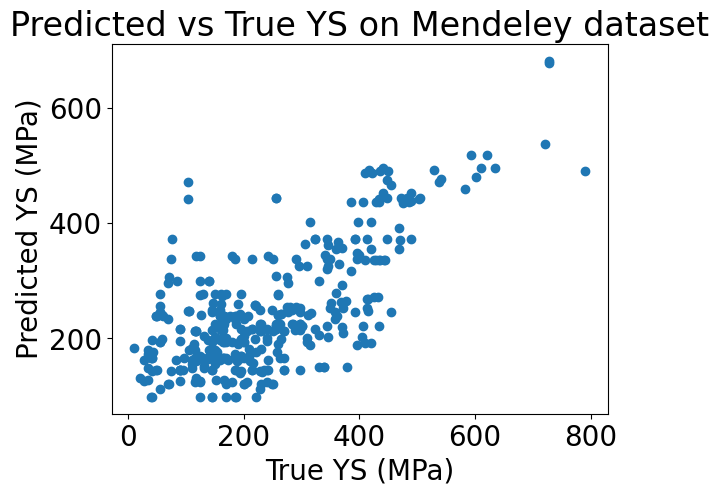

In [34]:
from sklearn.metrics import mean_absolute_error, r2_score

val_cols = selected_cols
#val_cols = mendeley_chem_cols

# fit on all of df_feat, then test on mendeley dataset
df_feat_scaled = setup[1][val_cols].fillna(0)
min_ = df_feat_scaled.min(0).values
max_ = df_feat_scaled.max(0).values
df_feat_scaled = (df_feat_scaled - min_) / (max_ - min_ + 1e-7)

model = MODELS[model_name](**p)
model.fit(df_feat_scaled, setup[2])


X = df_feat_mendeley[val_cols].values
y = targets_mendeley.values
X_scaled = (X - min_) / (max_ - min_ + 1e-7)

y_pred = model.predict(X_scaled)
mae = mean_absolute_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("MAE on Mendeley dataset:", mae)
print("R2 on Mendeley dataset:", r2)

plt.scatter(y, y_pred)
plt.xlabel("True YS (MPa)")
plt.ylabel("Predicted YS (MPa)")
plt.title("Predicted vs True YS on Mendeley dataset")
plt.show()

In [35]:
# try to fit model on mendeley dataset directly using 4-fold cv
from sklearn.model_selection import cross_val_score

# fit on all of df_feat, then test on mendeley dataset
df_feat_scaled = setup[1][val_cols].fillna(0)
min_ = df_feat_scaled.min(0).values
max_ = df_feat_scaled.max(0).values
df_feat_scaled = (df_feat_scaled - min_) / (max_ - min_ + 1e-7)

model = MODELS[model_name](**p)
model.fit(df_feat_scaled, setup[2])


X = df_feat_mendeley[val_cols].values
y = targets_mendeley.values
X_scaled = (X - min_) / (max_ - min_ + 1e-7)


# shuffle data
np.random.seed(42)
idx = np.arange(len(df_feat_mendeley))
np.random.shuffle(idx)
X = X_scaled[idx]
y = y[idx]

model = MODELS[model_name](**p)
mae_scores = cross_val_score(model, X, y, cv=4, scoring=lambda model, X, y: mean_absolute_error(y, model.predict(X)))
r2_scores = cross_val_score(model, X, y, cv=4, scoring="r2")

print("\n\nMetrics when fitting model on Mendeley dataset directly:")
print("mean MAE on Mendeley dataset (4-fold cv):", mae_scores.mean())
print("mean R2 on Mendeley dataset (4-fold cv):", r2_scores.mean())



Metrics when fitting model on Mendeley dataset directly:
mean MAE on Mendeley dataset (4-fold cv): 62.79944444978239
mean R2 on Mendeley dataset (4-fold cv): 0.633888809046812


In [36]:
from sklearn.preprocessing import OneHotEncoder


fname = "./miscellaneous/evaluation_data/data.mendeley.com_datasets_b6br4yk6r3_1.csv"
df_mendeley_all_cols = pd.read_csv(fname, index_col=0)
df_mendeley_all_cols = df_mendeley_all_cols.drop(columns=['Elongation (%)', 'Tensile Strength (MPa)'])
df_mendeley_all_cols = df_mendeley_all_cols.loc[idx_orig]
df_mendeley_all_cols.to_csv(os.path.join(SAVE_PATH_DATA, "validation_set_mendeley_supported_elements.csv"))



mendeley_chem_cols = [col for col in df_mendeley_all_cols.columns if len(col) <= 2]
feat_cols = [c for c in df_mendeley_all_cols.columns if c not in ['Elongation (%)', 'Tensile Strength (MPa)', 'Yield Strength (MPa)']]

enc = OneHotEncoder()
processing_OH = enc.fit_transform(df_mendeley_all_cols[["Processing"]].values).toarray()
feat_names_OH = enc.get_feature_names_out(["Processing"])
processing_class = enc.fit_transform(df_mendeley_all_cols[["class"]].values).toarray()
feat_names_class = enc.get_feature_names_out(["class"])

df_mendeley_all_cols = df_mendeley_all_cols[[c for c in feat_cols if c not in ["Processing", "class"]]]
df_mendeley_all_cols = pd.concat([df_mendeley_all_cols, pd.DataFrame(processing_OH, columns=feat_names_OH, index=df_mendeley_all_cols.index)], axis=1)
df_mendeley_all_cols = pd.concat([df_mendeley_all_cols, pd.DataFrame(processing_class, columns=feat_names_class, index=df_mendeley_all_cols.index)], axis=1)

oh_cols_mendeley = [col for col in df_mendeley_all_cols.columns if "Processing" in col or "class" in col]
vals_oh = df_mendeley_all_cols[oh_cols_mendeley].values


from sklearn.model_selection import cross_val_score

X = df_feat_mendeley[val_cols].values
X = np.concatenate([X, vals_oh], axis=1)
min_ = X.min(0)
max_ = X.max(0)
y = targets_mendeley.values

# shuffle data
np.random.seed(42)
idx = np.arange(len(df_feat_mendeley))
np.random.shuffle(idx)
X = X[idx]
y = y[idx]

model = MODELS[model_name](**p)

# let's downproject to 11-dimensional data using pca (same dimensionality as the selected feature vector), since SVR doesn't handle very high dimensional data with sparse features (OH-encodings) well
from sklearn.decomposition import PCA
X_pca = PCA(n_components=11).fit_transform(X)
X_scaled = (X_pca - X_pca.min(0)) / (X_pca.max(0) - X_pca.min(0) + 1e-7)

mae_scores = cross_val_score(model, X_scaled, y, cv=4, scoring=lambda model, X, y: mean_absolute_error(y, model.predict(X)))
r2_scores = cross_val_score(model, X_scaled, y, cv=4, scoring="r2")

print("\n\nMetrics when fitting lgbm regressor on Mendeley dataset directly, with processing and class:")
print("mean MAE on Mendeley dataset (4-fold cv):", mae_scores.mean())
print("mean R2 on Mendeley dataset (4-fold cv):", r2_scores.mean())



Metrics when fitting lgbm regressor on Mendeley dataset directly, with processing and class:
mean MAE on Mendeley dataset (4-fold cv): 42.807251610214436
mean R2 on Mendeley dataset (4-fold cv): 0.8101776852437017


In [37]:
X = df_feat_mendeley[val_cols].values
min_ = X.min(0)
max_ = X.max(0)
y = targets_mendeley.values
X_scaled = (X - min_) / (max_ - min_ + 1e-7)

# shuffle data
np.random.seed(42)
idx = np.arange(len(df_feat_mendeley))
np.random.shuffle(idx)
X = X_scaled[idx]
y = y[idx]

from lightgbm import LGBMRegressor
model = LGBMRegressor(verbose=-1)

mae_scores = cross_val_score(model, X, y, cv=4, scoring=lambda model, X, y: mean_absolute_error(y, model.predict(X)))
r2_scores = cross_val_score(model, X, y, cv=4, scoring="r2")

print("\n\nMetrics when fitting lgbm regressor on Mendeley dataset directly, without processing and class:")
print("mean MAE on Mendeley dataset (4-fold cv):", mae_scores.mean())
print("mean R2 on Mendeley dataset (4-fold cv):", r2_scores.mean())



Metrics when fitting lgbm regressor on Mendeley dataset directly, without processing and class:
mean MAE on Mendeley dataset (4-fold cv): 67.22134094610615
mean R2 on Mendeley dataset (4-fold cv): 0.5997317627761437


In [42]:
from sklearn.preprocessing import OneHotEncoder


fname = "./miscellaneous/evaluation_data/data.mendeley.com_datasets_b6br4yk6r3_1.csv"
df_mendeley_all_cols = pd.read_csv(fname, index_col=0)
df_mendeley_all_cols = df_mendeley_all_cols.drop(columns=['Elongation (%)', 'Tensile Strength (MPa)'])
df_mendeley_all_cols = df_mendeley_all_cols.loc[idx_orig]
df_mendeley_all_cols.to_csv(os.path.join(SAVE_PATH_DATA, "validation_set_mendeley_supported_elements.csv"))



mendeley_chem_cols = [col for col in df_mendeley_all_cols.columns if len(col) <= 2]
feat_cols = [c for c in df_mendeley_all_cols.columns if c not in ['Elongation (%)', 'Tensile Strength (MPa)', 'Yield Strength (MPa)']]

enc = OneHotEncoder()
processing_OH = enc.fit_transform(df_mendeley_all_cols[["Processing"]].values).toarray()
feat_names_OH = enc.get_feature_names_out(["Processing"])
processing_class = enc.fit_transform(df_mendeley_all_cols[["class"]].values).toarray()
feat_names_class = enc.get_feature_names_out(["class"])

df_mendeley_all_cols = df_mendeley_all_cols[[c for c in feat_cols if c not in ["Processing", "class"]]]
df_mendeley_all_cols = pd.concat([df_mendeley_all_cols, pd.DataFrame(processing_OH, columns=feat_names_OH, index=df_mendeley_all_cols.index)], axis=1)
df_mendeley_all_cols = pd.concat([df_mendeley_all_cols, pd.DataFrame(processing_class, columns=feat_names_class, index=df_mendeley_all_cols.index)], axis=1)

# again do 4-fold cv
X = df_mendeley_all_cols.values
y = targets_mendeley.values

idx_shuffled = np.arange(len(X))
np.random.seed(42)
np.random.shuffle(idx_shuffled)
X = X[idx_shuffled]
y = y[idx_shuffled]


#model = MODELS[model_name](**p)
from lightgbm import LGBMRegressor
model = LGBMRegressor(verbose=-1)

X_scaled = (X - X.min(0)) / (X.max(0) - X.min(0) + 1e-7)
mae_scores = cross_val_score(model, X_scaled, y, cv=4, scoring=lambda model, X, y: mean_absolute_error(y, model.predict(X)))
r2_scores = cross_val_score(model, X_scaled, y, cv=4, scoring="r2")

print("\n\nMetrics when fitting model on Mendeley dataset directly with all features:")
print("mean MAE on Mendeley dataset (4-fold cv):", mae_scores.mean())
print("mean R2 on Mendeley dataset (4-fold cv):", r2_scores.mean())



Metrics when fitting model on Mendeley dataset directly with all features:
mean MAE on Mendeley dataset (4-fold cv): 39.93570874174242
mean R2 on Mendeley dataset (4-fold cv): 0.8290756478353156
